# MIE 446 Aerospace Structures
## Lecture 03 — Supports, equilibrium, stress, strain and beam displacement

**90-minute core lesson · Dr. Ehsan Roohi · Fall 2026**

Lecture 02 found resultant forces from distributed loads. Today we first draw the structure and its supports, then calculate reactions. We next learn what stress and strain physically mean before using beam formulas. Every calculation has a related drawing. The rectangular strip is a teaching surrogate for a wing load path, not the actual printed airfoil.

| Minutes | Core activity |
|---|---|
| 0–8 | Locate variables on the symbol-map drawings |
| 8–32 | Three supports under the same centre load; cantilever tip/uniform extensions |
| 32–42 | Draw a loaded beam, cut it, then read its V and M diagrams |
| 42–64 | Normal/shear stress, stress tensor, section area, contours and Q |
| 64–82 | Strain and strain tensor; bending fibres; root conditions and displacement |
| 82–90 | App checks, wing connection and exit ticket |

The full tensor definitions and supporting derivations remain readable after class; during class identify the components on the drawings and do one numerical substitution at each stage. Circular-tube torsion and finite-element details are optional. Save a copy in Drive and run setup first. Saved figures and numerical outputs are visible before execution. Units: mm, N, MPa = N/mm².

In [1]:
#@title 0. Setup and clear plotting conventions
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon, Circle, FancyArrowPatch
plt.rcParams.update({'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 14,
                     'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
L, b, h, E, P = 450.0, 20.0, 10.0, 2000.0, 2.0
A = b*h
I = b*h**3/12
EI = E*I
x = np.linspace(0,L,401)
def arrow(ax, start, end, color='#9a2786'):
    ax.annotate('', xy=end, xytext=start,
                arrowprops=dict(arrowstyle='-|>', color=color, lw=2.5, mutation_scale=20))
def support(ax, at, kind):
    if kind == 'fixed':
        ax.add_patch(Rectangle((at-9,-14),9,28,facecolor='#c4d9cf',edgecolor='#176441',lw=2))
        for y in np.arange(-12,15,6): ax.plot([at-9,at-17],[y,y-5],color='#176441')
    else:
        ax.add_patch(Polygon([[at,0],[at-12,-12],[at+12,-12]],facecolor='#c4d9cf',edgecolor='#176441',lw=2))
        if kind == 'roller':
            for dx in [-7,7]: ax.add_patch(Circle((at+dx,-16),3,facecolor='white',edgecolor='#176441'))
def clean_beam(ax, title):
    ax.plot([0,L],[0,0],color='#19394e',lw=5)
    ax.set(xlim=(-55,510),ylim=(-55,65),title=title)
    ax.axis('off')
print(f'L={L:g} mm; b={b:g} mm; h={h:g} mm; E={E:g} MPa (assumed teaching value)')
print(f'A={A:g} mm²; I={I:.3f} mm⁴; EI={EI:.3f} N mm²')

def dimension(ax, start, end, label, offset=(0,0), color='#19394e', rotation=0):
    ax.annotate('', xy=end, xytext=start,
                arrowprops=dict(arrowstyle='<->', color=color, lw=1.6))
    centre=(np.asarray(start)+np.asarray(end))/2+np.asarray(offset)
    ax.text(*centre,label,ha='center',va='center',color=color,fontsize=13,rotation=rotation,
            bbox=dict(facecolor='white',edgecolor='none',pad=1))

def beam_system_or_fbd(ax, kind, title, station=225., uniform=False, generic=False, fbd=False):
    """One representation per panel: supports OR their replacement reactions."""
    clean_beam(ax,title)
    if not fbd:
        support(ax,0,'pin' if kind=='simple' else 'fixed')
        if kind=='simple': support(ax,L,'roller')
        if kind=='fixed': support(ax,L+9,'fixed')
    # Applied loads stay in both drawings.
    if uniform or generic:
        for xx in np.linspace(45,L-25,8): arrow(ax,(xx,32),(xx,2))
        ax.text(90,43,'q (N/mm)' if generic else 'q = 2/450 N/mm; total = 2 N',fontsize=12)
    if not uniform:
        arrow(ax,(station,40),(station,2))
        ax.text(min(station+12,365),49,'P (N)' if generic else 'P = 2 N down',fontsize=12)
    if fbd:
        rootforce='RA (unknown)' if generic else 'RA = -2 N (up)' if kind=='cantilever' else 'RA = -1 N (up)'
        arrow(ax,(0,-27),(0,-2),'#176441')
        ax.text(15,-25,rootforce,fontsize=12,color='#176441')
        if kind!='cantilever':
            arrow(ax,(L,-27),(L,-2),'#176441')
            ax.text(333,-25,'RB = -1 N (up)',fontsize=12,color='#176441')
        if kind!='simple':
            moment='CA (unknown)' if generic else 'CA = -112.5 N mm (CCW)' if kind=='fixed' else 'CA = -450 N mm (CCW)' if uniform or station==L/2 else 'CA = -900 N mm (CCW)'
            ax.add_patch(FancyArrowPatch((25,20),(-30,20),connectionstyle='arc3,rad=1',
                         arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
            ax.text(-42,54,moment,fontsize=12,color='#d46a1f')
        if kind=='fixed':
            ax.add_patch(FancyArrowPatch((L-25,20),(L+30,20),connectionstyle='arc3,rad=-1',
                         arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
            ax.text(330,54,'CB = +112.5 N mm (CW)',fontsize=12,color='#d46a1f')
        if kind=='simple': ax.text(100,57,'CA = CB = 0; axial reaction Rx = 0',fontsize=12)
        elif not generic: ax.text(190,-63,'Axial reaction Rx = 0',fontsize=11)
    else:
        ax.text(5,-65,'Physical supports shown; no reaction arrows in this panel.',fontsize=12)
    if station<L and not uniform and not generic:
        dimension(ax,(0,-42),(station,-42),'a = 225 mm',(0,-8))
        dimension(ax,(station,-42),(L,-42),'L − a = 225 mm',(0,-8))
    else:
        dimension(ax,(0,-42),(L,-42),'L = 450 mm',(0,-8))
    ax.set_ylim(-78,68)

L=450 mm; b=20 mm; h=10 mm; E=2000 MPa (assumed teaching value)
A=200 mm²; I=1666.667 mm⁴; EI=3333333.333 N mm²


### A symbol map before we start

Start with these drawings. Find each symbol on its own geometry or material element before using the reference table.

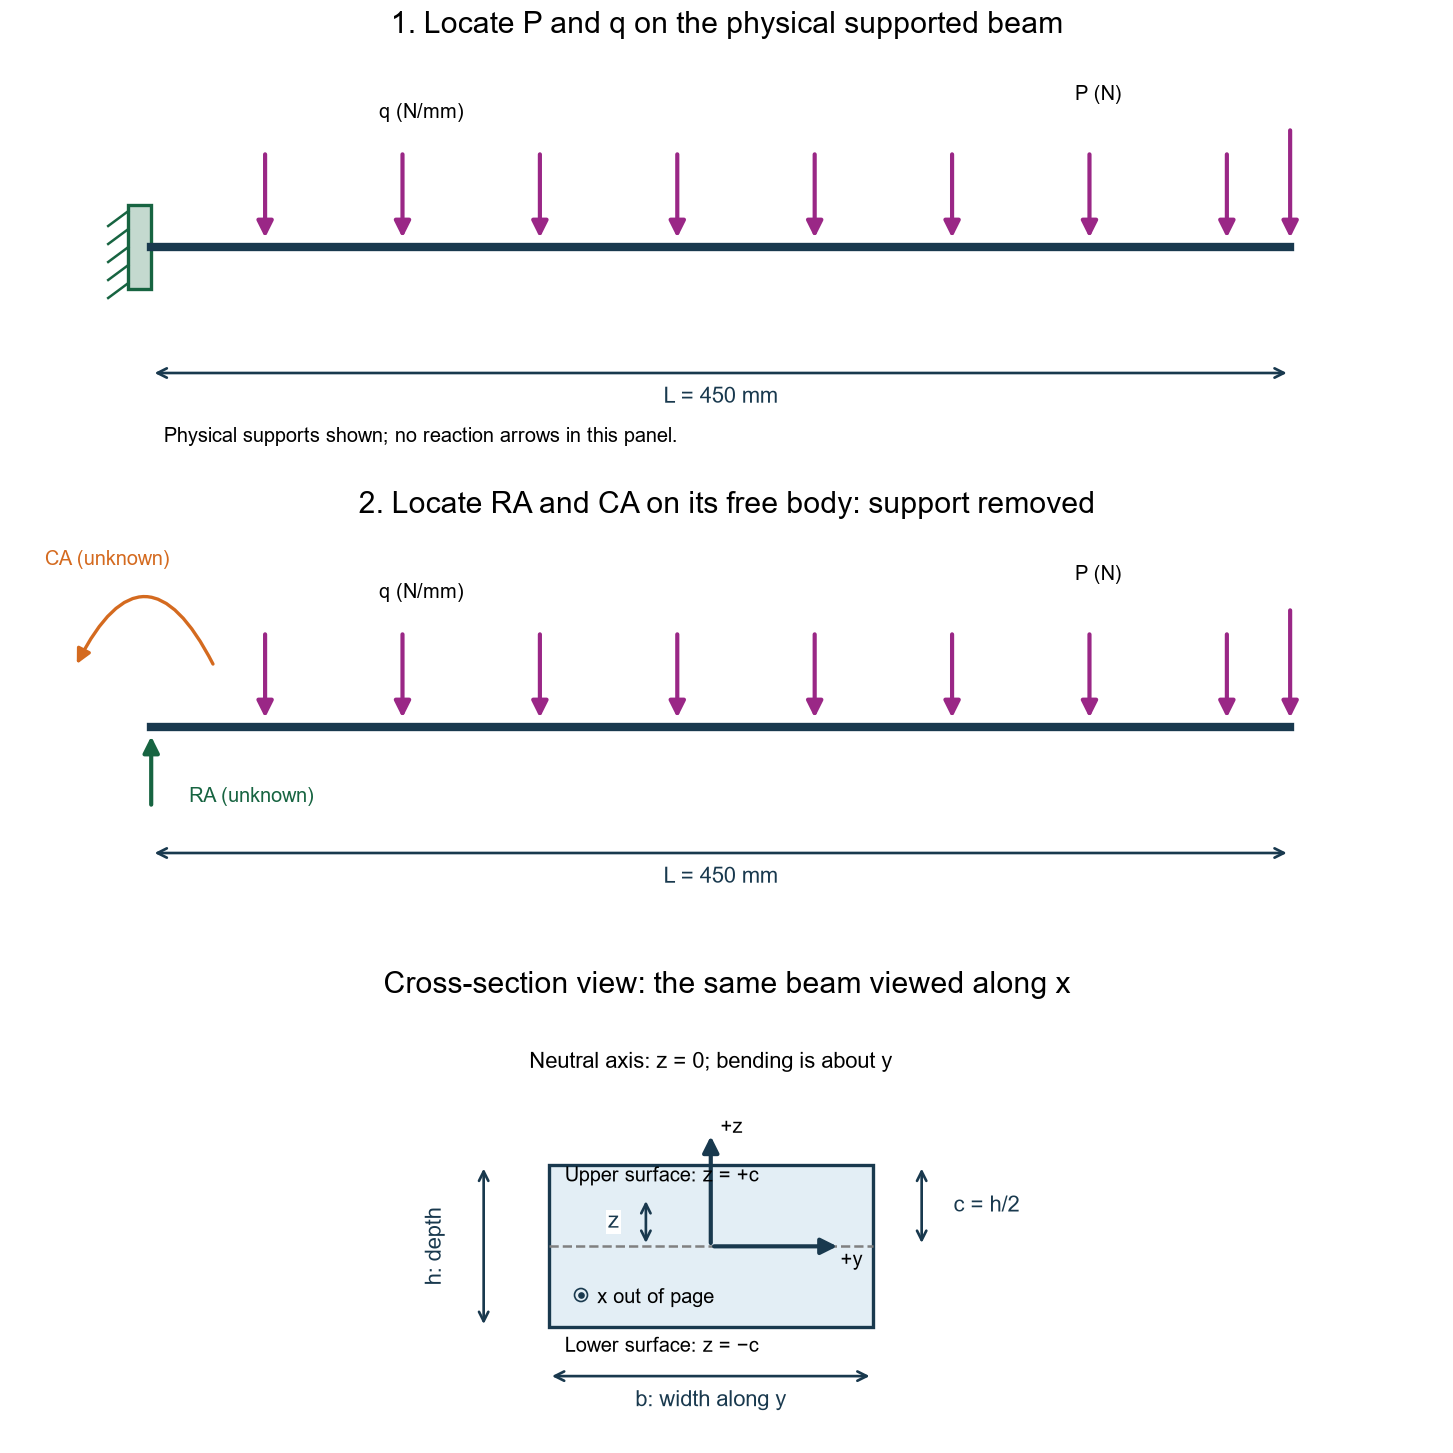

In [2]:
#@title Figure 0A — physical loads, their free body and section dimensions
fig,axes=plt.subplots(3,1,figsize=(12,12),layout='constrained')
beam_system_or_fbd(axes[0],'cantilever','1. Locate P and q on the physical supported beam',station=L,generic=True)
beam_system_or_fbd(axes[1],'cantilever','2. Locate RA and CA on its free body: support removed',station=L,generic=True,fbd=True)
ax=axes[2]

ax.add_patch(Rectangle((-10,-5),20,10,facecolor='#e3eef5',edgecolor='#19394e',lw=2))
ax.plot([-10,10],[0,0],'--',color='gray')
dimension(ax,(-10,-8),(10,-8),'b: width along y',(0,-1.5))
dimension(ax,(-14,-5),(-14,5),'h: depth',(-3,0),rotation=90)
dimension(ax,(13,0),(13,5),'c = h/2',(4,0))
dimension(ax,(-4,0),(-4,3),'z',(-2,0))
arrow(ax,(0,0),(0,7),'#19394e');ax.text(.6,7,'+z',fontsize=12)
arrow(ax,(0,0),(8,0),'#19394e');ax.text(8,-1.2,'+y',fontsize=12)
ax.add_patch(Circle((-8,-3),.4,fill=False,color='#19394e'));ax.plot(-8,-3,'.',color='#19394e')
ax.text(-7,-3.5,'x out of page',fontsize=12)
ax.text(-9,4,'Upper surface: z = +c',fontsize=12)
ax.text(-9,-6.5,'Lower surface: z = −c',fontsize=12)
ax.text(0,11,'Neutral axis: z = 0; bending is about y',ha='center',fontsize=13)
ax.set(xlim=(-22,24),ylim=(-12,15),title='Cross-section view: the same beam viewed along x')
ax.set_aspect('equal');ax.axis('off')

plt.show()

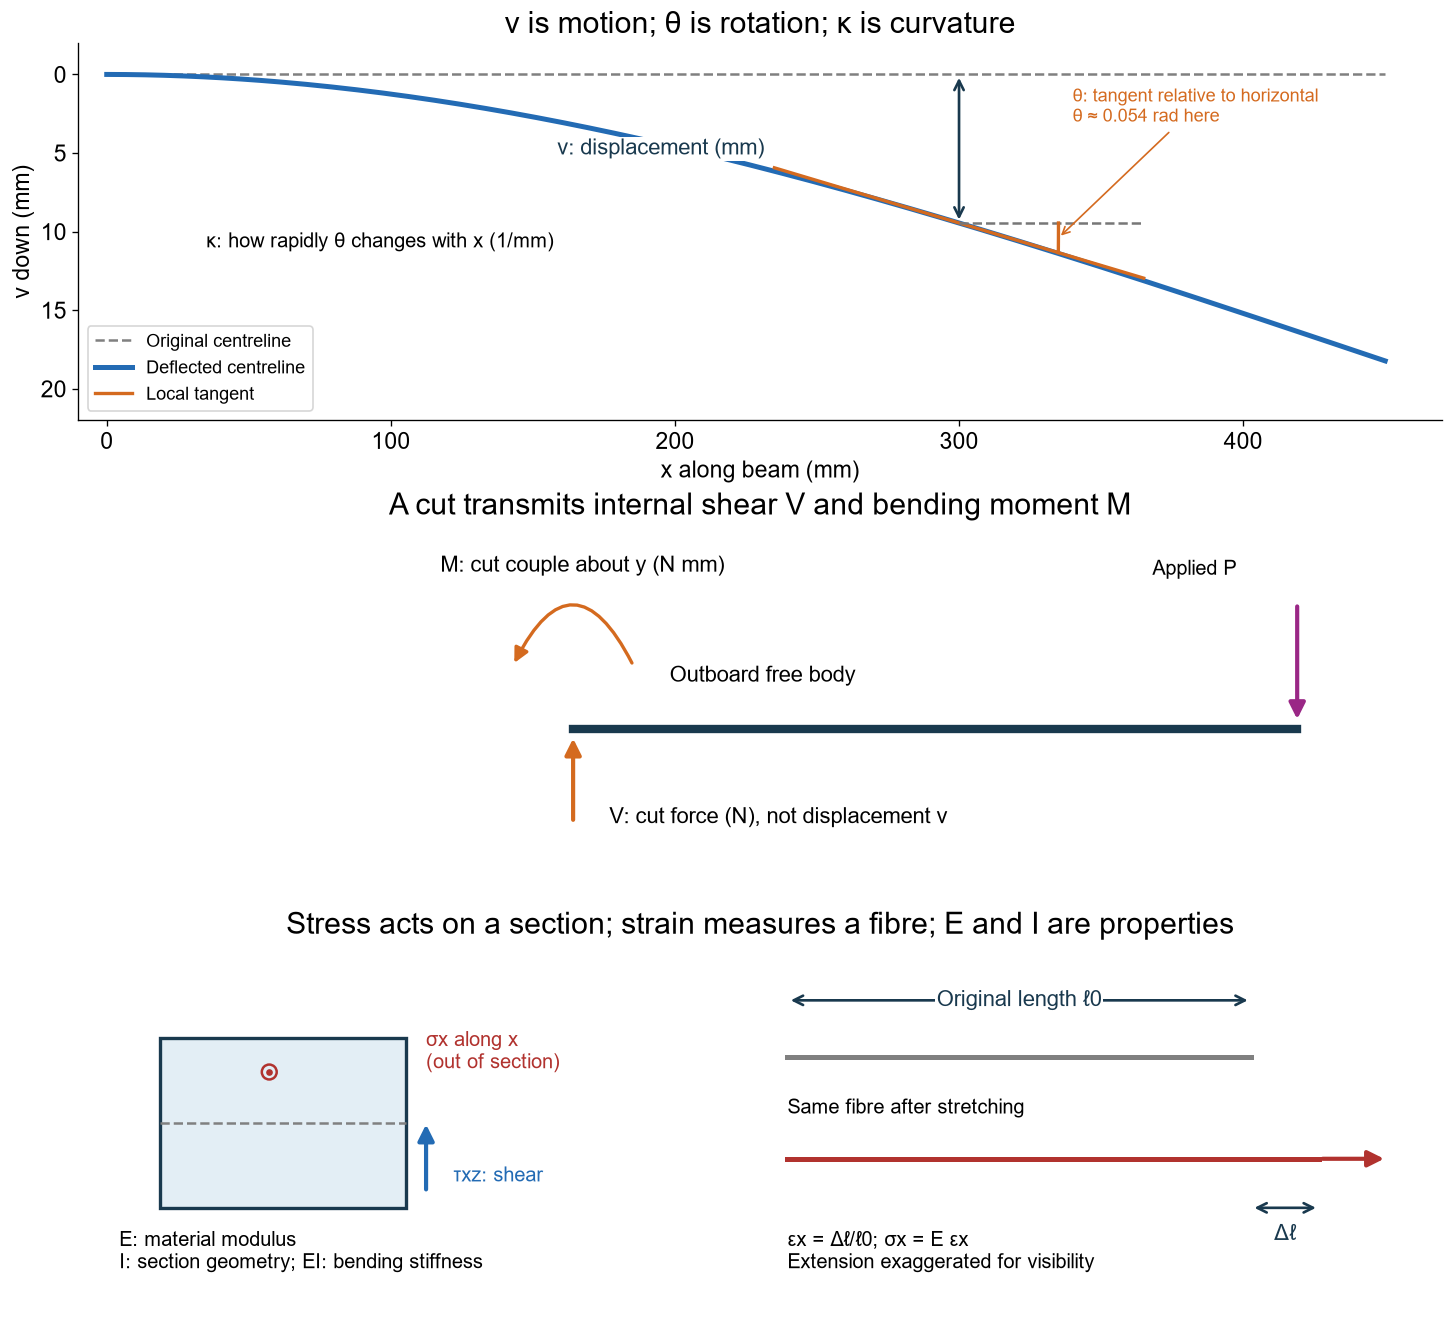

In [3]:
#@title Figure 0B — motion, internal actions and stress are different quantities
fig,axes=plt.subplots(3,1,figsize=(12,11),layout='constrained')
ax=axes[0]
xs=np.linspace(0,L,200); motion=P*xs**2*(3*L-xs)/(6*EI)
ax.plot(xs,np.zeros_like(xs),'--',color='gray',label='Original centreline')
ax.plot(xs,motion,color='#236bb4',lw=3,label='Deflected centreline')
at=300.; vt=P*at**2*(3*L-at)/(6*EI); slope=P*at*(2*L-at)/(2*EI)
ax.plot([at-65,at+65],[vt-65*slope,vt+65*slope],color='#d46a1f',lw=2,label='Local tangent')
ax.plot([at,at+65],[vt,vt],'--',color='#777777',lw=1.5)
aa=np.linspace(0,np.arctan(slope),50)
ax.plot(at+35*np.cos(aa),vt+35*np.sin(aa),color='#d46a1f',lw=2)
dimension(ax,(at,0),(at,vt),'v: displacement (mm)',(-105,0))
ax.annotate('θ: tangent relative to horizontal\nθ ≈ 0.054 rad here',
            xy=(at+35,vt+.95),xytext=(340,3),fontsize=11,color='#d46a1f',
            arrowprops=dict(arrowstyle='->',color='#d46a1f'))
ax.text(35,11,'κ: how rapidly θ changes with x (1/mm)',fontsize=12)
ax.set(xlim=(-10,470),ylim=(-2,22),title='v is motion; θ is rotation; κ is curvature')
ax.invert_yaxis();ax.set_xlabel('x along beam (mm)');ax.set_ylabel('v down (mm)');ax.legend(fontsize=11,loc='lower left')
ax=axes[1]
clean_beam(ax,'A cut transmits internal shear V and bending moment M')
ax.lines[0].remove();ax.plot([150,L],[0,0],lw=5,color='#19394e')
arrow(ax,(150,-30),(150,-2),'#d46a1f')
ax.text(165,-30,'V: cut force (N), not displacement v',fontsize=13)
ax.add_patch(FancyArrowPatch((175,20),(125,20),connectionstyle='arc3,rad=1',
                            arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
ax.text(95,50,'M: cut couple about y (N mm)',fontsize=13)
arrow(ax,(L,40),(L,2));ax.text(390,49,'Applied P',fontsize=12)
ax.text(190,15,'Outboard free body',fontsize=13)
ax=axes[2];ax.set(xlim=(0,1),ylim=(0,1));ax.axis('off')
ax.set_title('Stress acts on a section; strain measures a fibre; E and I are properties')
ax.add_patch(Rectangle((.06,.30),.18,.45,facecolor='#e3eef5',edgecolor='#19394e',lw=2))
ax.plot([.06,.24],[.525,.525],'--',color='gray')
ax.scatter([.14],[.66],s=80,facecolors='none',edgecolors='#b1322e',linewidths=1.5)
ax.plot(.14,.66,'.',color='#b1322e')
ax.text(.255,.67,'σx along x\n(out of section)',fontsize=12,color='#b1322e')
arrow(ax,(.255,.34),(.255,.53),'#236bb4')
ax.text(.275,.37,'τxz: shear',fontsize=12,color='#236bb4')
ax.text(.03,.14,'E: material modulus\nI: section geometry; EI: bending stiffness',fontsize=12)
ax.plot([.52,.86],[.70,.70],color='gray',lw=3)
ax.plot([.52,.91],[.43,.43],color='#b1322e',lw=3)
dimension(ax,(.52,.85),(.86,.85),'Original length ℓ0')
dimension(ax,(.86,.30),(.91,.30),'Δℓ',(0,-.07))
arrow(ax,(.91,.43),(.96,.43),'#b1322e')
ax.text(.52,.55,'Same fibre after stretching',fontsize=12)
ax.text(.52,.14,'εx = Δℓ/ℓ0; σx = E εx\nExtension exaggerated for visibility',fontsize=12)
plt.show()

### Reference table for the drawings above

**x** is distance along the beam, starting at the root. **z** is height in a cross-section, measured upward from its neutral axis. **y** is the transverse width direction. **v** is displacement downward, whereas **V** is the internal shear force. Neither is the flight speed in this lesson.

| Symbol | Meaning | Unit | Where it appears |
|---|---|---|---|
| L, x | Full length and cut station | mm | Side view |
| b, h | Section width and vertical depth | mm | Cross-section |
| c = h/2, z | Extreme-fibre distance and a selected fibre height | mm | Cross-section |
| P, q | Point force and distributed force per length | N, N/mm | Load drawing |
| Rₐ, Cₐ | Root force and root reaction couple | N, N mm | Whole-beam free body |
| V, M | Internal shear and signed sagging bending moment | N, N mm | A cut and diagrams |
| E, I, EI | Material modulus, second moment of area and bending stiffness | MPa, mm⁴, N mm² | Section and curvature calculation |
| εₓ, σₓ, τₓz | Longitudinal strain, longitudinal stress and transverse shear stress | dimensionless, MPa, MPa | Material fibres and stress profiles |
| v, θ, κ | Displacement, slope/rotation and curvature | mm, rad, 1/mm | Deflected beam |

Use the figure first, then the equation, then the numerical substitution. A subscript names a direction or station; it is not an extra multiplier. The figure dimensions are teaching inputs, not measured properties of the full course wing.

Figures 0A and 0B locate these symbols in views of the beam and its section. Figure 0A illustrates possible point and distributed loads; Example A below uses only the point force. Blue shows motion, purple shows applied loading, green shows support actions, and orange shows cut actions or a local tangent. Material properties and section stiffness are not extra applied forces.

## 1. What a support prevents and what it can transmit

A reaction is the force or moment that a support exerts to enforce a restricted motion. Do not draw a reaction moment at an ideal pin or roller: these allow rotation. A fixed support restricts rotation as well as translation.

| Ideal support in a planar model | Prevented motion | Reaction unknowns | Motion still allowed |
|---|---|---|---|
| Pin | Horizontal and vertical translation | R_x,R_z | Rotation |
| Roller on a horizontal surface | Vertical translation | R_z | Horizontal translation and rotation |
| Fixed clamp | Both translations and rotation | R_x,R_z,M_A | None at the support |
| Free end | None | No support reaction | Translation and rotation |

These are idealizations, not descriptions of every bolt or bearing. A real wing attachment uses multiple fittings to transmit forces and a couple. In our **transverse-bending app**, only displacement v and slope θ are solved: axial displacement is not a degree of freedom. Under purely transverse loading the planar horizontal reaction is zero, not an additional solved app result.

For a whole planar free body:

$$\sum F_x=0,\qquad \sum F_z=0,\qquad \sum M=0.$$

A pin–roller beam has three planar reaction unknowns and three equilibrium equations. Two fixed ends have six planar unknowns: equilibrium alone is insufficient. In transverse bending, four reactions (R_A,M_A,R_B,M_B) need two equilibrium equations **plus displacement/rotation compatibility and stiffness**. Here no axial load is applied; the separate axial redundancy is outside the transverse model.

**How to draw a reaction:** imagine the support removed, leaving only the beam. Replace each motion that was prevented by a possible force or couple. Initially assume a direction; a negative solution means the real direction is opposite. The fixed support requires a couple because it prevents the end section rotating. A pin lets that section rotate, so an ideal pin has no reaction couple.

For our transverse cantilever, two nonzero reaction unknowns are enough: the vertical root force and the root couple. Taking moments about the root removes the root force from that equation because its lever arm is zero. For a pin–roller beam, taking moments about A first determines the reaction at B; vertical equilibrium then determines A.

### 1.1 Pin and roller are not the same support

Think about three separate motions at a point on a planar beam:

1. **Axial translation uₓ:** sliding horizontally along the beam.
2. **Vertical translation v:** moving up or down.
3. **Rotation θ:** turning the beam cross-section.

An ideal **pin** prevents both translations but permits rotation. It can exert two force components, Rₓ and Rᵥ, but no reaction couple. A **frictionless roller on horizontal ground** prevents vertical translation only. It permits horizontal sliding and rotation, and supplies only a vertical reaction Rᵥ. The two circles under its triangle identify the roller; a triangle directly on the ground identifies a pin.

| Support | Axial movement uₓ | Vertical movement v | Rotation θ | Possible planar reactions |
|---|---|---|---|---|
| Pin | Restrained | Restrained | Free | Rₓ and Rᵥ |
| Horizontal roller | Free | Restrained | Free | Rᵥ only |
| Fixed clamp | Restrained | Restrained | Restrained | Rₓ, Rᵥ and C |

**Free rotation does not mean zero rotation.** It means the support does not prescribe the rotation. A loaded pin–roller beam usually has nonzero end slopes even though both end displacements are zero. Zero reaction couple is not the same as zero slope.

The roller reaction is normal to the supporting surface. On an inclined surface it is generally not vertical. We use horizontal supporting surfaces here.


### Configure the software: one Beam workspace

Open [Beam Lab](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html). Under **Supports & hinges**, select **Left end** and **Right end** independently (fixed, pin, roller or free), then press **Solve**. Until you solve, the status reads *Pending* and the results shown still belong to the previous model. Support pictures identify your choices. Loads are preserved when supports change.

- Cantilever: left fixed, right free. Reverse these for a right-hand clamp.
- Simply supported: one pin and one roller; HW 3 uses left roller, right pin.
- Fixed–fixed: both fixed. A fixed–pin or fixed–roller beam is also possible, but needs displacement compatibility as well as equilibrium.
- Optional: interior supports and internal hinges (the **+** buttons, or **Place** on the beam picture). A stability line reports whether the arrangement is determinate or indeterminate; an arrangement that leaves a mechanism is rejected.
- Free–free and single-pin/free combinations are mechanisms and are rejected. Two rollers leave axial rigid-body motion and are rejected. Pin–pin is a **vertical-bending-only** idealization: this model does not calculate axial redundancy or thermal stress.

After each change, compare reactions, end displacement and rotation, shear, moment and stress. The reaction table uses positive downward force and clockwise couple. HW 3 students enter all model inputs themselves. Lecture example links remain available for the separate teaching examples, not for the assigned models.


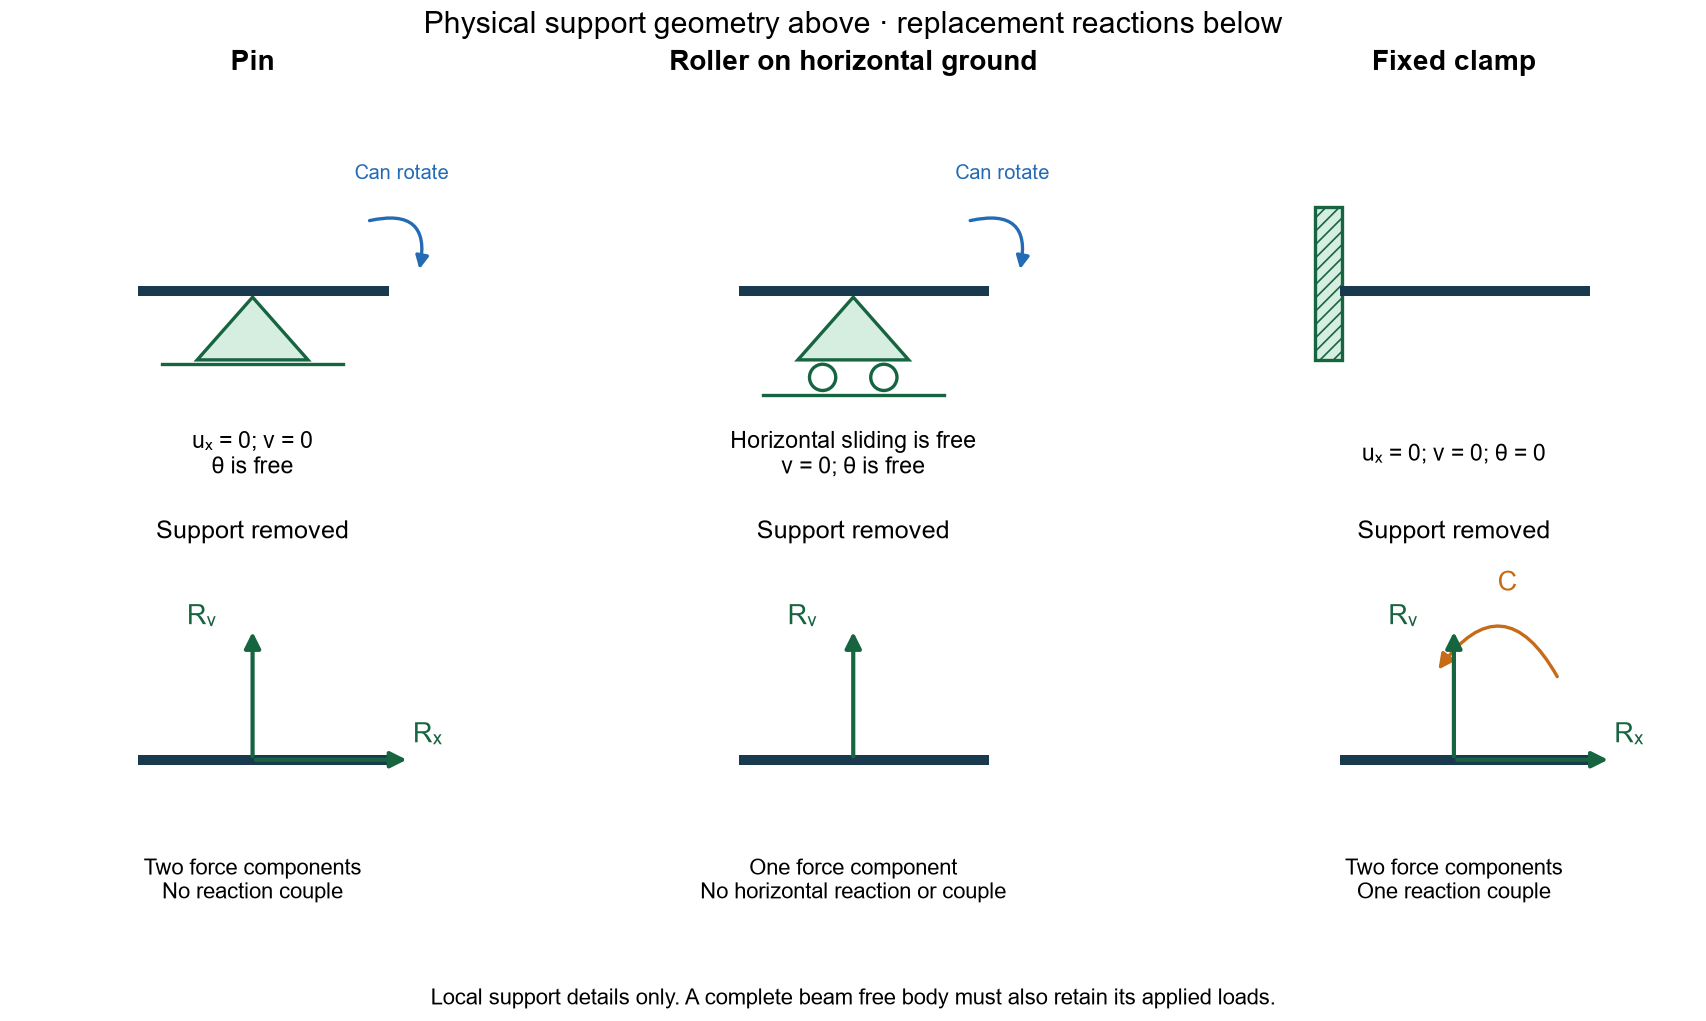

In [4]:
#@title Figure 1S — pin, roller and clamp; geometry first, replacement reactions second
fig, axes = plt.subplots(2, 3, figsize=(15, 8.4), layout='constrained')
support_names = ['Pin', 'Roller on horizontal ground', 'Fixed clamp']
for j, name in enumerate(support_names):
    for row in (0, 1):
        ax = axes[row, j]
        ax.set(xlim=(-1.65, 1.65), ylim=(-1.15, 1.8), aspect='equal')
        ax.axis('off')
        ax.plot([-.75, .9], [.35, .35], color='#19394e', lw=6)
        if row == 0:
            ax.set_title(name, fontsize=17, weight='bold')
            if j < 2:
                ax.add_patch(Polygon([[0,.31],[-.38,-.12],[.38,-.12]],
                                     facecolor='#d6eee0',edgecolor='#176441',lw=2))
                ground = -.15
                if j == 1:
                    for dx in [-.21,.21]:
                        ax.add_patch(Circle((dx,-.24),.09,facecolor='white',edgecolor='#176441',lw=2))
                    ground = -.36
                ax.plot([-.62,.62],[ground,ground],color='#176441',lw=2)
            else:
                ax.add_patch(Rectangle((-.95,-.12),.18,1.05,facecolor='#d6eee0',
                                       edgecolor='#176441',hatch='///',lw=2))
            free_text = ['uₓ = 0; v = 0\nθ is free',
                         'Horizontal sliding is free\nv = 0; θ is free',
                         'uₓ = 0; v = 0; θ = 0'][j]
            ax.text(0,-.77,free_text,ha='center',va='center',fontsize=14)
            if j < 2:
                ax.add_patch(FancyArrowPatch((.78,.83),(1.14,.48),
                             connectionstyle='arc3,rad=-.8',arrowstyle='-|>',
                             mutation_scale=16,color='#236bb4',lw=2))
                ax.text(.7,1.12,'Can rotate',fontsize=12,color='#236bb4')
        else:
            ax.set_title('Support removed',fontsize=15)
            arrow(ax,(0,.35),(0,1.25),'#176441')
            ax.text(-.45,1.28,'Rᵥ',fontsize=16,color='#176441')
            if j != 1:
                arrow(ax,(0,.35),(1.08,.35),'#176441')
                ax.text(1.1,.47,'Rₓ',fontsize=16,color='#176441')
            if j == 2:
                ax.add_patch(FancyArrowPatch((.72,.90),(-.12,.95),
                             connectionstyle='arc3,rad=.8',arrowstyle='-|>',
                             mutation_scale=19,color='#c66b18',lw=2))
                ax.text(.3,1.51,'C',fontsize=16,color='#c66b18')
            ax.text(0,-.48,['Two force components\nNo reaction couple',
                            'One force component\nNo horizontal reaction or couple',
                            'Two force components\nOne reaction couple'][j],
                    ha='center',va='center',fontsize=13)
fig.suptitle('Physical support geometry above · replacement reactions below',fontsize=18)
fig.supxlabel('Local support details only. A complete beam free body must also retain its applied loads.',fontsize=13)
plt.show()


### Interior support is not an internal hinge

The four end choices (fixed, pin, roller and free) are not four limits on beam configuration. A pin, roller or clamp can also be placed at an **interior station**. The beam may continue beyond the support as an overhang.

| Feature at x = a | Vertical displacement | Rotation | External reaction | Internal bending moment |
|---|---|---|---|---|
| Grounded interior pin or roller on a continuous beam | v(a) = 0 | One continuous, unknown rotation | Vertical force; no external couple | Generally not zero; continuous if no point couple acts |
| Grounded interior clamp | v(a) = 0 | θ(a) = 0 | Force and external couple | May jump across its reaction couple |
| Internal hinge joining two beam pieces | Same displacement on both pieces; not necessarily zero | Left and right rotations may differ | No ground reaction unless separately supported | M(a⁻) = M(a⁺) = 0, with no applied hinge couple |

**A grounded pin does not cut the beam or release its bending continuity.** Its zero external reaction couple does not require the internal moment of a continuous beam to vanish there. An internal hinge is a connection between two pieces, not a support attached to ground. The drawings below show physical supports and applied loads only; reaction arrows belong in a separate free-body drawing.

In Beam Lab use **+ Interior support**, choose its kind and x, or select **Place → Pin / Roller / Fixed** and click the beam. Move the support with its handle or enter x numerically. Use **+ Internal hinge** or **Place → Hinge** for a genuine rotation release. Read the stability message and solve again. An internal hinge can create a mechanism; additional restraints are not optional if needed for stability. These capabilities are optional exploration and add no tasks to HW 3.

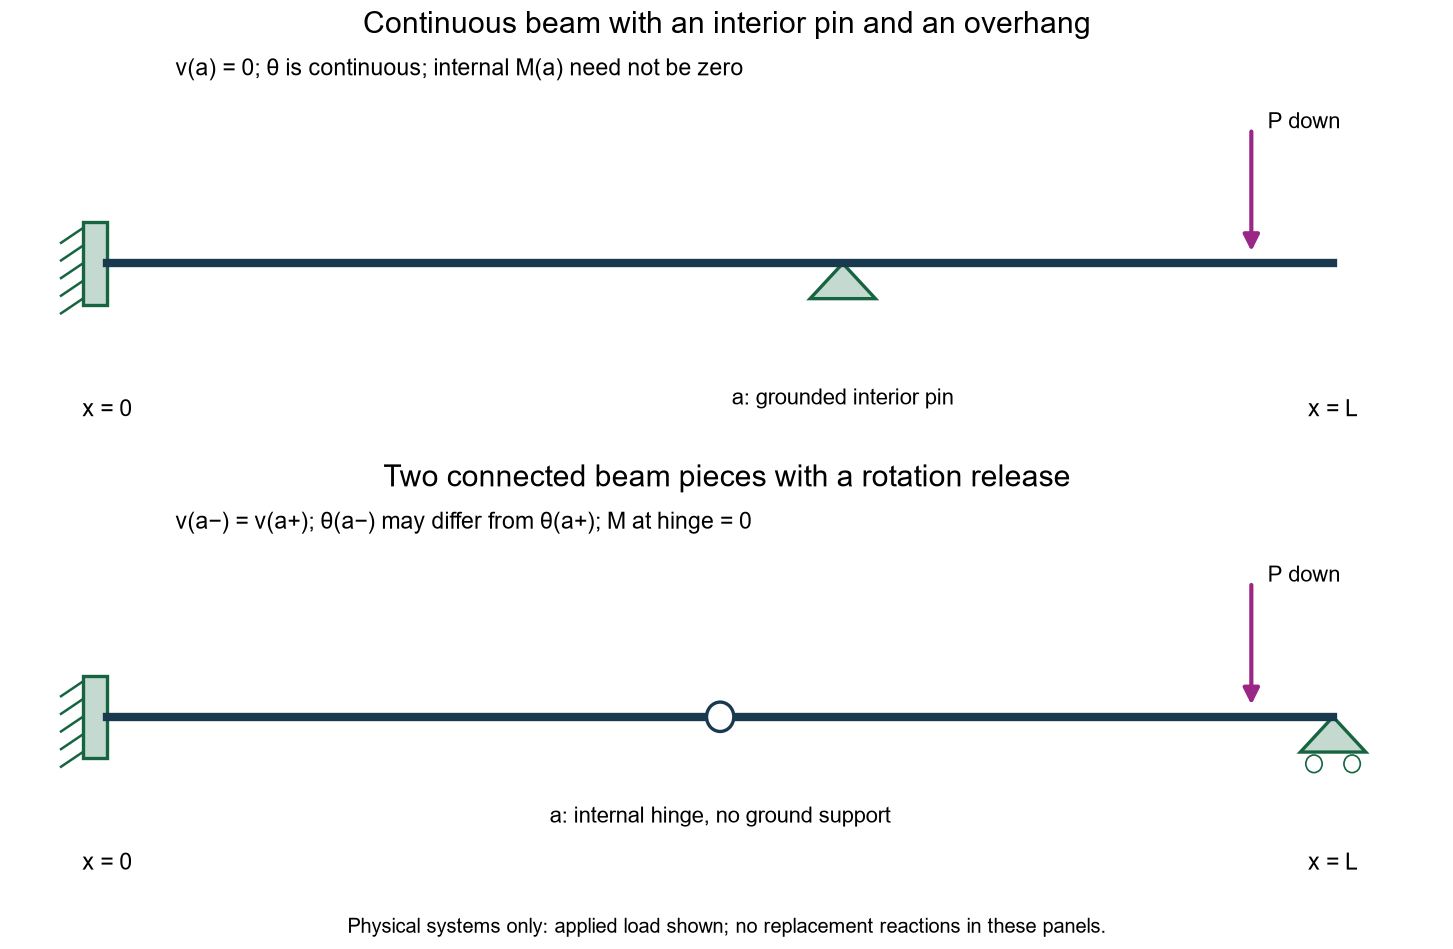

In [5]:
#@title Figure 1I — grounded interior support versus internal connection
fig, axes = plt.subplots(2, 1, figsize=(12, 7.8), layout='constrained')
for ax in axes:
    ax.set(xlim=(-35,490), ylim=(-65,75)); ax.axis('off')
    ax.plot([0,450],[0,0],lw=5,color='#19394e')
    support(ax,0,'fixed')
    arrow(ax,(420,46),(420,3)); ax.text(426,46,'P down',fontsize=13)
    ax.text(0,-52,'x = 0',ha='center'); ax.text(450,-52,'x = L',ha='center')
support(axes[0],270,'pin')
axes[0].text(270,-48,'a: grounded interior pin',ha='center',fontsize=13)
axes[0].set_title('Continuous beam with an interior pin and an overhang')
axes[0].text(25,64,'v(a) = 0; θ is continuous; internal M(a) need not be zero',fontsize=14)
# A stable hinged arrangement: left clamp, hinge, right roller.
support(axes[1],450,'roller')
axes[1].add_patch(Circle((225,0),5,facecolor='white',edgecolor='#19394e',lw=2,zorder=4))
axes[1].text(225,-36,'a: internal hinge, no ground support',ha='center',fontsize=13)
axes[1].set_title('Two connected beam pieces with a rotation release')
axes[1].text(25,64,'v(a−) = v(a+); θ(a−) may differ from θ(a+); M at hinge = 0',fontsize=14)
fig.supxlabel('Physical systems only: applied load shown; no replacement reactions in these panels.',fontsize=12)
plt.show()

### 1.2 Why the bending app can give the same answer after swapping the pin and roller

- A complete pin–roller beam has three planar reaction unknowns: two components at the pin and one at the roller. The pin prevents the whole beam from sliding horizontally; two horizontal rollers alone would not do that.
- Apply only vertical loads: horizontal equilibrium gives zero horizontal reaction. This does **not** turn the pin into a roller; the pin still restrains axial translation.
- Apply an additional horizontal force: the pin can provide the balancing horizontal reaction; an ideal horizontal roller cannot. A beam with two pins also restrains axial movement at both ends and is not generally equivalent under axial load or thermal expansion.
- Our app solves **vertical bending only**, with v and θ at each node. It does not solve uₓ, axial deformation, inclined rollers or general frame behavior. It must not be used to infer an axial reaction under horizontal loading.
- For the vertical loads in HW 3, both the pin and roller enforce v = 0 and allow θ to be determined by the beam. Swapping the pin and roller leaves the vertical reactions, deflection and slopes unchanged. It changes the location of axial restraint, not the transverse-bending equations.
- In the app, choose **Left roller / right pin** for HW 3 Case 2. Read v and θ in the **Support reactions and motion** table. At a pin or roller, v = 0 and the reaction couple is zero, but θ may be nonzero.
- The app reports positive reaction force downward and positive reaction couple clockwise. Use the same signs in the hand solution and app: force downward positive, external couple clockwise positive, displacement downward positive. Negative results identify the opposite physical direction.


## 2. Calculate support reactions under the same load

Use L = 450 mm and P = 2 N downward at a = L/2 = 225 mm in all three comparison drawings. Hand calculations and the app both use downward-positive reactions and clockwise-positive external couples. Negative force means upward; negative external couple means counterclockwise (CCW). Internal M is separately sagging-positive.

**These are external support reactions.** Internal section moment M later uses the separate sagging-positive convention. Do not replace the signs of support couples by signs from the internal-moment diagram.

**Two drawings, two roles:** first draw the supported physical system with applied loads only. Next isolate the same beam, remove every support symbol and replace it by the relevant reaction force/couple. Keep the applied loads on that free body. Equilibrium equations below the pair refer to the second drawing. A load-only drawing is not a complete free body.

### 2A. One fixed end — centre load

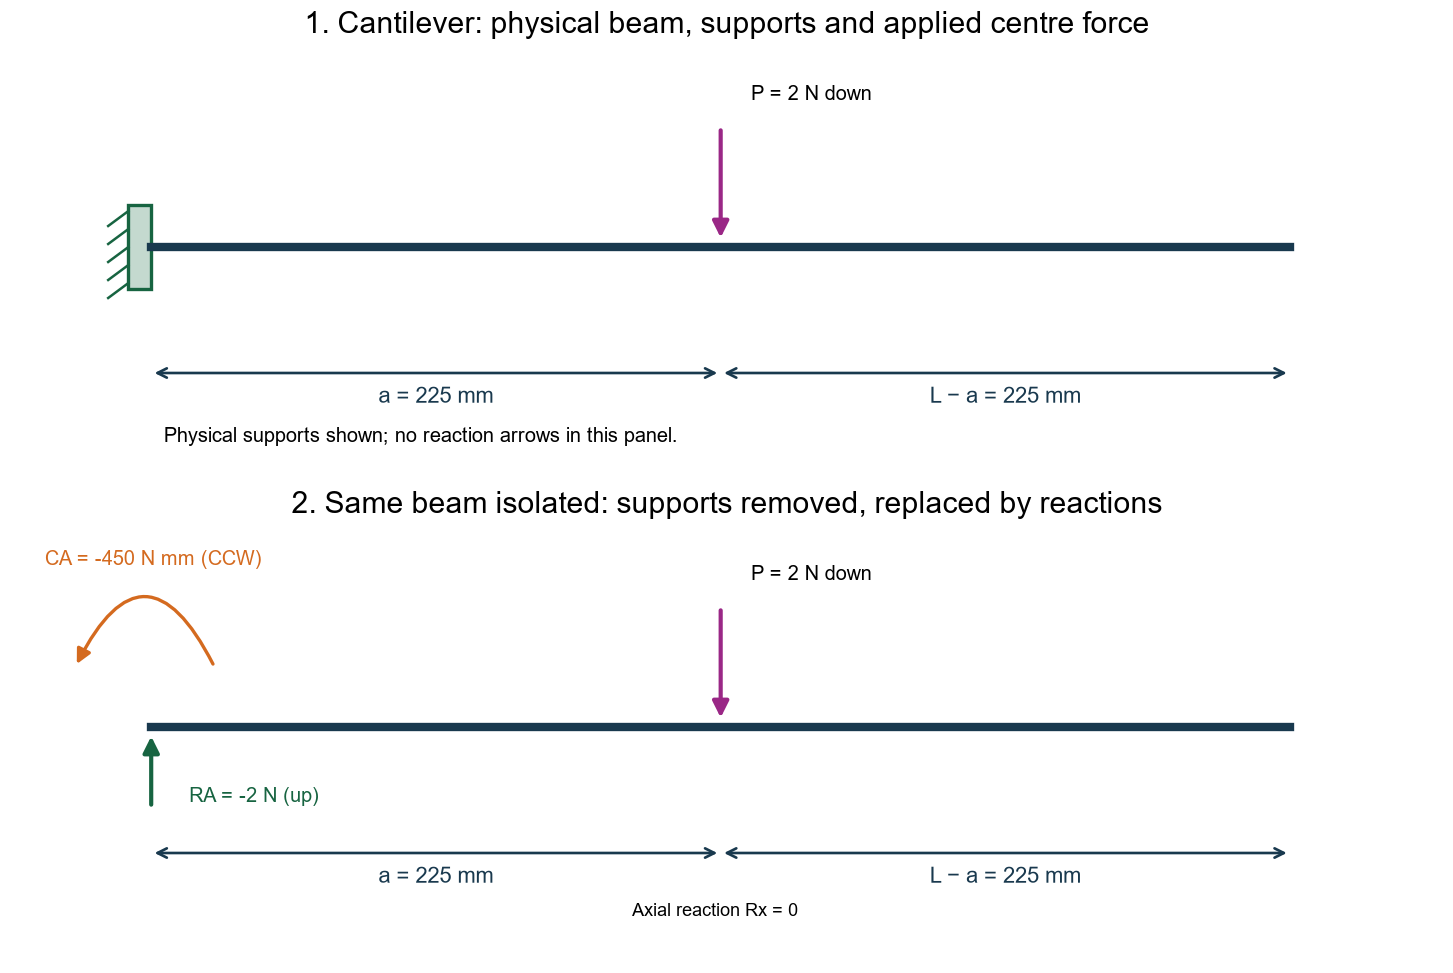

In [6]:
#@title Figure 1A — supported system first, free body second
fig,axes=plt.subplots(2,1,figsize=(12,8),layout='constrained')
beam_system_or_fbd(axes[0],'cantilever','1. Cantilever: physical beam, supports and applied centre force')
beam_system_or_fbd(axes[1],'cantilever','2. Same beam isolated: supports removed, replaced by reactions',fbd=True)
plt.show()

The free end is not a support, so it contributes no reaction. At A, horizontal force balance gives Rₓ = 0. Vertical balance and moments about A give:

$$\sum F_z=0:\quad R_A+2=0\quad\Longrightarrow R_A=-2\ \mathrm{N}\quad(\mathrm{upward}),$$

$$\sum M_A=0:\quad C_A+2(225)=0\quad\Longrightarrow C_A=-450\ \mathrm{N\,mm}\quad(\mathrm{CCW}).$$

There are two transverse reaction unknowns and two equilibrium equations. The app reports −2 N and −450 N mm. Changing the load station changes its moment arm, not the number of reaction unknowns.

**[Open this exact beam study: cantilever with the 2 N centre force](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-centre)**. The link replaces the old study with these inputs and solves it.

#### Example A belongs to this cantilever — move the same force to the tip

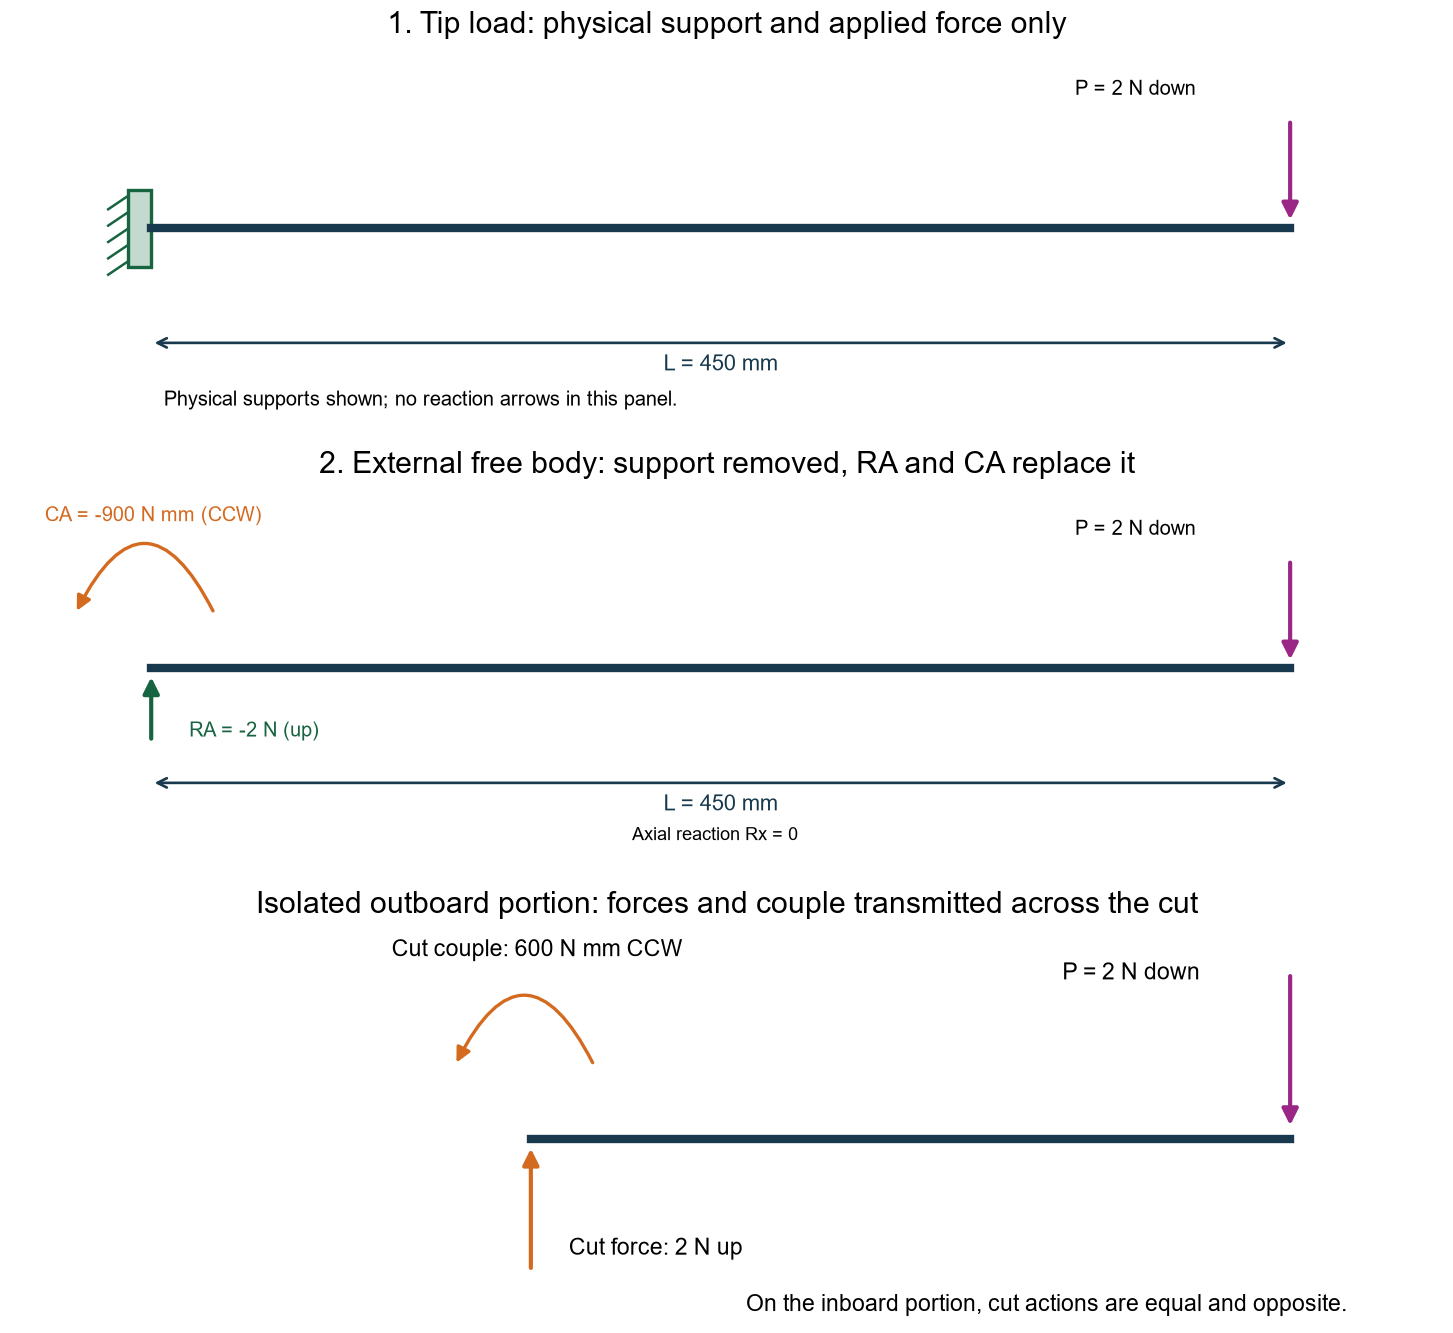

In [7]:
#@title Figure 2 — physical tip-load system, external free body, isolated cut
fig,panels=plt.subplots(3,1,figsize=(12,11),layout='constrained')
beam_system_or_fbd(panels[0],'cantilever','1. Tip load: physical support and applied force only',station=L)
beam_system_or_fbd(panels[1],'cantilever','2. External free body: support removed, RA and CA replace it',station=L,fbd=True)
ax=panels[2]

clean_beam(ax,'Isolated outboard portion: forces and couple transmitted across the cut')
ax.lines[0].remove()
ax.plot([150,L],[0,0],color='#19394e',lw=5)
arrow(ax,(L,50),(L,3)); ax.text(360,48,'P = 2 N down')
arrow(ax,(150,-40),(150,-2),'#d46a1f'); ax.text(165,-35,'Cut force: 2 N up')
ax.add_patch(FancyArrowPatch((175,22),(120,22),connectionstyle='arc3,rad=1',arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
ax.text(95,55,'Cut couple: 600 N mm CCW')
ax.text(235,-52,'On the inboard portion, cut actions are equal and opposite.')

plt.show()

This drawing now has a = L = 450 mm. The applied force is unchanged, but its lever arm doubles:

$$R_A+P=0,\qquad C_A+PL=0.$$

Thus Rₐ = −2 N (upward) and Cₐ = −900 N mm (CCW). The app gives −2 N and −900 N mm. At the cut x = 150 mm, the remaining arm is 300 mm and the cut couple magnitude is 600 N mm. These are the actions shown on the separate outboard free body.

**[Open this exact beam study: Example A: 2 N at the free tip](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-tip)**. The link replaces the old study with these inputs and solves it.

#### Example B belongs to this cantilever — spread the same 2 N along the span

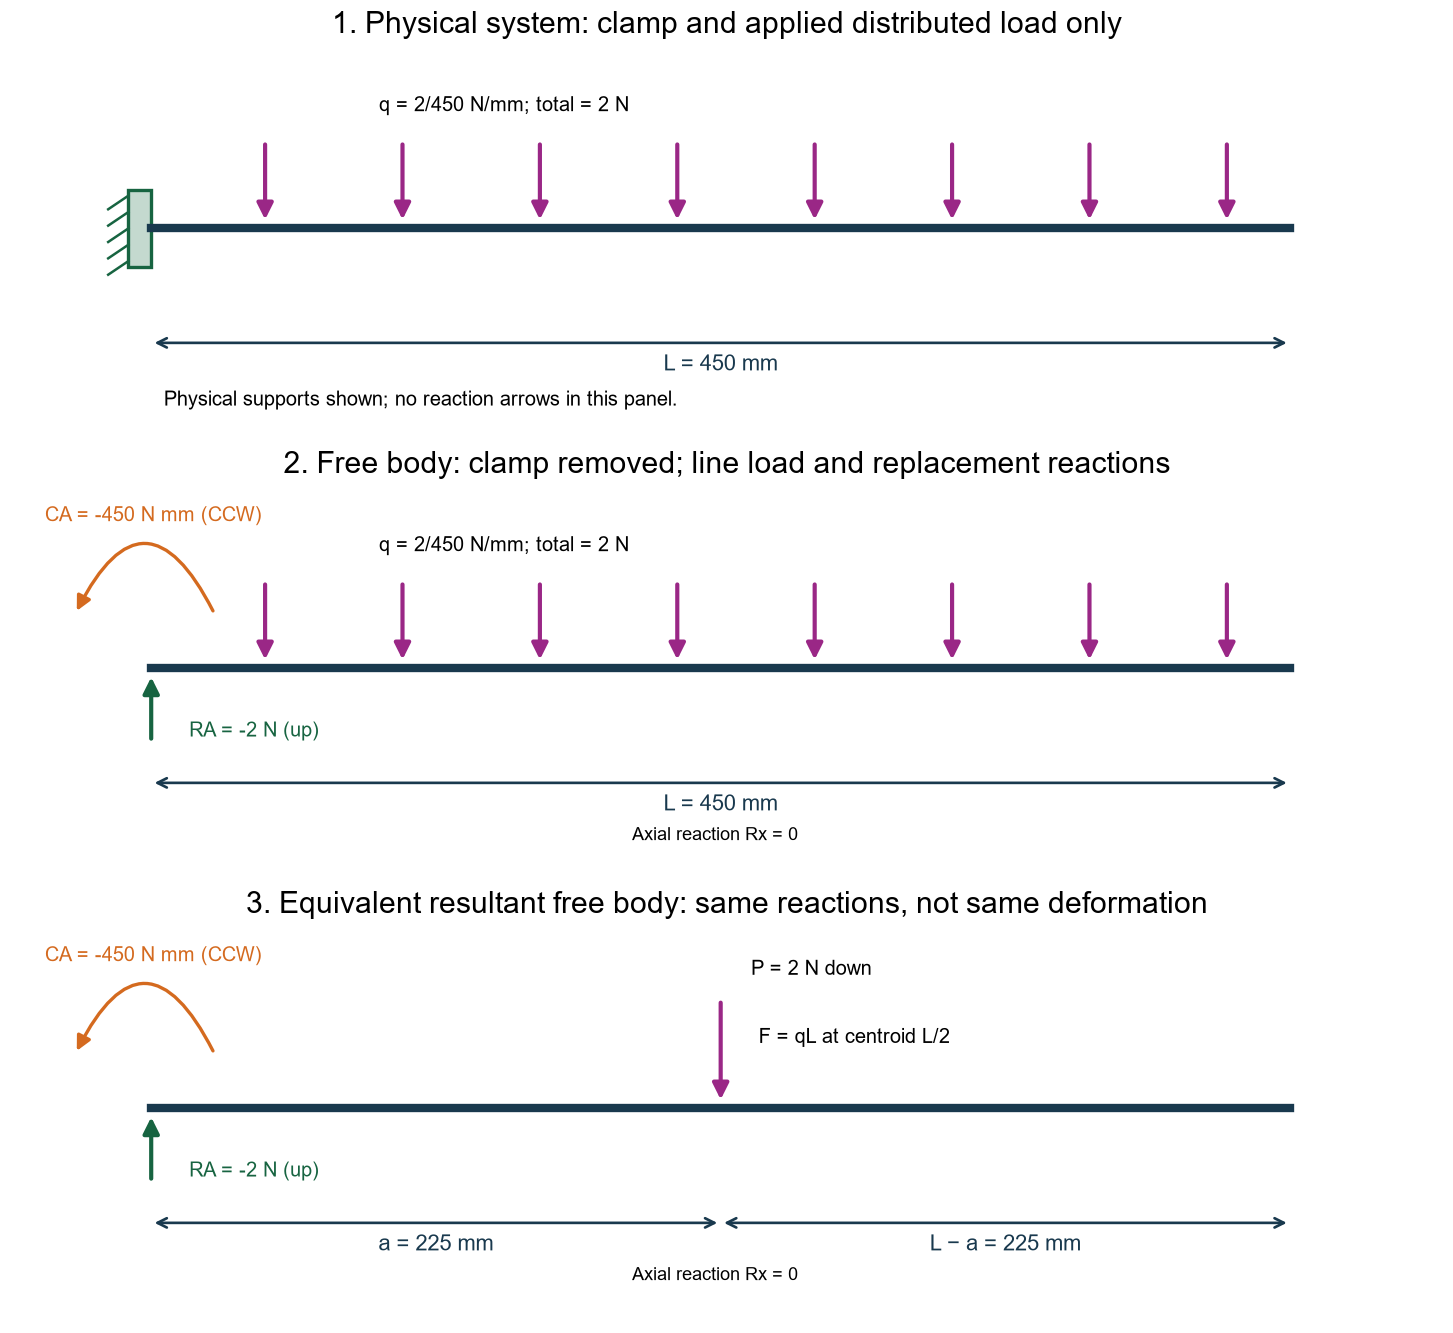

In [8]:
#@title Figure 6A — uniform-load system and two valid free-body representations
fig,axes=plt.subplots(3,1,figsize=(12,11),layout='constrained')
beam_system_or_fbd(axes[0],'cantilever','1. Physical system: clamp and applied distributed load only',uniform=True)
beam_system_or_fbd(axes[1],'cantilever','2. Free body: clamp removed; line load and replacement reactions',uniform=True,fbd=True)
beam_system_or_fbd(axes[2],'cantilever','3. Equivalent resultant free body: same reactions, not same deformation',station=L/2,fbd=True)
axes[2].text(240,24,'F = qL at centroid L/2',fontsize=12)
plt.show()

For a uniform line load q = 2/450 = 0.00444444 N/mm, the area under q is F = qL = 2 N. Its centroid lies at L/2:

$$R_A+qL=0,\qquad C_A+(qL)\frac{L}{2}=0.$$

Therefore Rₐ = −2 N (upward) and Cₐ = −450 N mm (CCW). The centre point-load and uniform-load cases have the same whole-beam reactions, but not the same internal distributions or displacement. Replacing a distributed load by its resultant preserves whole-beam equilibrium, not the entire response.

#### Calculate the resultant by integration

For a uniform q, each small segment dx carries force q dx. Add these forces and their moments about A:

$$F=\int_0^Lq\,dx=q[x]_0^L=qL=2\ \mathrm N,$$

$$H_A=\int_0^Lxq\,dx=q\left[\frac{x^2}{2}\right]_0^L
=\frac{qL^2}{2}=450\ \mathrm{N\,mm}.$$

The resultant position is Hₐ/F = 450/2 = 225 mm. The first integral adds forces (N/mm × mm); the second adds force times lever arm (N mm). A varying q(x) must remain inside both integrals, with separate intervals if its formula changes.


**[Open this exact beam study: Example B: uniform downward load totalling 2 N](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-uniform)**. The link replaces the old study with these inputs and solves it.

**[Open this exact beam study: same uniform magnitude directed upward, a lift analogue](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-lift)**. The link replaces the old study with these inputs and solves it.

### 2B. Pin and roller — the same centre force

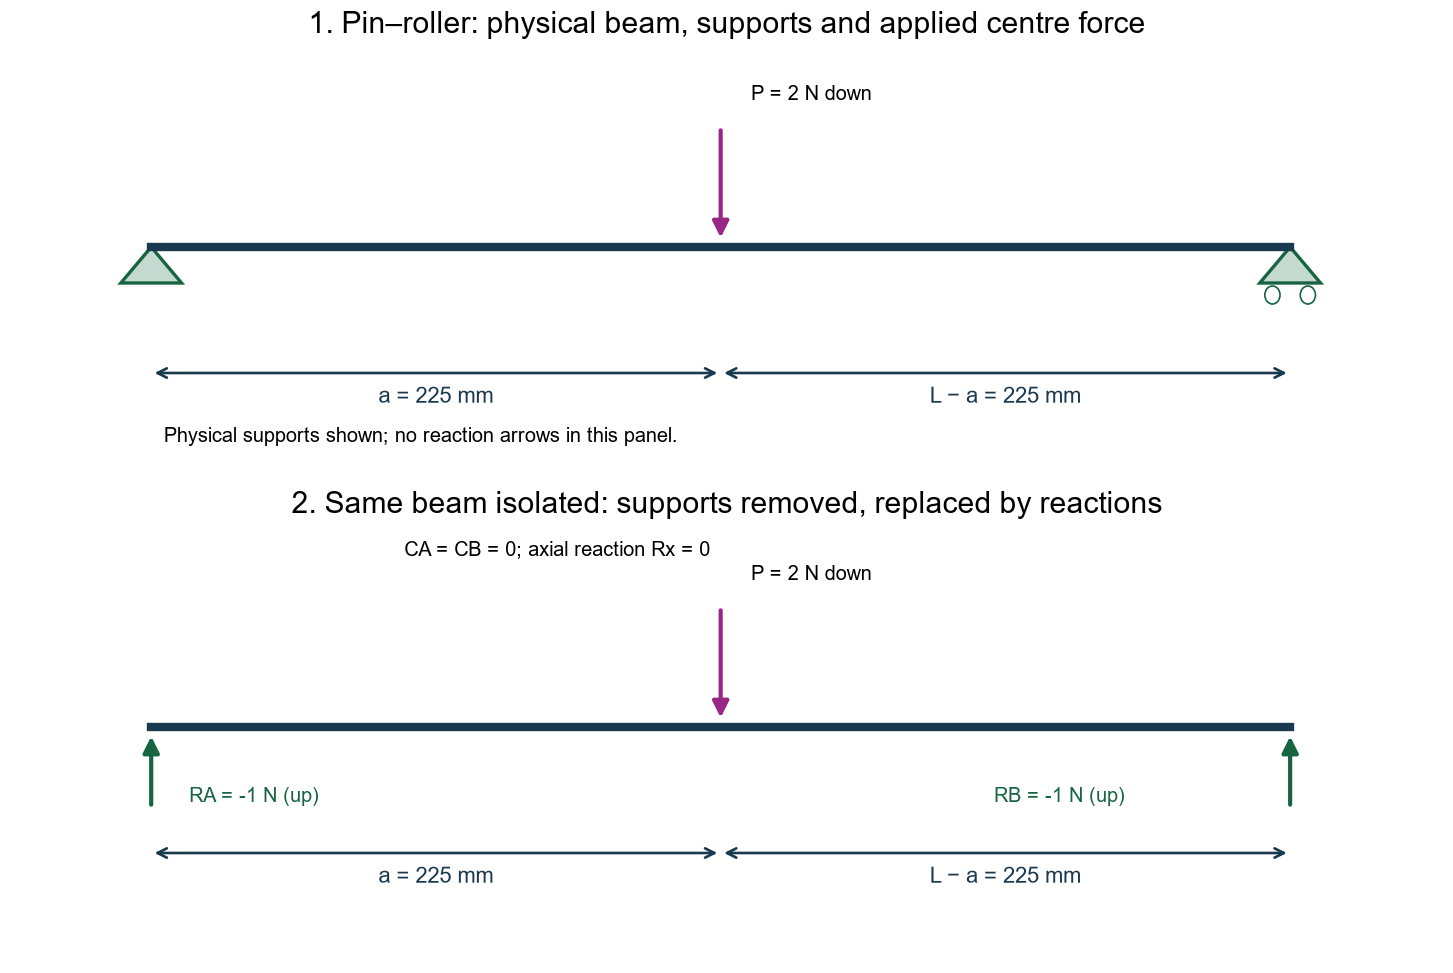

In [9]:
#@title Figure 1B — supported system first, free body second
fig,axes=plt.subplots(2,1,figsize=(12,8),layout='constrained')
beam_system_or_fbd(axes[0],'simple','1. Pin–roller: physical beam, supports and applied centre force')
beam_system_or_fbd(axes[1],'simple','2. Same beam isolated: supports removed, replaced by reactions',fbd=True)
plt.show()

The pin supplies horizontal/vertical force, but no couple. A horizontal roller supplies vertical force only. Thus Rₓ = 0 and Cₐ = C<sub>B</sub> = 0. Take moments about A first:

$$R_A+R_B+2=0,$$

$$R_B(450)+2(225)=0\quad\Longrightarrow R_B=-1\ \mathrm{N}\quad(\mathrm{upward}).$$

Then Rₐ = −2 − (−1) = −1 N (upward). Two transverse unknowns are found from equilibrium; no material modulus is needed. The app reports −1 N at each support and zero couples.

**[Open this exact beam study: pin–roller with the 2 N centre force](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-simple)**. The link replaces the old study with these inputs and solves it.

### 2C. Both ends fixed — the same centre force

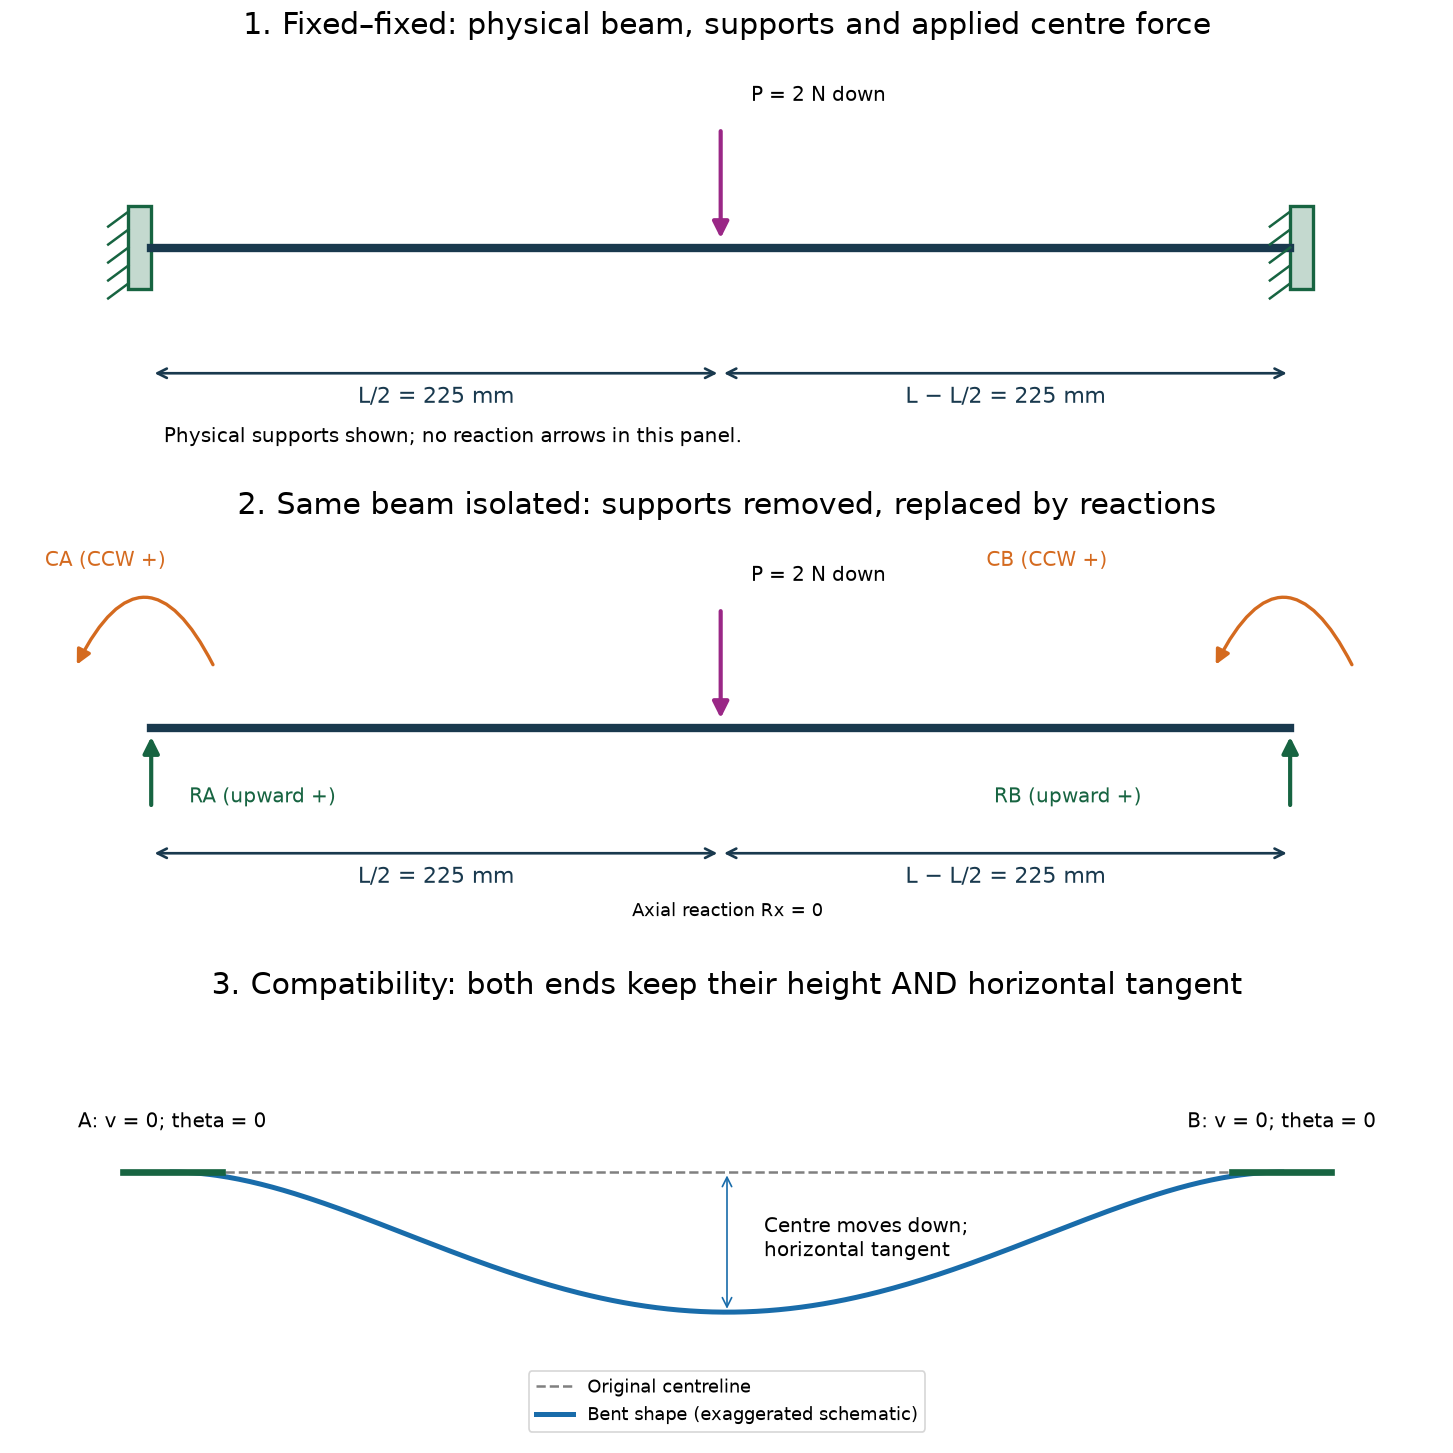

In [10]:
#@title Figure 1C — supported system first, free body second
fig,axes=plt.subplots(3,1,figsize=(12,12),layout='constrained')
beam_system_or_fbd(axes[0],'fixed','1. Fixed–fixed: physical beam, supports and applied centre force')
beam_system_or_fbd(axes[1],'fixed','2. Same beam isolated: supports removed, replaced by reactions',fbd=True)

for label in axes[1].texts:
    text = label.get_text()
    if text.startswith('RA ='): label.set_text('RA (upward +)')
    elif text.startswith('RB ='): label.set_text('RB (upward +)')
    elif text.startswith('CA ='): label.set_text('CA (CCW +)')
    elif text.startswith('CB ='): label.set_text('CB (CCW +)')
# Both unknown external couples are drawn in the positive CCW direction.
# The negative solved CB later means the actual couple acts clockwise.
for patch in list(axes[1].patches):
    if isinstance(patch, FancyArrowPatch): patch.remove()
for centre in (0, L):
    axes[1].add_patch(FancyArrowPatch((centre+25,20),(centre-30,20),
        connectionstyle='arc3,rad=1',arrowstyle='-|>',mutation_scale=18,
        color='#d46a1f',lw=2))

for ax_dim in axes[:2]:
    for label in ax_dim.texts:
        label.set_text(label.get_text().replace('a = 225 mm','L/2 = 225 mm').replace('L − a = 225 mm','L/2 = 225 mm'))

ax=axes[2]
xx=np.linspace(0,L,301)
shape=-25*16*(xx/L)**2*(1-xx/L)**2
ax.plot(xx,np.zeros_like(xx),'--',color='gray',label='Original centreline')
ax.plot(xx,shape,color='#196caa',lw=3,label='Bent shape (exaggerated schematic)')
for end,label in [(0,'A'),(L,'B')]:
    ax.plot([end-20,end+20],[0,0],color='#176441',lw=4)
    ax.text(end,8,label+': v = 0; theta = 0',ha='center',fontsize=12)
ax.annotate('',xy=(L/2,-25),xytext=(L/2,0),arrowprops=dict(arrowstyle='<->',color='#196caa'))
ax.text(L/2+15,-15,'Centre moves down;\nhorizontal tangent',fontsize=12)
ax.set(xlim=(-65,L+65),ylim=(-48,30))
ax.set_title('3. Compatibility: both ends keep their height AND horizontal tangent')
ax.axis('off');ax.legend(loc='lower center',fontsize=11)
plt.show()

Both supports prevent translation and rotation. There are four transverse unknowns: Rₐ, R<sub>B</sub>, Cₐ and C<sub>B</sub>. Whole-beam equilibrium gives:

For this example, take the reaction directions exactly as drawn: both forces upward, both support couples positive counterclockwise. With P = 2 N downward:

$$R_A+R_B-2=0,$$

$$C_A+C_B+450R_B-2(225)=0.$$

#### Why do we need two more equations?

Equilibrium says that the beam does not accelerate; it does **not** say whether its bent shape fits its supports. Four transverse reactions but only two equilibrium equations leave two unknowns undetermined. This is a **statically indeterminate beam of degree two** in the transverse bending model. Axial reactions are outside this model.

**Compatibility means that the deformed beam must still fit the supports.** A perfect clamp does not let the end move vertically or rotate. Therefore v(0) = 0, θ(0) = 0, v(L) = 0 and θ(L) = 0. The centre may move downward; a clamp does not mean the whole beam stays straight.

We build the shape starting at A with v(0) = θ(0) = 0. The **two additional requirements at B** are:

$$\boxed{\theta(L)=0}\qquad\boxed{v(L)=0}.$$

The first says “the right end must finish horizontal”; the second says “the right end must finish at its original height.” These are geometric conditions, not extra force balances. If guessed reactions leave a tilted or vertically displaced right end, they cannot be the reactions of this fixed–fixed beam.

#### Why use the conditions at L rather than at zero?

**Start with bending, then integrate twice.** We use the small-deflection Euler–Bernoulli beam model: cross-sections remain plane and normal to the bent centreline. Here displacement v is positive downward, θ = dv/dx, and internal moment M is positive in sagging.

**Step 1 — moment produces curvature.** The bending law is M = EIκ. With our signs, sagging curvature is κ = −dθ/dx: a positive sagging moment makes the downward-positive slope decrease as x increases. Therefore

$$M=EI\kappa,\qquad \kappa=-\frac{d\theta}{dx}
\quad\Rightarrow\quad \frac{d\theta}{dx}=-\frac{M(x)}{EI(x)}.$$

This is the moment–curvature law, not another equilibrium equation. E describes the material and I describes the section's resistance to bending. The stress/strain derivation is developed in the bending-stress section below.

**Step 2 — add the changes in slope from 0 to x.** The fundamental theorem of calculus gives

$$\int_0^x\frac{d\theta(s)}{ds}\,ds
=\theta(x)-\theta(0)
=-\int_0^x\frac{M(s)}{EI(s)}\,ds.$$

Move θ(0) to the right and call it Cθ:

$$\boxed{\theta(x)=C_\theta-\int_0^x\frac{M(s)}{EI(s)}\,ds},
\qquad C_\theta=\theta(0).$$

The integral gives the **change** in slope; the starting slope must be added. The letter s labels the running position inside the integral; x is the position where we want the answer.

**Step 3 — add the slopes to obtain displacement.** Since dv/dx = θ,

$$v(x)-v(0)=\int_0^x\theta(t)\,dt.$$

Substitute the slope just obtained (using t for its endpoint):

$$v(x)=v(0)+x\theta(0)
-\int_0^x\left[\int_0^t\frac{M(s)}{EI(s)}\,ds\right]dt.$$

**Why does the factor (x − s) appear?** A small length ds at s contributes a small slope change −M(s)ds/EI(s). That change contributes to the slope at every later position t between s and x. Its total contribution to displacement is therefore its slope change multiplied by the remaining distance, x − s. Adding all these contributions turns the double integral into

$$\int_0^x\left[\int_0^t\frac{M(s)}{EI(s)}\,ds\right]dt
=\int_0^x(x-s)\frac{M(s)}{EI(s)}\,ds.$$

Thus the second relation is

$$\boxed{v(x)=C_v+C_\theta x-\int_0^x(x-s)\frac{M(s)}{EI(s)}\,ds},
\qquad C_v=v(0).$$

The three terms are **starting displacement + displacement from starting tilt + displacement caused by bending**. Units provide a check: M/EI has units 1/length; its first integral is a rotation, and multiplying by (x − s) before integrating gives a length. Keep EI(s) inside the integral when stiffness varies.

**Now apply the left clamp.** At x = 0 the integrals vanish, so the clamp sets Cθ = θ(0) = 0 and Cᵥ = v(0) = 0. Both left-end conditions have been used; they were not omitted.

Once those constants are zero, substituting x = 0 again merely gives 0 = 0. It supplies no new equation for the unknown reactions. The right clamp supplies the remaining two independent conditions, **θ(L) = 0 and v(L) = 0**, which determine the redundant reactions through the moment function M(s). In total, all four displacement/rotation end conditions are satisfied, but they play different roles: two fix the integration constants; two determine the remaining reactions.

We could instead integrate starting at B, build in its two clamp conditions, and impose the conditions at A afterward. The final reactions and deflected shape would be the same.

**Keep the support cases separate:** these four zero end conditions belong to the fixed–fixed beam. In the cantilever cut example that follows, only the root is clamped; its free tip generally has nonzero rotation and displacement. Do not impose θ(L) = v(L) = 0 on that cantilever.



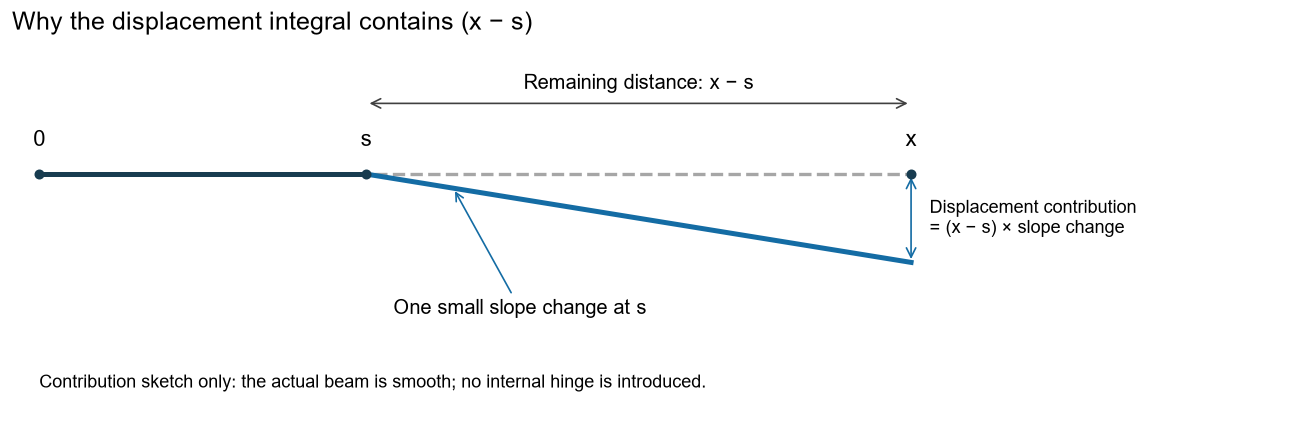

In [11]:
"""One curvature contribution, not a hinge in the physical beam."""
import matplotlib.pyplot as plt
import numpy as np
fig, ax = plt.subplots(figsize=(11, 3.8))
s0, x0, slope = 3., 8., .12
ax.plot([0, x0], [0, 0], color='0.65', lw=2, linestyle='--')
ax.plot([0, s0], [0, 0], color='#183c50', lw=3)
ax.plot([s0, x0], [0, slope*(x0-s0)], color='#146ca4', lw=3)
ax.scatter([0,s0,x0],[0,0,0],color='#183c50',s=25,zorder=5)
for xx,label in [(0,'0'),(s0,'s'),(x0,'x')]:
    ax.text(xx,-.16,label,ha='center',va='bottom',fontsize=13)
ax.annotate('',xy=(s0,-.48),xytext=(x0,-.48),arrowprops=dict(arrowstyle='<->',color='0.25'))
ax.text((s0+x0)/2,-.55,'Remaining distance: x − s',ha='center',va='bottom',fontsize=12)
ax.annotate('',xy=(x0,.6),xytext=(x0,0),arrowprops=dict(arrowstyle='<->',color='#146ca4'))
ax.text(x0+.17,.3,'Displacement contribution\n= (x − s) × slope change',va='center',fontsize=11)
ax.annotate('One small slope change at s',xy=(s0+.8,.096),xytext=(3.25,.95),fontsize=12,
            arrowprops=dict(arrowstyle='->',color='#146ca4'))
ax.set_title('Why the displacement integral contains (x − s)',loc='left',fontsize=15,pad=16)
ax.text(0,1.45,'Contribution sketch only: the actual beam is smooth; no internal hinge is introduced.',fontsize=11)
ax.set_xlim(-.25,11.4); ax.set_ylim(1.65,-.8); ax.axis('off')
fig.tight_layout()
plt.show()


#### How do these geometric conditions become equations for reactions?

For small elastic bending, moment makes curvature. With v positive downward and M positive in sagging, our sign convention gives:

$$\theta=\frac{dv}{dx},\qquad \frac{d\theta}{dx}=-\frac{M(x)}{EI}.$$

Think of a tiny length dx: curvature changes its slope by −M dx/(EI). Adding all these slope changes gives the end rotation. Adding slopes along the beam gives displacement. Section 5 derives this material/geometry relation more fully. For constant EI and the zero starting displacement and rotation at A:

$$\boxed{\theta(L)=-\frac{1}{EI}\int_0^L M(x)\,dx=0}$$

$$\boxed{v(L)=-\frac{1}{EI}\int_0^L (L-x)M(x)\,dx=0}$$

Why the factor L − x? A small change of slope created at station x contributes displacement over the remaining distance to B. The first integral has units of rotation (dimensionless, reported in radians); the second has units of length. Positive and negative moment regions must cancel in the required ways.

**Use the arrows in Figure 1C as positive directions:** $R_A$ and $R_B$ upward; $P=2$ N downward; $C_A$ and $C_B$ positive counterclockwise. Internal $M$ is sagging-positive. For a left-part cut, the reaction contributes $+R_Ax$, the applied force contributes $-P(x-L/2)$, and the support couple contributes $-C_A$. Thus the two forces have opposite moment signs, as drawn.

For a point force at x = L/2, a cut of the left portion gives:

$$M(x)=
\begin{cases}
-C_A+R_Ax,&0\leq x<L/2,\\
-C_A+R_Ax-P(x-L/2),&L/2\leq x\leq L.
\end{cases}$$



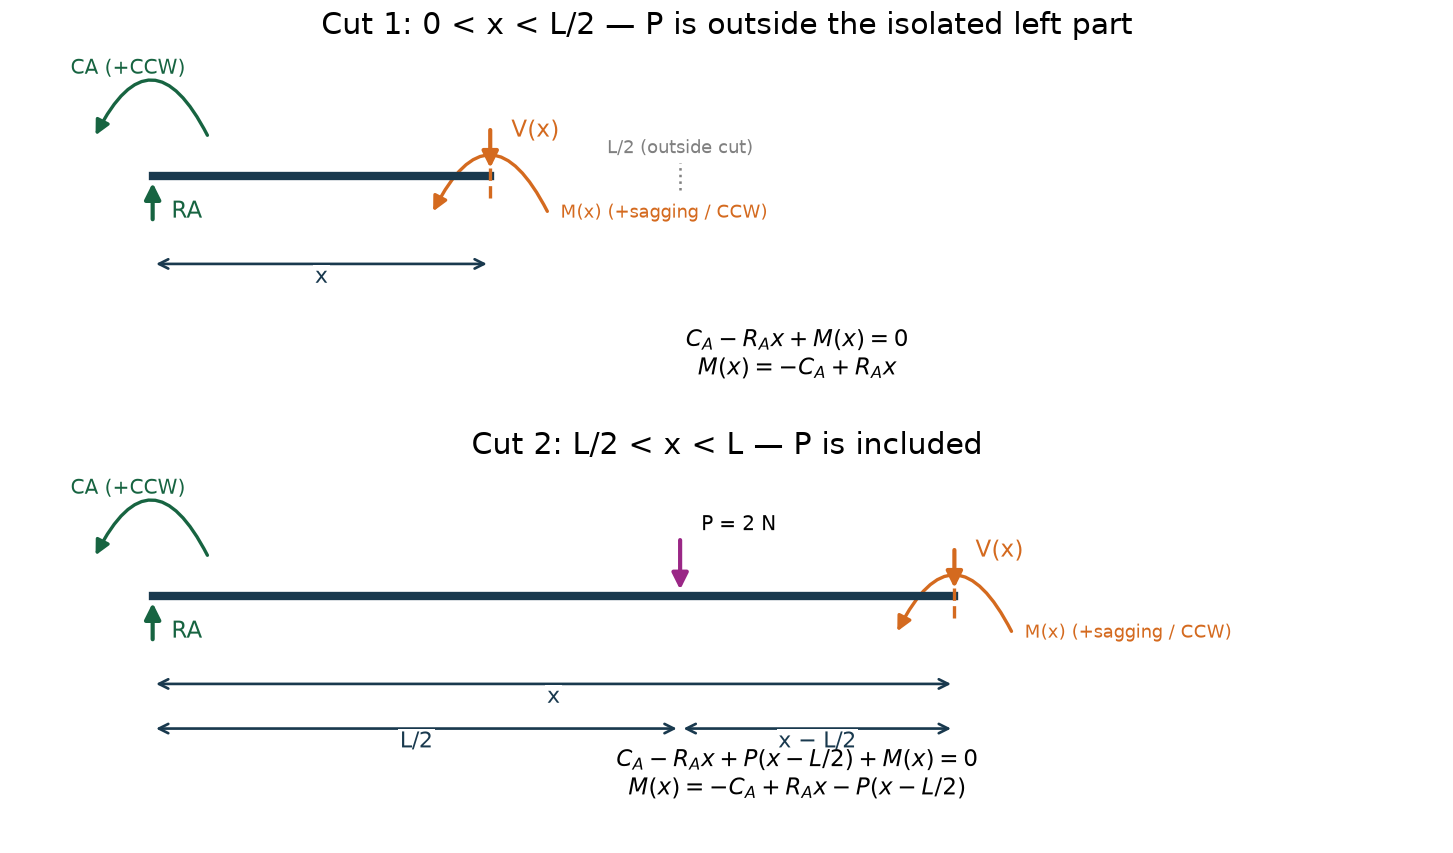

In [ ]:
#@title Left-part cuts: before and after the centre load
fig, axes = plt.subplots(2, 1, figsize=(12, 7), layout='constrained')
for ax, xc, title in [(axes[0], .32*L, 'Cut 1: 0 < x < L/2 — P is outside the isolated left part'),
                      (axes[1], .76*L, 'Cut 2: L/2 < x < L — P is included')]:
    ax.plot([0, xc], [0, 0], color='#19394e', lw=5)
    ax.plot([xc,xc],[-13,13],color='#d46a1f',lw=2,ls='--')
    arrow(ax,(0,-28),(0,-2),'#176441');ax.text(8,-25,'RA',color='#176441')
    ax.add_patch(FancyArrowPatch((24,23),(-25,23),connectionstyle='arc3,rad=1',arrowstyle='-|>',mutation_scale=18,color='#176441',lw=2))
    ax.text(-35,62,'CA (+CCW)',fontsize=12,color='#176441')
    # Positive internal actions on the right face of a left-part cut.
    arrow(ax,(xc,30),(xc,3),'#d46a1f');ax.text(xc+9,24,'V(x)',color='#d46a1f')
    ax.add_patch(FancyArrowPatch((xc+25,-23),(xc-25,-23),connectionstyle='arc3,rad=1',arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
    ax.text(xc+30,-25,'M(x) (+sagging / CCW)',fontsize=11,color='#d46a1f')
    dimension(ax,(0,-53),(xc,-53),'x',(0,-8))
    if xc>L/2:
        arrow(ax,(L/2,36),(L/2,2));ax.text(L/2+9,40,'P = 2 N',fontsize=12)
        dimension(ax,(0,-80),(L/2,-80),'L/2',(0,-8))
        dimension(ax,(L/2,-80),(xc,-80),'x − L/2',(0,-8))
        equation=r'$C_A-R_Ax+P(x-L/2)+M(x)=0$'+'\n'+r'$M(x)=-C_A+R_Ax-P(x-L/2)$'
    else:
        ax.plot([L/2,L/2],[-8,8],color='gray',ls=':');ax.text(L/2,14,'L/2 (outside cut)',ha='center',fontsize=11,color='gray')
        equation=r'$C_A-R_Ax+M(x)=0$'+'\n'+r'$M(x)=-C_A+R_Ax$'
    ax.text(275,-120,equation,ha='center',fontsize=14)
    ax.set(xlim=(-60,550),ylim=(-148,80),title=title);ax.axis('off')
plt.show()


#### Work through the two compatibility integrals

The moment expression changes when the cut passes the point load, so **split at its actual position** L/2. The value at the single point x=L/2 does not affect an integral. Here E and I are constant and nonzero; only under that restriction can we multiply the zero-rotation and zero-displacement equations by -EI and cancel the same stiffness factor.

**1. Zero end rotation: integrate the moment diagram.**

$$\begin{aligned}
0&=\int_0^L M(x)\,dx\\
 &=\int_0^{L/2}(-C_A+R_Ax)\,dx
   +\int_{L/2}^L[-C_A+R_Ax-P(x-L/2)]\,dx\\
 &=\left[-C_Ax+\frac{R_Ax^2}{2}\right]_0^{L/2}
   +\left[-C_Ax+\frac{R_Ax^2}{2}-\frac{P(x-L/2)^2}{2}\right]_{L/2}^L\\
 &=\left(-C_A(L/2)+\frac{R_A(L/2)^2}{2}\right)
  +\left(-C_AL+\frac{R_AL^2}{2}-\frac{P(L/2)^2}{2}
          +C_A(L/2)-\frac{R_A(L/2)^2}{2}\right)\\
 &=\boxed{-C_AL+\frac{R_AL^2}{2}-\frac{P(L/2)^2}{2}}.
\end{aligned}$$

The lower-bound couple terms cancel; the two R_A(L/2)²/2 terms cancel. The point-load term at the lower bound is zero because (L/2-L/2)²=0. This integral has units N mm²; division by EI, whose units are N mm², gives rotation.

**2. Zero end displacement: integrate the weighted moment diagram.**

$$\begin{aligned}
0&=\int_0^L(L-x)M(x)\,dx\\
 &=\int_0^{L/2}(L-x)(-C_A+R_Ax)\,dx
   +\int_{L/2}^L(L-x)[-C_A+R_Ax-P(x-L/2)]\,dx.
\end{aligned}$$

The -C_A+R_Ax contribution exists on both intervals. Join those two pieces, but keep the point-load contribution on [L/2,L] only:

$$\begin{aligned}
0&=-C_A\int_0^L(L-x)\,dx
 +R_A\int_0^L(Lx-x^2)\,dx
 -P\int_{L/2}^L(L-x)(x-L/2)\,dx\\
 &=-C_A\left[Lx-\frac{x^2}{2}\right]_0^L
 +R_A\left[\frac{Lx^2}{2}-\frac{x^3}{3}\right]_0^L
 -P\int_{L/2}^L(L-x)(x-L/2)\,dx.
\end{aligned}$$

For the last integral, use u=x-L/2. Its bounds become u=0 and u=L/2, while L-x=(L/2)-u:

$$\begin{aligned}
\int_{L/2}^L(L-x)(x-L/2)\,dx
 &=\int_0^{L/2}[(L/2)u-u^2]\,du\\
 &=\left[\frac{(L/2)u^2}{2}-\frac{u^3}{3}\right]_0^{L/2}\\
 &=(L/2)^3\left(\frac12-\frac13\right)
 =\frac{(L/2)^3}{6}.
\end{aligned}$$

Therefore

$$\begin{aligned}
0&=-C_A\left(L^2-\frac{L^2}{2}\right)
 +R_A\left(\frac{L^3}{2}-\frac{L^3}{3}\right)
 -\frac{P(L/2)^3}{6}\\
 &=\boxed{\frac{-C_AL^2}{2}+\frac{R_AL^3}{6}-\frac{P(L/2)^3}{6}}.
\end{aligned}$$

This integral has units N mm³; division by EI gives millimetres. The extra lever arm L-x makes this a different condition from zero rotation. If EI varies, retain M(x)/(EI(x)) inside **each** integral; these two constant-stiffness polynomial equations no longer follow.

These are **zero rotation and zero displacement**, respectively—not new laws of equilibrium. The common nonzero EI cancels because it is constant here. It cannot generally be taken outside the integral for a tapered or variable-stiffness beam.

#### Solve, then label every reaction

For $L=450$ mm, $L/2=225$ mm and $P=2$ N, the compatibility equations become

$$-450C_A+101250R_A-50625=0,$$
$$-101250C_A+15187500R_A-3796875=0.$$

Multiply the first equation by 225 mm and subtract the second:

$$7593750R_A-7593750=0\quad\Rightarrow\quad\boxed{R_A=1\ \mathrm{N}\ \text{upward}}.$$

Substitute into the first equation:

$$-450C_A+101250-50625=0\quad\Rightarrow\quad
\boxed{C_A=112.5\ \mathrm{N\,mm}\ \text{counterclockwise}}.$$

Whole-beam equilibrium, using the drawn directions, gives

$$R_A+R_B-P=0\quad\Rightarrow\quad\boxed{R_B=1\ \mathrm{N}\ \text{upward}},$$
$$C_A+C_B+R_BL-Pa=0\quad\Rightarrow\quad
\boxed{C_B=-112.5\ \mathrm{N\,mm}\quad(112.5\ \mathrm{N\,mm}\ \text{clockwise})}.$$

The complete numerical internal moment is therefore

$$M(x)=\begin{cases}-112.5+x,&0\le x<225,\\
-112.5+x-2(x-225)=337.5-x,&225\le x\le450,
\end{cases}\quad[\mathrm{N\,mm}],$$

with $x$ in mm. Thus $M(0^+)=-112.5$, $M(225)=+112.5$ and $M(450^-)=-112.5$ N mm. A positive C_A acts counterclockwise; the negative C_B acts clockwise. Both internal end moments are hogging.

**Check compatibility:**

$$\int_0^L M\,dx=-50625+101250-50625=0,$$
$$\int_0^L(L-x)M\,dx=-11390625+15187500-3796875=0.$$

With $E=2000$ MPa and $I=20(10)^3/12=1666.6667$ mm⁴,

$$v(225)=-\frac{-C_A(L/2)^2/2+R_A(L/2)^3/6}{EI}
=\frac{PL^3}{192EI}=0.284765625\ \mathrm{mm}\ \text{downward},\qquad\theta(225)=0.$$

Both ends have zero displacement and rotation. Beam Lab reports signed reactions positive downward and couples positive clockwise: its table therefore shows $R_A=R_B=-1$ N, $C_A=-112.5$ and $C_B=+112.5$ N mm. These are the **same physical arrows** as the positive magnitudes used above; the software's reporting convention differs. The following plots retain Beam Lab's own axis labels.


**[Open this exact beam study: fixed–fixed with the 2 N centre force](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-fixed)**. The link replaces the old study with these inputs and solves it.

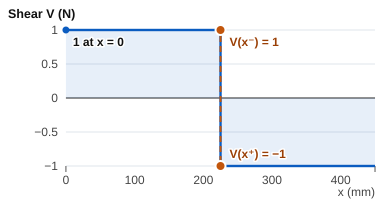

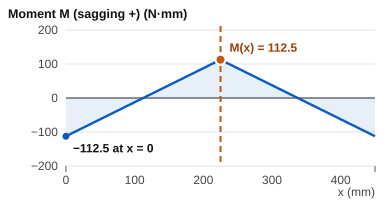

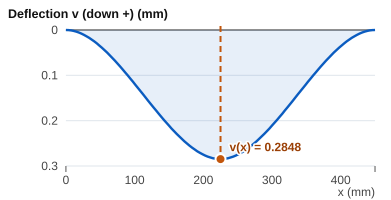

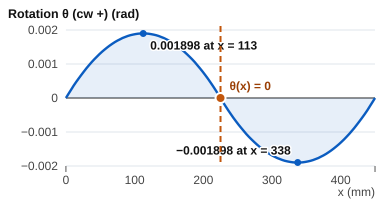

In [ ]:
#@title Beam Lab outputs — the same fixed–fixed 2 N example
from IPython.display import SVG, display
# Actual SVG charts exported from the solved Beam Lab example, not schematic curves.
beam_lab_charts = ['<svg xmlns="http://www.w3.org/2000/svg" data-x0="66" data-x1="375.5" data-length="450" data-w="391.5" class="bl-svg bl-chart" viewBox="0 0 391.5 200" width="391.5" height="200" style="max-width:391.5px" role="img" aria-label="Shear force V in N along the beam" preserveAspectRatio="xMidYMid meet"><style>text{font-family:Arial,Helvetica,"Liberation Sans","DejaVu Sans",sans-serif;font-size:13px;fill:#111;paint-order:stroke;stroke:#fff;stroke-width:3px;stroke-linejoin:round}.bl-tx-s{font-size:12.5px}.bl-tx-xs{font-size:12px}.bl-tx-b{font-weight:700}.bl-tx-m{fill:#444}.bl-tx-cut{fill:#9a3f05}.bl-grid{stroke:#dfe5eb;stroke-width:1}.bl-zero{stroke:#555;stroke-width:1.3}.bl-axis{stroke:#555;stroke-width:1}.bl-curve{fill:none;stroke:#0b5cc0;stroke-width:2.4;stroke-linejoin:round}.bl-area{fill:#0b5cc0;opacity:.1}.bl-ext{fill:#0b5cc0}.bl-cut{stroke:#c2560c;stroke-width:2;stroke-dasharray:6 4}.bl-cut-dot{fill:#c2560c;stroke:#fff;stroke-width:2}.img-title{font-size:20px;font-weight:700}.img-line{font-size:14px;fill:#222}.img-note{font-size:13px;fill:#333}</style><rect width="100%" height="100%" fill="white"/><title>Shear force V in N along the beam</title><text x="8" y="18" class="bl-tx-s bl-tx-b" text-anchor="start">Shear V (N)</text><line x1="66" y1="166" x2="375.5" y2="166" class="bl-grid"></line><text x="58" y="170" class="bl-tx-xs bl-tx-m" text-anchor="end">−1</text><line x1="66" y1="132" x2="375.5" y2="132" class="bl-grid"></line><text x="58" y="136" class="bl-tx-xs bl-tx-m" text-anchor="end">−0.5</text><line x1="66" y1="98" x2="375.5" y2="98" class="bl-zero"></line><text x="58" y="102" class="bl-tx-xs bl-tx-m" text-anchor="end">0</text><line x1="66" y1="64" x2="375.5" y2="64" class="bl-grid"></line><text x="58" y="68" class="bl-tx-xs bl-tx-m" text-anchor="end">0.5</text><line x1="66" y1="30" x2="375.5" y2="30" class="bl-grid"></line><text x="58" y="34" class="bl-tx-xs bl-tx-m" text-anchor="end">1</text><line x1="66" y1="166" x2="66" y2="172" class="bl-axis"></line><line x1="375.5" y1="166" x2="375.5" y2="172" class="bl-axis"></line><text x="66" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">0</text><text x="134.8" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">100</text><text x="203.6" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">200</text><text x="272.3" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">300</text><text x="341.1" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">400</text><text x="375.5" y="196" class="bl-tx-xs bl-tx-m" text-anchor="end">x (mm)</text><polygon points="66,98 66,30 68.6,30 71.2,30 73.7,30 76.3,30 78.9,30 81.5,30 84.1,30 86.6,30 89.2,30 91.8,30 94.4,30 97,30 99.5,30 102.1,30 104.7,30 107.3,30 109.8,30 112.4,30 115,30 117.6,30 120.2,30 122.7,30 125.3,30 127.9,30 130.5,30 133.1,30 135.6,30 138.2,30 140.8,30 143.4,30 146,30 148.5,30 151.1,30 153.7,30 156.3,30 158.9,30 161.4,30 164,30 166.6,30 169.2,30 171.7,30 174.3,30 176.9,30 179.5,30 182.1,30 184.6,30 187.2,30 189.8,30 192.4,30 195,30 197.5,30 200.1,30 202.7,30 205.3,30 207.9,30 210.4,30 213,30 215.6,30 218.2,30 220.8,30 220.8,166 223.3,166 225.9,166 228.5,166 231.1,166 233.6,166 236.2,166 238.8,166 241.4,166 244,166 246.5,166 249.1,166 251.7,166 254.3,166 256.9,166 259.4,166 262,166 264.6,166 267.2,166 269.8,166 272.3,166 274.9,166 277.5,166 280.1,166 282.7,166 285.2,166 287.8,166 290.4,166 293,166 295.5,166 298.1,166 300.7,166 303.3,166 305.9,166 308.4,166 311,166 313.6,166 316.2,166 318.8,166 321.3,166 323.9,166 326.5,166 329.1,166 331.7,166 334.2,166 336.8,166 339.4,166 342,166 344.6,166 347.1,166 349.7,166 352.3,166 354.9,166 357.4,166 360,166 362.6,166 365.2,166 367.8,166 370.3,166 372.9,166 375.5,166 375.5,98" class="bl-area"></polygon><polyline points="66,30 68.6,30 71.2,30 73.7,30 76.3,30 78.9,30 81.5,30 84.1,30 86.6,30 89.2,30 91.8,30 94.4,30 97,30 99.5,30 102.1,30 104.7,30 107.3,30 109.8,30 112.4,30 115,30 117.6,30 120.2,30 122.7,30 125.3,30 127.9,30 130.5,30 133.1,30 135.6,30 138.2,30 140.8,30 143.4,30 146,30 148.5,30 151.1,30 153.7,30 156.3,30 158.9,30 161.4,30 164,30 166.6,30 169.2,30 171.7,30 174.3,30 176.9,30 179.5,30 182.1,30 184.6,30 187.2,30 189.8,30 192.4,30 195,30 197.5,30 200.1,30 202.7,30 205.3,30 207.9,30 210.4,30 213,30 215.6,30 218.2,30 220.8,30 220.8,166 223.3,166 225.9,166 228.5,166 231.1,166 233.6,166 236.2,166 238.8,166 241.4,166 244,166 246.5,166 249.1,166 251.7,166 254.3,166 256.9,166 259.4,166 262,166 264.6,166 267.2,166 269.8,166 272.3,166 274.9,166 277.5,166 280.1,166 282.7,166 285.2,166 287.8,166 290.4,166 293,166 295.5,166 298.1,166 300.7,166 303.3,166 305.9,166 308.4,166 311,166 313.6,166 316.2,166 318.8,166 321.3,166 323.9,166 326.5,166 329.1,166 331.7,166 334.2,166 336.8,166 339.4,166 342,166 344.6,166 347.1,166 349.7,166 352.3,166 354.9,166 357.4,166 360,166 362.6,166 365.2,166 367.8,166 370.3,166 372.9,166 375.5,166" class="bl-curve"></polyline><circle cx="66" cy="30" r="3.5" class="bl-ext"></circle><text x="73" y="46" class="bl-tx-xs bl-tx-b" text-anchor="start" data-label="ext">1 at x = 0</text><line x1="220.8" y1="26" x2="220.8" y2="166" class="bl-cut"></line><circle cx="220.8" cy="30" r="5" class="bl-cut-dot"></circle><text x="229.8" y="46" class="bl-tx-xs bl-tx-cut bl-tx-b" text-anchor="start" data-label="cut">V(x⁻) = 1</text><circle cx="220.8" cy="166" r="5" class="bl-cut-dot"></circle><text x="229.8" y="158" class="bl-tx-xs bl-tx-cut bl-tx-b" text-anchor="start" data-label="cut">V(x⁺) = −1</text></svg>', '<svg xmlns="http://www.w3.org/2000/svg" data-x0="66" data-x1="375.5" data-length="450" data-w="391.5" class="bl-svg bl-chart" viewBox="0 0 391.5 200" width="391.5" height="200" style="max-width:391.5px" role="img" aria-label="Bending moment M (sagging +) in N·mm along the beam" preserveAspectRatio="xMidYMid meet"><style>text{font-family:Arial,Helvetica,"Liberation Sans","DejaVu Sans",sans-serif;font-size:13px;fill:#111;paint-order:stroke;stroke:#fff;stroke-width:3px;stroke-linejoin:round}.bl-tx-s{font-size:12.5px}.bl-tx-xs{font-size:12px}.bl-tx-b{font-weight:700}.bl-tx-m{fill:#444}.bl-tx-cut{fill:#9a3f05}.bl-grid{stroke:#dfe5eb;stroke-width:1}.bl-zero{stroke:#555;stroke-width:1.3}.bl-axis{stroke:#555;stroke-width:1}.bl-curve{fill:none;stroke:#0b5cc0;stroke-width:2.4;stroke-linejoin:round}.bl-area{fill:#0b5cc0;opacity:.1}.bl-ext{fill:#0b5cc0}.bl-cut{stroke:#c2560c;stroke-width:2;stroke-dasharray:6 4}.bl-cut-dot{fill:#c2560c;stroke:#fff;stroke-width:2}.img-title{font-size:20px;font-weight:700}.img-line{font-size:14px;fill:#222}.img-note{font-size:13px;fill:#333}</style><rect width="100%" height="100%" fill="white"/><title>Bending moment M (sagging +) in N·mm along the beam</title><text x="8" y="18" class="bl-tx-s bl-tx-b" text-anchor="start">Moment M (sagging +) (N·mm)</text><line x1="66" y1="166" x2="375.5" y2="166" class="bl-grid"></line><text x="58" y="170" class="bl-tx-xs bl-tx-m" text-anchor="end">−200</text><line x1="66" y1="132" x2="375.5" y2="132" class="bl-grid"></line><text x="58" y="136" class="bl-tx-xs bl-tx-m" text-anchor="end">−100</text><line x1="66" y1="98" x2="375.5" y2="98" class="bl-zero"></line><text x="58" y="102" class="bl-tx-xs bl-tx-m" text-anchor="end">0</text><line x1="66" y1="64" x2="375.5" y2="64" class="bl-grid"></line><text x="58" y="68" class="bl-tx-xs bl-tx-m" text-anchor="end">100</text><line x1="66" y1="30" x2="375.5" y2="30" class="bl-grid"></line><text x="58" y="34" class="bl-tx-xs bl-tx-m" text-anchor="end">200</text><line x1="66" y1="166" x2="66" y2="172" class="bl-axis"></line><line x1="375.5" y1="166" x2="375.5" y2="172" class="bl-axis"></line><text x="66" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">0</text><text x="134.8" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">100</text><text x="203.6" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">200</text><text x="272.3" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">300</text><text x="341.1" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">400</text><text x="375.5" y="196" class="bl-tx-xs bl-tx-m" text-anchor="end">x (mm)</text><polygon points="66,98 66,136.3 68.6,135 71.2,133.7 73.7,132.4 76.3,131.2 78.9,129.9 81.5,128.6 84.1,127.3 86.6,126.1 89.2,124.8 91.8,123.5 94.4,122.2 97,120.9 99.5,119.7 102.1,118.4 104.7,117.1 107.3,115.8 109.8,114.6 112.4,113.3 115,112 117.6,110.7 120.2,109.5 122.7,108.2 125.3,106.9 127.9,105.6 130.5,104.4 133.1,103.1 135.6,101.8 138.2,100.5 140.8,99.3 143.4,98 146,96.7 148.5,95.4 151.1,94.2 153.7,92.9 156.3,91.6 158.9,90.3 161.4,89.1 164,87.8 166.6,86.5 169.2,85.2 171.7,84 174.3,82.7 176.9,81.4 179.5,80.1 182.1,78.9 184.6,77.6 187.2,76.3 189.8,75 192.4,73.8 195,72.5 197.5,71.2 200.1,69.9 202.7,68.7 205.3,67.4 207.9,66.1 210.4,64.8 213,63.6 215.6,62.3 218.2,61 220.8,59.7 220.8,59.7 223.3,61 225.9,62.3 228.5,63.6 231.1,64.8 233.6,66.1 236.2,67.4 238.8,68.7 241.4,69.9 244,71.2 246.5,72.5 249.1,73.8 251.7,75 254.3,76.3 256.9,77.6 259.4,78.9 262,80.1 264.6,81.4 267.2,82.7 269.8,84 272.3,85.2 274.9,86.5 277.5,87.8 280.1,89.1 282.7,90.3 285.2,91.6 287.8,92.9 290.4,94.2 293,95.4 295.5,96.7 298.1,98 300.7,99.3 303.3,100.5 305.9,101.8 308.4,103.1 311,104.4 313.6,105.6 316.2,106.9 318.8,108.2 321.3,109.5 323.9,110.7 326.5,112 329.1,113.3 331.7,114.6 334.2,115.8 336.8,117.1 339.4,118.4 342,119.7 344.6,120.9 347.1,122.2 349.7,123.5 352.3,124.8 354.9,126 357.4,127.3 360,128.6 362.6,129.9 365.2,131.1 367.8,132.4 370.3,133.7 372.9,135 375.5,136.2 375.5,98" class="bl-area"></polygon><polyline points="66,136.3 68.6,135 71.2,133.7 73.7,132.4 76.3,131.2 78.9,129.9 81.5,128.6 84.1,127.3 86.6,126.1 89.2,124.8 91.8,123.5 94.4,122.2 97,120.9 99.5,119.7 102.1,118.4 104.7,117.1 107.3,115.8 109.8,114.6 112.4,113.3 115,112 117.6,110.7 120.2,109.5 122.7,108.2 125.3,106.9 127.9,105.6 130.5,104.4 133.1,103.1 135.6,101.8 138.2,100.5 140.8,99.3 143.4,98 146,96.7 148.5,95.4 151.1,94.2 153.7,92.9 156.3,91.6 158.9,90.3 161.4,89.1 164,87.8 166.6,86.5 169.2,85.2 171.7,84 174.3,82.7 176.9,81.4 179.5,80.1 182.1,78.9 184.6,77.6 187.2,76.3 189.8,75 192.4,73.8 195,72.5 197.5,71.2 200.1,69.9 202.7,68.7 205.3,67.4 207.9,66.1 210.4,64.8 213,63.6 215.6,62.3 218.2,61 220.8,59.7 220.8,59.7 223.3,61 225.9,62.3 228.5,63.6 231.1,64.8 233.6,66.1 236.2,67.4 238.8,68.7 241.4,69.9 244,71.2 246.5,72.5 249.1,73.8 251.7,75 254.3,76.3 256.9,77.6 259.4,78.9 262,80.1 264.6,81.4 267.2,82.7 269.8,84 272.3,85.2 274.9,86.5 277.5,87.8 280.1,89.1 282.7,90.3 285.2,91.6 287.8,92.9 290.4,94.2 293,95.4 295.5,96.7 298.1,98 300.7,99.3 303.3,100.5 305.9,101.8 308.4,103.1 311,104.4 313.6,105.6 316.2,106.9 318.8,108.2 321.3,109.5 323.9,110.7 326.5,112 329.1,113.3 331.7,114.6 334.2,115.8 336.8,117.1 339.4,118.4 342,119.7 344.6,120.9 347.1,122.2 349.7,123.5 352.3,124.8 354.9,126 357.4,127.3 360,128.6 362.6,129.9 365.2,131.1 367.8,132.4 370.3,133.7 372.9,135 375.5,136.2" class="bl-curve"></polyline><circle cx="66" cy="136.3" r="3.5" class="bl-ext"></circle><text x="73" y="152.3" class="bl-tx-xs bl-tx-b" text-anchor="start" data-label="ext">−112.5 at x = 0</text><line x1="220.8" y1="26" x2="220.8" y2="166" class="bl-cut"></line><circle cx="220.8" cy="59.7" r="5" class="bl-cut-dot"></circle><text x="229.8" y="51.7" class="bl-tx-xs bl-tx-cut bl-tx-b" text-anchor="start" data-label="cut">M(x) = 112.5</text></svg>', '<svg xmlns="http://www.w3.org/2000/svg" data-x0="66" data-x1="375.5" data-length="450" data-w="391.5" class="bl-svg bl-chart" viewBox="0 0 391.5 200" width="391.5" height="200" style="max-width:391.5px" role="img" aria-label="Deflection v (down +, drawn downward) in mm along the beam" preserveAspectRatio="xMidYMid meet"><style>text{font-family:Arial,Helvetica,"Liberation Sans","DejaVu Sans",sans-serif;font-size:13px;fill:#111;paint-order:stroke;stroke:#fff;stroke-width:3px;stroke-linejoin:round}.bl-tx-s{font-size:12.5px}.bl-tx-xs{font-size:12px}.bl-tx-b{font-weight:700}.bl-tx-m{fill:#444}.bl-tx-cut{fill:#9a3f05}.bl-grid{stroke:#dfe5eb;stroke-width:1}.bl-zero{stroke:#555;stroke-width:1.3}.bl-axis{stroke:#555;stroke-width:1}.bl-curve{fill:none;stroke:#0b5cc0;stroke-width:2.4;stroke-linejoin:round}.bl-area{fill:#0b5cc0;opacity:.1}.bl-ext{fill:#0b5cc0}.bl-cut{stroke:#c2560c;stroke-width:2;stroke-dasharray:6 4}.bl-cut-dot{fill:#c2560c;stroke:#fff;stroke-width:2}.img-title{font-size:20px;font-weight:700}.img-line{font-size:14px;fill:#222}.img-note{font-size:13px;fill:#333}</style><rect width="100%" height="100%" fill="white"/><title>Deflection v (down +, drawn downward) in mm along the beam</title><text x="8" y="18" class="bl-tx-s bl-tx-b" text-anchor="start">Deflection v (down +) (mm)</text><line x1="66" y1="30" x2="375.5" y2="30" class="bl-zero"></line><text x="58" y="34" class="bl-tx-xs bl-tx-m" text-anchor="end">0</text><line x1="66" y1="75.3" x2="375.5" y2="75.3" class="bl-grid"></line><text x="58" y="79.3" class="bl-tx-xs bl-tx-m" text-anchor="end">0.1</text><line x1="66" y1="120.7" x2="375.5" y2="120.7" class="bl-grid"></line><text x="58" y="124.7" class="bl-tx-xs bl-tx-m" text-anchor="end">0.2</text><line x1="66" y1="166" x2="375.5" y2="166" class="bl-grid"></line><text x="58" y="170" class="bl-tx-xs bl-tx-m" text-anchor="end">0.3</text><line x1="66" y1="166" x2="66" y2="172" class="bl-axis"></line><line x1="375.5" y1="166" x2="375.5" y2="172" class="bl-axis"></line><text x="66" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">0</text><text x="134.8" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">100</text><text x="203.6" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">200</text><text x="272.3" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">300</text><text x="341.1" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">400</text><text x="375.5" y="196" class="bl-tx-xs bl-tx-m" text-anchor="end">x (mm)</text><polygon points="66,30 66,30 68.6,30.1 71.2,30.4 73.7,30.9 76.3,31.6 78.9,32.5 81.5,33.6 84.1,34.9 86.6,36.3 89.2,37.8 91.8,39.6 94.4,41.4 97,43.4 99.5,45.6 102.1,47.8 104.7,50.2 107.3,52.6 109.8,55.2 112.4,57.9 115,60.6 117.6,63.5 120.2,66.4 122.7,69.3 125.3,72.4 127.9,75.4 130.5,78.6 133.1,81.7 135.6,84.9 138.2,88.1 140.8,91.3 143.4,94.5 146,97.8 148.5,101 151.1,104.2 153.7,107.4 156.3,110.5 158.9,113.7 161.4,116.7 164,119.8 166.6,122.7 169.2,125.6 171.7,128.5 174.3,131.2 176.9,133.9 179.5,136.4 182.1,138.9 184.6,141.3 187.2,143.5 189.8,145.7 192.4,147.7 195,149.5 197.5,151.3 200.1,152.8 202.7,154.2 205.3,155.5 207.9,156.6 210.4,157.4 213,158.2 215.6,158.7 218.2,159 220.8,159.1 220.8,159.1 223.3,159 225.9,158.7 228.5,158.2 231.1,157.4 233.6,156.6 236.2,155.5 238.8,154.2 241.4,152.8 244,151.3 246.5,149.5 249.1,147.7 251.7,145.7 254.3,143.5 256.9,141.3 259.4,138.9 262,136.4 264.6,133.9 267.2,131.2 269.8,128.5 272.3,125.6 274.9,122.7 277.5,119.8 280.1,116.7 282.7,113.7 285.2,110.5 287.8,107.4 290.4,104.2 293,101 295.5,97.8 298.1,94.5 300.7,91.3 303.3,88.1 305.9,84.9 308.4,81.7 311,78.6 313.6,75.4 316.2,72.4 318.8,69.3 321.3,66.4 323.9,63.5 326.5,60.6 329.1,57.9 331.7,55.2 334.2,52.6 336.8,50.2 339.4,47.8 342,45.6 344.6,43.4 347.1,41.4 349.7,39.6 352.3,37.8 354.9,36.3 357.4,34.9 360,33.6 362.6,32.5 365.2,31.6 367.8,30.9 370.3,30.4 372.9,30.1 375.5,30 375.5,30" class="bl-area"></polygon><polyline points="66,30 68.6,30.1 71.2,30.4 73.7,30.9 76.3,31.6 78.9,32.5 81.5,33.6 84.1,34.9 86.6,36.3 89.2,37.8 91.8,39.6 94.4,41.4 97,43.4 99.5,45.6 102.1,47.8 104.7,50.2 107.3,52.6 109.8,55.2 112.4,57.9 115,60.6 117.6,63.5 120.2,66.4 122.7,69.3 125.3,72.4 127.9,75.4 130.5,78.6 133.1,81.7 135.6,84.9 138.2,88.1 140.8,91.3 143.4,94.5 146,97.8 148.5,101 151.1,104.2 153.7,107.4 156.3,110.5 158.9,113.7 161.4,116.7 164,119.8 166.6,122.7 169.2,125.6 171.7,128.5 174.3,131.2 176.9,133.9 179.5,136.4 182.1,138.9 184.6,141.3 187.2,143.5 189.8,145.7 192.4,147.7 195,149.5 197.5,151.3 200.1,152.8 202.7,154.2 205.3,155.5 207.9,156.6 210.4,157.4 213,158.2 215.6,158.7 218.2,159 220.8,159.1 220.8,159.1 223.3,159 225.9,158.7 228.5,158.2 231.1,157.4 233.6,156.6 236.2,155.5 238.8,154.2 241.4,152.8 244,151.3 246.5,149.5 249.1,147.7 251.7,145.7 254.3,143.5 256.9,141.3 259.4,138.9 262,136.4 264.6,133.9 267.2,131.2 269.8,128.5 272.3,125.6 274.9,122.7 277.5,119.8 280.1,116.7 282.7,113.7 285.2,110.5 287.8,107.4 290.4,104.2 293,101 295.5,97.8 298.1,94.5 300.7,91.3 303.3,88.1 305.9,84.9 308.4,81.7 311,78.6 313.6,75.4 316.2,72.4 318.8,69.3 321.3,66.4 323.9,63.5 326.5,60.6 329.1,57.9 331.7,55.2 334.2,52.6 336.8,50.2 339.4,47.8 342,45.6 344.6,43.4 347.1,41.4 349.7,39.6 352.3,37.8 354.9,36.3 357.4,34.9 360,33.6 362.6,32.5 365.2,31.6 367.8,30.9 370.3,30.4 372.9,30.1 375.5,30" class="bl-curve"></polyline><line x1="220.8" y1="26" x2="220.8" y2="166" class="bl-cut"></line><circle cx="220.8" cy="159.1" r="5" class="bl-cut-dot"></circle><text x="229.8" y="151.1" class="bl-tx-xs bl-tx-cut bl-tx-b" text-anchor="start" data-label="cut">v(x) = 0.2848</text></svg>', '<svg xmlns="http://www.w3.org/2000/svg" data-x0="66" data-x1="375.5" data-length="450" data-w="391.5" class="bl-svg bl-chart" viewBox="0 0 391.5 200" width="391.5" height="200" style="max-width:391.5px" role="img" aria-label="Rotation θ = dv/dx (clockwise +) in rad along the beam" preserveAspectRatio="xMidYMid meet"><style>text{font-family:Arial,Helvetica,"Liberation Sans","DejaVu Sans",sans-serif;font-size:13px;fill:#111;paint-order:stroke;stroke:#fff;stroke-width:3px;stroke-linejoin:round}.bl-tx-s{font-size:12.5px}.bl-tx-xs{font-size:12px}.bl-tx-b{font-weight:700}.bl-tx-m{fill:#444}.bl-tx-cut{fill:#9a3f05}.bl-grid{stroke:#dfe5eb;stroke-width:1}.bl-zero{stroke:#555;stroke-width:1.3}.bl-axis{stroke:#555;stroke-width:1}.bl-curve{fill:none;stroke:#0b5cc0;stroke-width:2.4;stroke-linejoin:round}.bl-area{fill:#0b5cc0;opacity:.1}.bl-ext{fill:#0b5cc0}.bl-cut{stroke:#c2560c;stroke-width:2;stroke-dasharray:6 4}.bl-cut-dot{fill:#c2560c;stroke:#fff;stroke-width:2}.img-title{font-size:20px;font-weight:700}.img-line{font-size:14px;fill:#222}.img-note{font-size:13px;fill:#333}</style><rect width="100%" height="100%" fill="white"/><title>Rotation θ = dv/dx (clockwise +) in rad along the beam</title><text x="8" y="18" class="bl-tx-s bl-tx-b" text-anchor="start">Rotation θ (cw +) (rad)</text><line x1="66" y1="166" x2="375.5" y2="166" class="bl-grid"></line><text x="58" y="170" class="bl-tx-xs bl-tx-m" text-anchor="end">−0.002</text><line x1="66" y1="132" x2="375.5" y2="132" class="bl-grid"></line><text x="58" y="136" class="bl-tx-xs bl-tx-m" text-anchor="end">−0.001</text><line x1="66" y1="98" x2="375.5" y2="98" class="bl-zero"></line><text x="58" y="102" class="bl-tx-xs bl-tx-m" text-anchor="end">0</text><line x1="66" y1="64" x2="375.5" y2="64" class="bl-grid"></line><text x="58" y="68" class="bl-tx-xs bl-tx-m" text-anchor="end">0.001</text><line x1="66" y1="30" x2="375.5" y2="30" class="bl-grid"></line><text x="58" y="34" class="bl-tx-xs bl-tx-m" text-anchor="end">0.002</text><line x1="66" y1="166" x2="66" y2="172" class="bl-axis"></line><line x1="375.5" y1="166" x2="375.5" y2="172" class="bl-axis"></line><text x="66" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">0</text><text x="134.8" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">100</text><text x="203.6" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">200</text><text x="272.3" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">300</text><text x="341.1" y="184" class="bl-tx-xs bl-tx-m" text-anchor="middle">400</text><text x="375.5" y="196" class="bl-tx-xs bl-tx-m" text-anchor="end">x (mm)</text><polygon points="66,98 66,98 68.6,93.8 71.2,89.7 73.7,85.7 76.3,81.9 78.9,78.3 81.5,74.8 84.1,71.4 86.6,68.2 89.2,65.1 91.8,62.1 94.4,59.3 97,56.7 99.5,54.2 102.1,51.8 104.7,49.6 107.3,47.5 109.8,45.6 112.4,43.8 115,42.1 117.6,40.6 120.2,39.3 122.7,38 125.3,37 127.9,36 130.5,35.2 133.1,34.6 135.6,34.1 138.2,33.7 140.8,33.5 143.4,33.5 146,33.5 148.5,33.7 151.1,34.1 153.7,34.6 156.3,35.2 158.9,36 161.4,37 164,38 166.6,39.3 169.2,40.6 171.7,42.1 174.3,43.8 176.9,45.6 179.5,47.5 182.1,49.6 184.6,51.8 187.2,54.2 189.8,56.7 192.4,59.3 195,62.1 197.5,65.1 200.1,68.2 202.7,71.4 205.3,74.8 207.9,78.3 210.4,81.9 213,85.7 215.6,89.7 218.2,93.8 220.8,98 220.8,98 223.3,102.2 225.9,106.3 228.5,110.3 231.1,114.1 233.6,117.7 236.2,121.2 238.8,124.6 241.4,127.8 244,130.9 246.5,133.9 249.1,136.7 251.7,139.3 254.3,141.8 256.9,144.2 259.4,146.4 262,148.5 264.6,150.4 267.2,152.2 269.8,153.9 272.3,155.4 274.9,156.7 277.5,158 280.1,159 282.7,160 285.2,160.8 287.8,161.4 290.4,161.9 293,162.3 295.5,162.5 298.1,162.5 300.7,162.5 303.3,162.3 305.9,161.9 308.4,161.4 311,160.8 313.6,160 316.2,159 318.8,158 321.3,156.7 323.9,155.4 326.5,153.9 329.1,152.2 331.7,150.4 334.2,148.5 336.8,146.4 339.4,144.2 342,141.8 344.6,139.3 347.1,136.7 349.7,133.9 352.3,130.9 354.9,127.8 357.4,124.6 360,121.2 362.6,117.7 365.2,114.1 367.8,110.3 370.3,106.3 372.9,102.2 375.5,98 375.5,98" class="bl-area"></polygon><polyline points="66,98 68.6,93.8 71.2,89.7 73.7,85.7 76.3,81.9 78.9,78.3 81.5,74.8 84.1,71.4 86.6,68.2 89.2,65.1 91.8,62.1 94.4,59.3 97,56.7 99.5,54.2 102.1,51.8 104.7,49.6 107.3,47.5 109.8,45.6 112.4,43.8 115,42.1 117.6,40.6 120.2,39.3 122.7,38 125.3,37 127.9,36 130.5,35.2 133.1,34.6 135.6,34.1 138.2,33.7 140.8,33.5 143.4,33.5 146,33.5 148.5,33.7 151.1,34.1 153.7,34.6 156.3,35.2 158.9,36 161.4,37 164,38 166.6,39.3 169.2,40.6 171.7,42.1 174.3,43.8 176.9,45.6 179.5,47.5 182.1,49.6 184.6,51.8 187.2,54.2 189.8,56.7 192.4,59.3 195,62.1 197.5,65.1 200.1,68.2 202.7,71.4 205.3,74.8 207.9,78.3 210.4,81.9 213,85.7 215.6,89.7 218.2,93.8 220.8,98 220.8,98 223.3,102.2 225.9,106.3 228.5,110.3 231.1,114.1 233.6,117.7 236.2,121.2 238.8,124.6 241.4,127.8 244,130.9 246.5,133.9 249.1,136.7 251.7,139.3 254.3,141.8 256.9,144.2 259.4,146.4 262,148.5 264.6,150.4 267.2,152.2 269.8,153.9 272.3,155.4 274.9,156.7 277.5,158 280.1,159 282.7,160 285.2,160.8 287.8,161.4 290.4,161.9 293,162.3 295.5,162.5 298.1,162.5 300.7,162.5 303.3,162.3 305.9,161.9 308.4,161.4 311,160.8 313.6,160 316.2,159 318.8,158 321.3,156.7 323.9,155.4 326.5,153.9 329.1,152.2 331.7,150.4 334.2,148.5 336.8,146.4 339.4,144.2 342,141.8 344.6,139.3 347.1,136.7 349.7,133.9 352.3,130.9 354.9,127.8 357.4,124.6 360,121.2 362.6,117.7 365.2,114.1 367.8,110.3 370.3,106.3 372.9,102.2 375.5,98" class="bl-curve"></polyline><circle cx="143.4" cy="33.5" r="3.5" class="bl-ext"></circle><text x="150.4" y="49.5" class="bl-tx-xs bl-tx-b" text-anchor="start" data-label="ext">0.001898 at x = 113</text><circle cx="298.1" cy="162.5" r="3.5" class="bl-ext"></circle><text x="291.1" y="154.5" class="bl-tx-xs bl-tx-b" text-anchor="end" data-label="ext">−0.001898 at x = 338</text><line x1="220.8" y1="26" x2="220.8" y2="166" class="bl-cut"></line><circle cx="220.8" cy="98" r="5" class="bl-cut-dot"></circle><text x="229.8" y="90" class="bl-tx-xs bl-tx-cut bl-tx-b" text-anchor="start" data-label="cut">θ(x) = 0</text></svg>']
for chart_svg in beam_lab_charts:
    display(SVG(chart_svg))


### Compare reactions before comparing stress or displacement

| Same 2 N centre load | Vertical reactions | External support couples | What found them? |
|---|---|---|---|
| Cantilever | A: −2 N (upward) | A: −450 N mm (CCW); none at free B | Equilibrium |
| Pin–roller | A and B: −1 N each (upward) | Both zero | Equilibrium |
| Fixed–fixed | A and B: −1 N each (upward) | A: −112.5 (CCW); B: +112.5 (CW) | Equilibrium plus compatibility |

A stronger constraint does not remove the load. It changes how forces and couples are shared. For a real aircraft root, multiple fittings collectively transmit the bending couple; a drawn clamp is their idealization.

### Compatibility, one step at a time

**The idea is simple: the bent beam must still fit its supports.** First calculate how the slope changes; then calculate how the height changes. For this example, EI is constant.

#### 1. Add the small changes in slope

A very short piece of beam has length dx. Its bending moment changes the slope by

$$d\theta=-\frac{M(x)}{EI}\,dx.$$

Add those small changes from the left end A to the right end B:

$$\boxed{\theta(L)-\theta(0)=-\frac{1}{EI}\int_0^L M(x)\,dx}.$$

Read the left side as **final slope minus starting slope**. It is the total change in slope along the beam. The integral adds up all the small changes; it does not give the final slope unless the starting slope is zero. The minus sign follows our downward-positive displacement and sagging-positive moment convention.

For two clamps, θ(0) = 0 and θ(L) = 0. Therefore

$$0-0=-\frac{1}{EI}\int_0^L M(x)\,dx.$$

The positive and negative moment regions must balance in this integral. This does not mean the moment is zero everywhere.

#### 2. Add the small changes in height

The slope tells us how much the height changes over a short distance:

$$dv=\theta(x)\,dx.$$

For example, a constant small slope of 0.01 rad over 100 mm changes the downward displacement by approximately 1 mm. Adding all the actual slopes along the beam gives

$$\boxed{v(L)-v(0)=\int_0^L\theta(x)\,dx}.$$

For two clamps, v(0) = v(L) = 0, so this second integral must also be zero. **Zero change in slope and zero change in height are two different conditions.** One does not replace the other.

We can therefore work in two familiar steps: **integrate M to get θ; integrate θ to get v.** Keep the starting value each time. There is no need to begin with a combined weighted-integral formula. If EI varies along the beam, keep 1/EI(x) inside the first integral.

**Where did the earlier term xθ(0) come from?** A straight beam starting with a small slope θ(0) would already change height by xθ(0), even without bending. The combined formula separates this initial tilt from the displacement caused by curvature. Here the left clamp makes θ(0) = 0, so that term is zero. Using the two integration steps above includes the same effect without needing the combined formula.

#### 3. What changes when we add a support?

The procedure stays the same:

1. Use equilibrium to write M(x) in terms of the unknown reactions.
2. Integrate to obtain θ(x) and v(x), applying the starting support conditions.
3. At every additional support, require the motion that the support prevents: a clamp fixes both height and slope; a vertical roller fixes height only. Solve these independent conditions with equilibrium.

The following example shows how this works with one extra support. The beam remains continuous across the roller: its displacement and slope do not jump there.

#### Example: two end clamps and one middle roller

The load P = 2 N acts at **x = L/4**. The roller C is at **x = L/2**. A is at zero and B is at L. First draw the physical supports; then replace them with reactions in a separate free-body diagram, as the figure below does.

| Support | What it prevents | Unknown reactions | Geometric conditions |
|---|---|---|---|
| A: left clamp | Vertical movement and rotation | R<sub>A</sub>, C<sub>A</sub> | v(0) = 0, θ(0) = 0 |
| C: middle roller | Vertical movement only | R<sub>C</sub> | v(L/2) = 0 |
| B: right clamp | Vertical movement and rotation | R<sub>B</sub>, C<sub>B</sub> | v(L) = 0, θ(L) = 0 |

There are five transverse reactions but only two whole-beam equilibrium equations. This leaves **three redundants**. The two conditions at A fix the starting displacement and slope when we integrate. The three remaining conditions determine the remaining reactions:

- **v(L/2) = 0:** the beam stays at the roller's height at C.
- **v(L) = 0:** the right clamp keeps B at its original height.
- **θ(L) = 0:** the right clamp keeps the tangent at B horizontal.

**Do not add θ(L/2) = 0:** the roller does not hold the beam horizontal. Also, the beam is not cut at C. Its material can still transmit an internal bending moment across that section, even though the roller supplies no external reaction couple. Thus **M(L/2) need not be zero**. An actual internal hinge would be a different model.

#### Step 1: write the moment for three possible cut positions

In the free-body diagram, assume **all reactions downward and both reaction couples clockwise**. These are positive reference directions, not a prediction of their actual directions. A negative answer reverses the corresponding arrow. The internal moment M is still sagging-positive, as in the rest of the notebook.

Isolate the part to the **left** of the cut. A force enters its moment balance only once that force lies on the isolated part:

$$M(x)=\begin{cases}
C_A-R_Ax,&0\leq x<L/4,\\
C_A-R_Ax-P(x-L/4),&L/4\leq x<L/2,\\
C_A-R_Ax-P(x-L/4)-R_C(x-L/2),&L/2\leq x\leq L.
\end{cases}$$

Before L/4, the left part contains only the actions at A. After L/4, include P with lever arm x − L/4. After L/2, also include R<sub>C</sub> with lever arm x − L/2. The right-support reactions do not appear in these left-part cuts inside the span; we recover them later from whole-beam equilibrium.

#### Step 2: integrate each contribution

For constant EI, integrate M once to obtain slope and again to obtain displacement. Multiply the entries in each integration column below by **−1/EI**. The starting values v(0) = θ(0) = 0 are already applied.

| Contribution to M | After one integration, for θ | After two integrations, for v |
|---|---|---|
| C<sub>A</sub> | C<sub>A</sub>x | C<sub>A</sub>x²/2 |
| −R<sub>A</sub>x | −R<sub>A</sub>x²/2 | −R<sub>A</sub>x³/6 |
| −P(x − L/4), after the load | −P(x − L/4)²/2 | −P(x − L/4)³/6 |
| −R<sub>C</sub>(x − L/2), after C | −R<sub>C</sub>(x − L/2)²/2 | −R<sub>C</sub>(x − L/2)³/6 |

For example, the load contribution gains a squared lever arm after the first integration and a cubed lever arm after the second. The factors 2 and 6 come from integrating once and then again. **Before its force position, each delayed contribution is zero.** At that position its new terms start at zero, so the beam's displacement and slope stay continuous.

#### Step 3: turn each support condition into one equation

**Equation 1 comes from θ(L) = 0.** Use the first-integration column at x = L. The lever arms are L − L/4 = 3L/4 for P and L − L/2 = L/2 for R<sub>C</sub>. Because θ(L) is zero, the common nonzero factor −1/EI cancels:

$$C_AL-\frac{R_AL^2}{2}-\frac{P(3L/4)^2}{2}-\frac{R_C(L/2)^2}{2}=0.$$

**Equation 2 comes from v(L) = 0.** Use the second-integration column at x = L, with the same two lever arms:

$$\frac{C_AL^2}{2}-\frac{R_AL^3}{6}-\frac{P(3L/4)^3}{6}-\frac{R_C(L/2)^3}{6}=0.$$

**Equation 3 comes from v(L/2) = 0.** Now evaluate displacement at C instead of at B. The load P is L/4 away from C. The term associated with R<sub>C</sub> starts at C, so its cubed lever arm is zero there:

$$\frac{C_A(L/2)^2}{2}-\frac{R_A(L/2)^3}{6}-\frac{P(L/4)^3}{6}=0.$$

R<sub>C</sub> is determined together with the other unknowns through the first two equations; its absence from the third does not mean that the middle support has no effect.

Solve these three equations for C<sub>A</sub>, R<sub>A</sub> and R<sub>C</sub>. Finally use **whole-beam equilibrium** to find R<sub>B</sub> and C<sub>B</sub>:

$$R_A+R_C+R_B+P=0,$$

$$C_A+C_B+R_C\frac{L}{2}+R_BL+P\frac{L}{4}=0.$$

The code below checks these two balances and all five prescribed support motions. Its nonzero θ(C) shows that a roller permits rotation. A roller underneath the beam must also remain in contact; the upward R<sub>C</sub> in this example satisfies that contact direction.

**Special case:** if P acts exactly over C rather than at L/4, C can carry the whole load directly: R<sub>C</sub> = −P, with zero other reactions and zero bending in this ideal model. We use L/4 here to show a nontrivial compatibility calculation.

This is still the integration method used in this lecture. A later unit-load/flexibility formulation organizes the same independent conditions into a matrix; adding more supports does not require inventing new equilibrium laws.


**[Open and solve this exact example in Beam Lab](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beam=eyJ2IjoyLCJtIjp7Imxlbmd0aCI6NDUwLCJFIjoyMDAwLCJkZW5zaXR5IjoxLjI0LCJlbGVtZW50cyI6NjAsInNlY3Rpb24iOnsic2hhcGUiOiJyZWN0YW5nbGUiLCJ3aWR0aCI6MjAsImhlaWdodCI6MTB9LCJzdXBwb3J0cyI6W3sieCI6MCwia2luZCI6ImZpeGVkIn0seyJ4IjoyMjUsImtpbmQiOiJyb2xsZXIifSx7IngiOjQ1MCwia2luZCI6ImZpeGVkIn1dLCJoaW5nZXMiOltdLCJsb2FkcyI6W3sia2luZCI6InBvaW50IiwicG9zaXRpb24iOjExMi41LCJmb3JjZSI6Mn1dLCJzZWxmV2VpZ2h0IjpmYWxzZX19#beam)** — L = 450 mm; fixed ends at 0 and 450 mm; roller at 225 mm; 2 N downward at 112.5 mm; rectangular section 20 × 10 mm; E = 2000 MPa. The link replaces the current Beam Lab study with this example.


Reactions (downward / clockwise positive):
RA = -1.1875 N; RC = -1.0000 N; RB = +0.1875 N
CA = -70.3125 N mm; CB = -14.0625 N mm
theta(C) = -0.00047461 rad: the roller is allowed to rotate.
RB is downward; an end clamp can transmit either sign of vertical reaction.
All five prescribed support motions and both equilibrium equations passed.


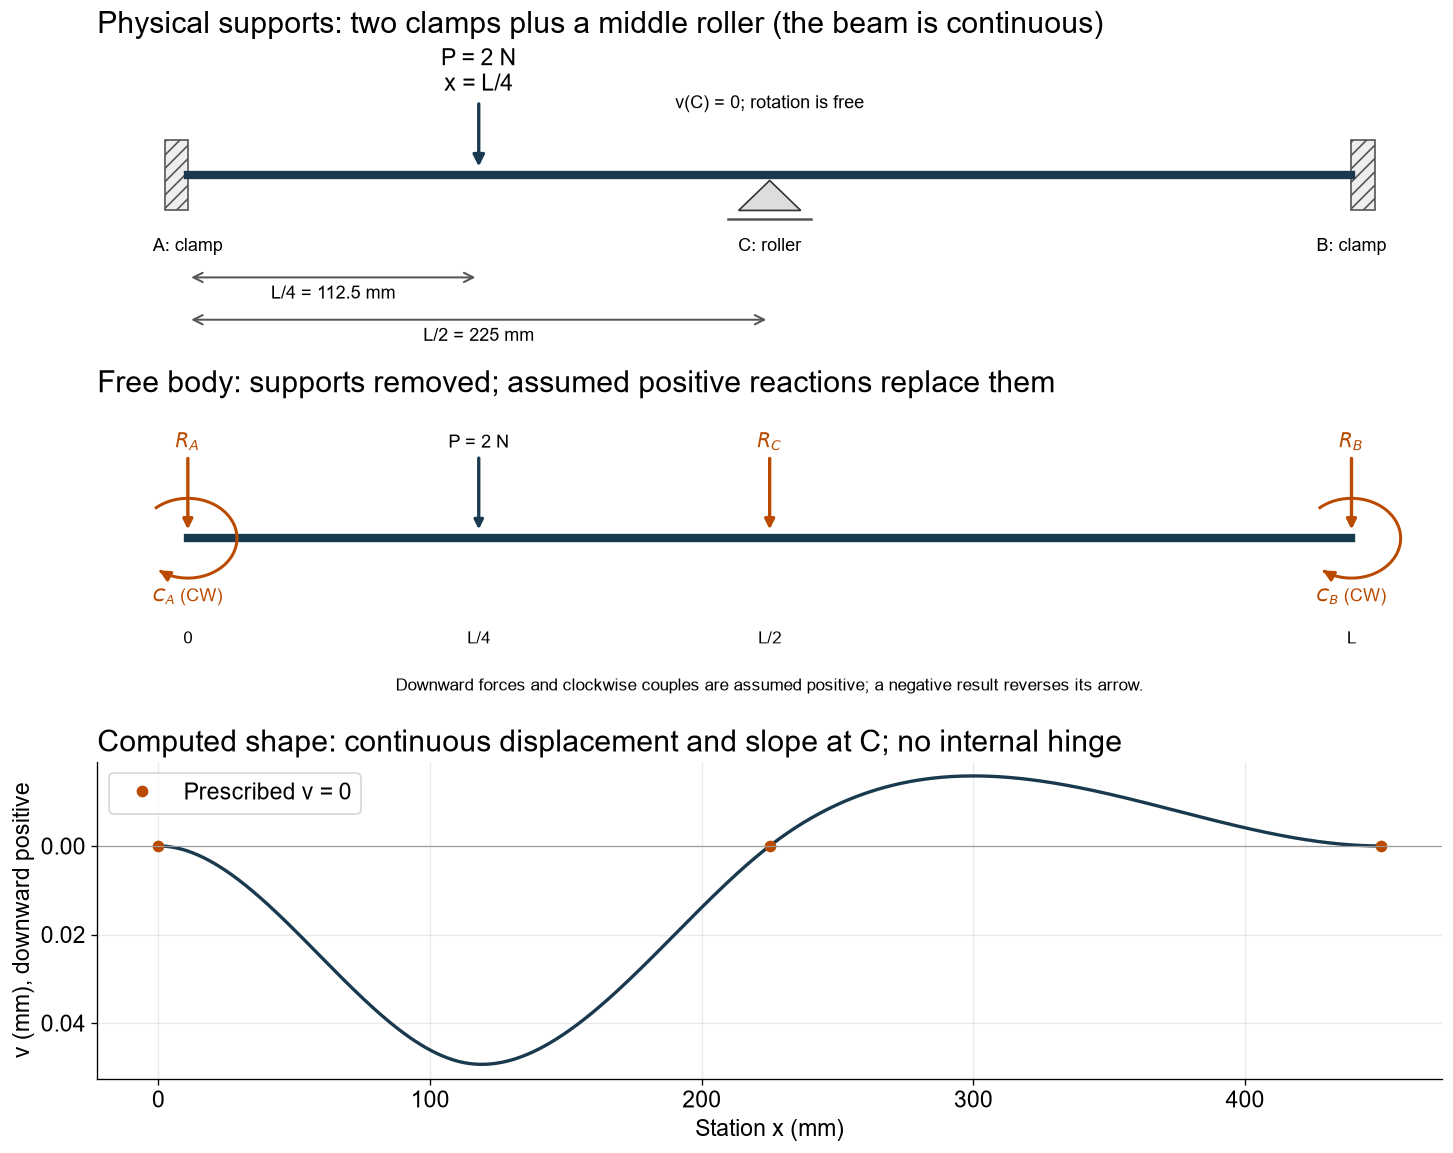

In [12]:
#@title A fixed-fixed beam with an additional middle roller: solve and check
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon, FancyArrowPatch


def lecture03_middle_support_example():
    span, support, force_at = 450.0, 225.0, 112.5  # mm
    force, elastic_modulus = 2.0, 2000.0          # N; MPa
    inertia = 20.0 * 10.0**3 / 12.0              # mm^4
    rigidity = elastic_modulus * inertia

    def reactions(load_station):
        # Columns: CA, RA, RC. Rows: theta(L), v(L), v(L/2).
        matrix = np.array([[span, -span**2/2, -(span-support)**2/2],
                           [span**2/2, -span**3/6, -(span-support)**3/6],
                           [support**2/2, -support**3/6, 0.0]])
        rhs = force*np.array([(span-load_station)**2/2,
                              (span-load_station)**3/6,
                              max(support-load_station, 0.0)**3/6])
        ca, ra, rc = np.linalg.solve(matrix, rhs)
        rb = -force-ra-rc
        cb = -ca-rb*span-rc*support-force*load_station
        return ca, ra, rc, rb, cb

    ca, ra, rc, rb, cb = reactions(force_at)
    def rotation(station):
        return -(ca*station-ra*station**2/2-force*np.maximum(station-force_at,0)**2/2
                 -rc*np.maximum(station-support,0)**2/2)/rigidity
    def displacement(station):
        return -(ca*station**2/2-ra*station**3/6-force*np.maximum(station-force_at,0)**3/6
                 -rc*np.maximum(station-support,0)**3/6)/rigidity
    assert max(abs(displacement(t)) for t in [0,support,span]) < 1e-10
    assert max(abs(rotation(t)) for t in [0,span]) < 1e-10
    assert abs(ra+rc+rb+force) < 1e-10
    assert abs(ca+cb+rc*support+rb*span+force*force_at) < 1e-8
    assert abs(rotation(support)) > 1e-6  # NOT constrained by the middle roller
    assert rc < 0                       # upward contact: no lift-off in this case
    assert np.allclose([ca,ra,rc,rb,cb],[-70.3125,-1.1875,-1.0,0.1875,-14.0625])
    direct = reactions(support)
    assert np.allclose(direct,[0,0,-force,0,0],atol=1e-9)
    print("Reactions (downward / clockwise positive):")
    print(f"RA = {ra:+.4f} N; RC = {rc:+.4f} N; RB = {rb:+.4f} N")
    print(f"CA = {ca:+.4f} N mm; CB = {cb:+.4f} N mm")
    print(f"theta(C) = {rotation(support):+.8f} rad: the roller is allowed to rotate.")
    print("RB is downward; an end clamp can transmit either sign of vertical reaction.")
    print("All five prescribed support motions and both equilibrium equations passed.")

    fig, axes = plt.subplots(3,1,figsize=(12,9.5),layout='constrained')
    ax = axes[0]
    ax.set_title("Physical supports: two clamps plus a middle roller (the beam is continuous)",loc='left')
    ax.plot([0,span],[0,0],lw=5,color='#19394e')
    for x0 in [-9,span]:
        ax.add_patch(Rectangle((x0,-20),9,40,facecolor='#eeeeee',edgecolor='#555555',hatch='///'))
    ax.add_patch(Polygon([[support, -3],[support-12,-20],[support+12,-20]],closed=True,
                         facecolor='#dddddd',edgecolor='#333333'))
    ax.plot([support-16,support+16],[-25,-25],color='#555555')
    ax.annotate('P = 2 N\nx = L/4', (force_at,3),(force_at,48),ha='center',
                arrowprops=dict(arrowstyle='-|>',lw=2,color='#19394e'))
    for station,label in [(0,'A: clamp'),(support,'C: roller'),(span,'B: clamp')]:
        ax.text(station,-43,label,ha='center',fontsize=11)
    ax.text(support,38,'v(C) = 0; rotation is free',ha='center',fontsize=11)
    for end,height,label in [(force_at,-58,'L/4 = 112.5 mm'),(support,-82,'L/2 = 225 mm')]:
        ax.annotate('', (0,height), (end,height),
                    arrowprops=dict(arrowstyle='<->',color='#555555',lw=1.2))
        ax.text(end/2,height-12,label,ha='center',fontsize=11)
    ax.set_xlim(-35,485);ax.set_ylim(-105,75);ax.axis('off')
    ax = axes[1]
    ax.set_title('Free body: supports removed; assumed positive reactions replace them',loc='left')
    ax.plot([0,span],[0,0],lw=5,color='#19394e')
    for station,name in [(0,r'$R_A$'),(support,r'$R_C$'),(span,r'$R_B$')]:
        ax.annotate(name,(station,3),(station,50),ha='center',fontsize=12,color='#ba4a00',
                    arrowprops=dict(arrowstyle='-|>',lw=2,color='#ba4a00'))
    ax.annotate('P = 2 N',(force_at,3),(force_at,50),ha='center',fontsize=11,
                arrowprops=dict(arrowstyle='-|>',lw=2,color='#19394e'))
    # Decreasing angle makes the ASSUMED reaction couples clockwise.
    for station,name in [(0,r'$C_A$'),(span,r'$C_B$')]:
        angles=np.linspace(np.deg2rad(130),np.deg2rad(-130),100)
        xx=station+19*np.cos(angles);yy=22*np.sin(angles)
        ax.plot(xx[:-4],yy[:-4],color='#ba4a00',lw=1.8)
        ax.add_patch(FancyArrowPatch((xx[-5],yy[-5]),(xx[-1],yy[-1]),
                                    arrowstyle='-|>',mutation_scale=13,lw=1.8,color='#ba4a00'))
        ax.text(station,-35,name+' (CW)',ha='center',fontsize=11,color='#ba4a00')
    for station,label in [(0,'0'),(force_at,'L/4'),(support,'L/2'),(span,'L')]:
        ax.text(station,-58,label,ha='center',fontsize=10)
    ax.text(span/2,-84,'Downward forces and clockwise couples are assumed positive; a negative result reverses its arrow.',
            ha='center',fontsize=10)
    ax.set_xlim(-35,485);ax.set_ylim(-100,75);ax.axis('off')
    ax = axes[2]
    positions = np.unique(np.r_[np.linspace(0,span,901),support,force_at])
    ax.plot(positions,displacement(positions),color='#19394e',lw=2)
    ax.plot([0,support,span],[0,0,0],'o',color='#ba4a00',label='Prescribed v = 0')
    ax.axhline(0,color='#999999',lw=.7)
    ax.set_xlabel('Station x (mm)');ax.set_ylabel('v (mm), downward positive')
    ax.invert_yaxis();ax.grid(alpha=.25);ax.legend(loc='best')
    ax.set_title('Computed shape: continuous displacement and slope at C; no internal hinge',loc='left')
    return fig


lecture03_middle_support_example()
plt.show()


## 3. A cut reveals the internal shear and moment

Isolate the portion to the right of a cut at x. The tip force still acts on it. The cut must supply a shear force and bending moment to balance that portion. **Internal forces are not additional applied loads:** on opposite cut faces they form equal-and-opposite pairs.

Use the app convention throughout the following diagrams: downward load q and deflection v positive; positive internal M is sagging; z positive upward from the neutral axis.

$$V(x)=P,\qquad M(x)=-P(L-x),\qquad 0<x<L.$$

At (x=150) mm, (V=2) N and (M=-600) N mm. At the root-side section, M=-900 N mm. At the tip, (M=0). Shear has a jump at a point force; do not interpret a vertical jump as a finite-length triangular load.

For a distributed downward-positive load:

$$\frac{dV}{dx}=-q(x),\qquad \frac{dM}{dx}=V(x).$$

In words: load changes the shear; shear changes the moment. A constant shear produces a straight-line moment diagram.

### Calculate at a cut rather than memorize a diagram

At x = 150 mm the outboard portion is 300 mm long. Its 2 N tip load produces a 600 N mm clockwise external turning effect about the cut. The cut therefore supplies 2 N upward and a 600 N mm counterclockwise couple to that outboard portion. These are the physical arrows in Figure 2. With the app's internal sagging-positive convention, the reported section values are V = +2 N and M = −600 N mm.

| Cut station x | Remaining lever arm L − x | V | M = −P(L − x) |
|---:|---:|---:|---:|
| 0 mm, just inside the root | 450 mm | +2 N | −900 N mm |
| 150 mm | 300 mm | +2 N | −600 N mm |
| 300 mm | 150 mm | +2 N | −300 N mm |
| 450 mm, just inside the tip | 0 mm | +2 N | 0 N mm |

The derivative relations are local equilibrium statements. Over a short distance Δx, downward distributed load qΔx decreases V by approximately qΔx. Moment changes by approximately VΔx. Therefore a uniform q gives a linear V diagram and a curved, quadratic M diagram; with no line load between root and tip, V is constant.

Right-piece equilibrium: 2 N up - 2 N down = 0; 600 N mm CCW - 2 N x 300 mm CW = 0.
On the opposite cut face, BOTH cut arrows reverse. Internal actions are not extra applied loads.


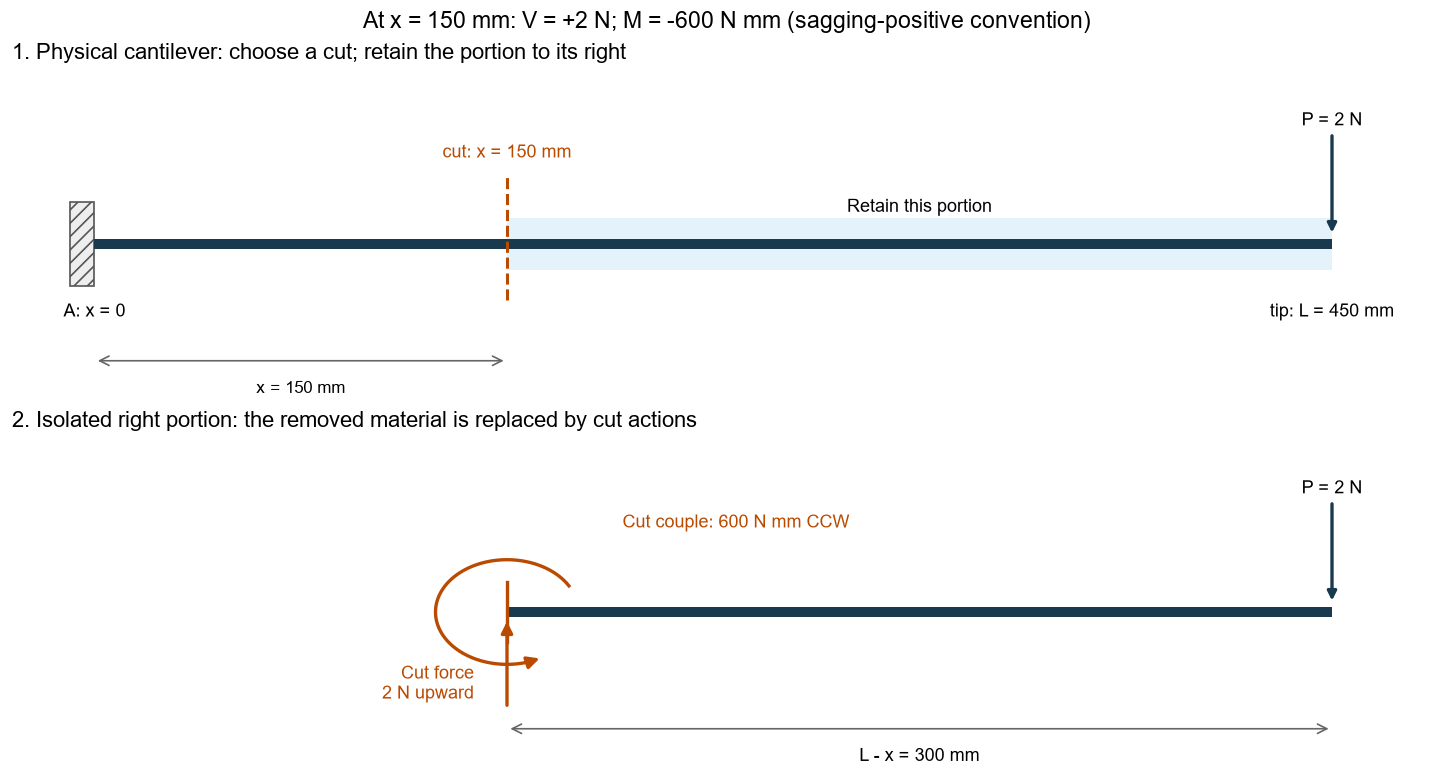

In [13]:
#@title Figure 2A — where the cut actions come from (run this schematic)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch


def lecture03_cut_schematic():
    span, cut, load = 450.0, 150.0, 2.0
    lever = span - cut
    shear, moment = load, -load * lever
    # Vertical force and moment balance of the isolated RIGHT portion.
    assert abs(shear - load) < 1e-12
    assert abs((-moment) - load * lever) < 1e-12
    fig, axes = plt.subplots(2, 1, figsize=(12, 6.4), layout="constrained")
    blue, orange = "#19394e", "#ba4a00"
    for ax in axes:
        ax.set_xlim(-30, 490)
        ax.set_ylim(-78, 82)
        ax.axis("off")
    ax = axes[0]
    ax.set_title("1. Physical cantilever: choose a cut; retain the portion to its right", loc="left", fontsize=13, pad=12)
    ax.add_patch(Rectangle((-9, -21), 9, 42, facecolor="#eeeeee", edgecolor="#555555", hatch="///"))
    ax.plot([0, span], [0, 0], color=blue, lw=6, solid_capstyle="butt")
    ax.plot([cut, cut], [-28, 35], ls="--", color=orange, lw=1.8)
    ax.add_patch(Rectangle((cut, -13), lever, 26, facecolor="#e4f2fb", edgecolor="none", zorder=0))
    ax.annotate("P = 2 N", (span, 4), (span, 59), ha="center", fontsize=11,
                arrowprops=dict(arrowstyle="-|>", lw=2, color=blue))
    ax.text(0, -36, "A: x = 0", ha="center", fontsize=11)
    ax.text(cut, 43, "cut: x = 150 mm", ha="center", color=orange, fontsize=11)
    ax.text(300, 16, "Retain this portion", ha="center", fontsize=11)
    ax.text(span, -36, "tip: L = 450 mm", ha="center", fontsize=11)
    ax.annotate("", (0, -58), (cut, -58), arrowprops=dict(arrowstyle="<->", color="#666666"))
    ax.text(cut / 2, -74, "x = 150 mm", ha="center", fontsize=10)

    ax = axes[1]
    ax.set_title("2. Isolated right portion: the removed material is replaced by cut actions", loc="left", fontsize=13, pad=12)
    ax.plot([cut, span], [0, 0], color=blue, lw=6, solid_capstyle="butt")
    ax.plot([cut, cut], [-15, 15], color=orange, lw=2)
    ax.annotate("", (cut, -3), (cut, -48), arrowprops=dict(arrowstyle="-|>", lw=2, color=orange))
    ax.text(cut - 12, -43, "Cut force\n2 N upward", ha="right", color=orange, fontsize=11)
    ax.annotate("P = 2 N", (span, 4), (span, 59), ha="center", fontsize=11,
                arrowprops=dict(arrowstyle="-|>", lw=2, color=blue))
    # Increasing polar angle draws a genuinely counterclockwise couple.
    angles = np.linspace(np.deg2rad(30), np.deg2rad(300), 100)
    xx, yy = cut + 26 * np.cos(angles), 26 * np.sin(angles)
    ax.plot(xx[:-4], yy[:-4], color=orange, lw=2)
    ax.add_patch(FancyArrowPatch((xx[-5], yy[-5]), (xx[-1], yy[-1]),
                                arrowstyle="-|>", mutation_scale=15, lw=2, color=orange))
    ax.text(cut + 42, 42, "Cut couple: 600 N mm CCW", ha="left", color=orange, fontsize=11)
    ax.annotate("", (cut, -58), (span, -58), arrowprops=dict(arrowstyle="<->", color="#666666"))
    ax.text((cut + span) / 2, -74, "L - x = 300 mm", ha="center", fontsize=11)
    fig.suptitle("At x = 150 mm: V = +2 N; M = -600 N mm (sagging-positive convention)", fontsize=14)
    print("Right-piece equilibrium: 2 N up - 2 N down = 0; 600 N mm CCW - 2 N x 300 mm CW = 0.")
    print("On the opposite cut face, BOTH cut arrows reverse. Internal actions are not extra applied loads.")
    return fig


lecture03_cut_schematic()
plt.show()


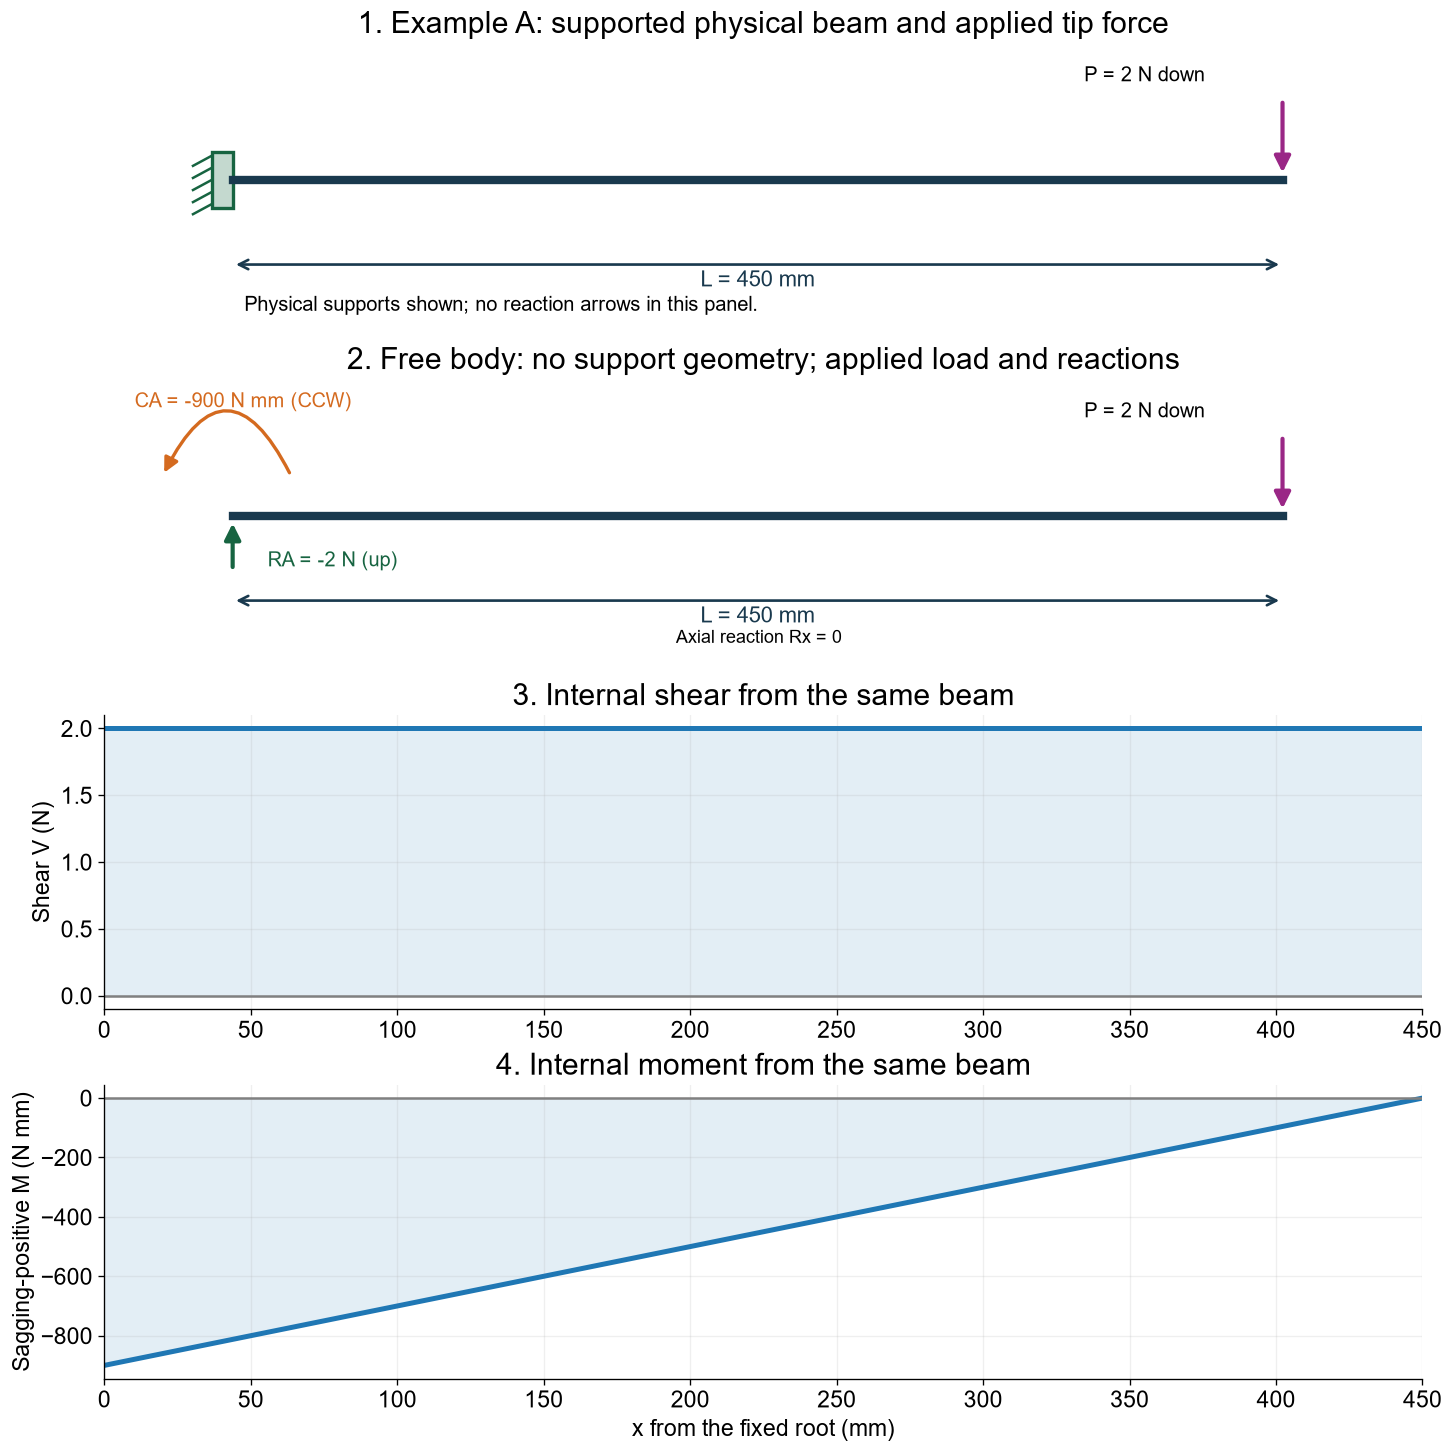

In [14]:
#@title Figure 3 — physical beam, its free body, then V and M diagrams
V=np.full_like(x,P);M=-P*(L-x)
fig,axes=plt.subplots(4,1,figsize=(12,12),layout='constrained')
beam_system_or_fbd(axes[0],'cantilever','1. Example A: supported physical beam and applied tip force',station=L)
beam_system_or_fbd(axes[1],'cantilever','2. Free body: no support geometry; applied load and reactions',station=L,fbd=True)
for ax,yy,label in zip(axes[2:],[V,M],['Shear V (N)','Sagging-positive M (N mm)']):
    ax.plot(x,yy,lw=3);ax.fill_between(x,yy,0,alpha=.12)
    ax.axhline(0,color='gray');ax.set_ylabel(label);ax.grid(alpha=.2);ax.set_xlim(0,L)
axes[2].set_title('3. Internal shear from the same beam')
axes[3].set_title('4. Internal moment from the same beam')
axes[3].set_xlabel('x from the fixed root (mm)')
plt.show()

## 4. Learn stress before using the beam stress equation

### 4.1. Force across a small surface

Imagine cutting through material and examining a small surface patch of area ΔA. The material on the other side transmits a force ΔF across that patch. **Traction** is the force vector per surface area:

$$\mathbf t(\mathbf n)=\lim_{\Delta A\to0}\frac{\Delta\mathbf F}{\Delta A}.$$

The unit normal n identifies which surface is being examined. Resolve this force into a component perpendicular to that face and components tangent to it:

$$\sigma_n=\frac{F_n}{A},\qquad \tau=\frac{F_t}{A}\quad\text{for uniform components over an area}.$$

**Normal stress means perpendicular to the face**, not necessarily vertical in the room. On a beam cross-section normal to x, normal stress σₓₓ acts along the beam. A force parallel to that face produces shear stress. N/mm² is MPa. The average F/A does not tell us whether stress is uniform: bending produces a varying distribution.

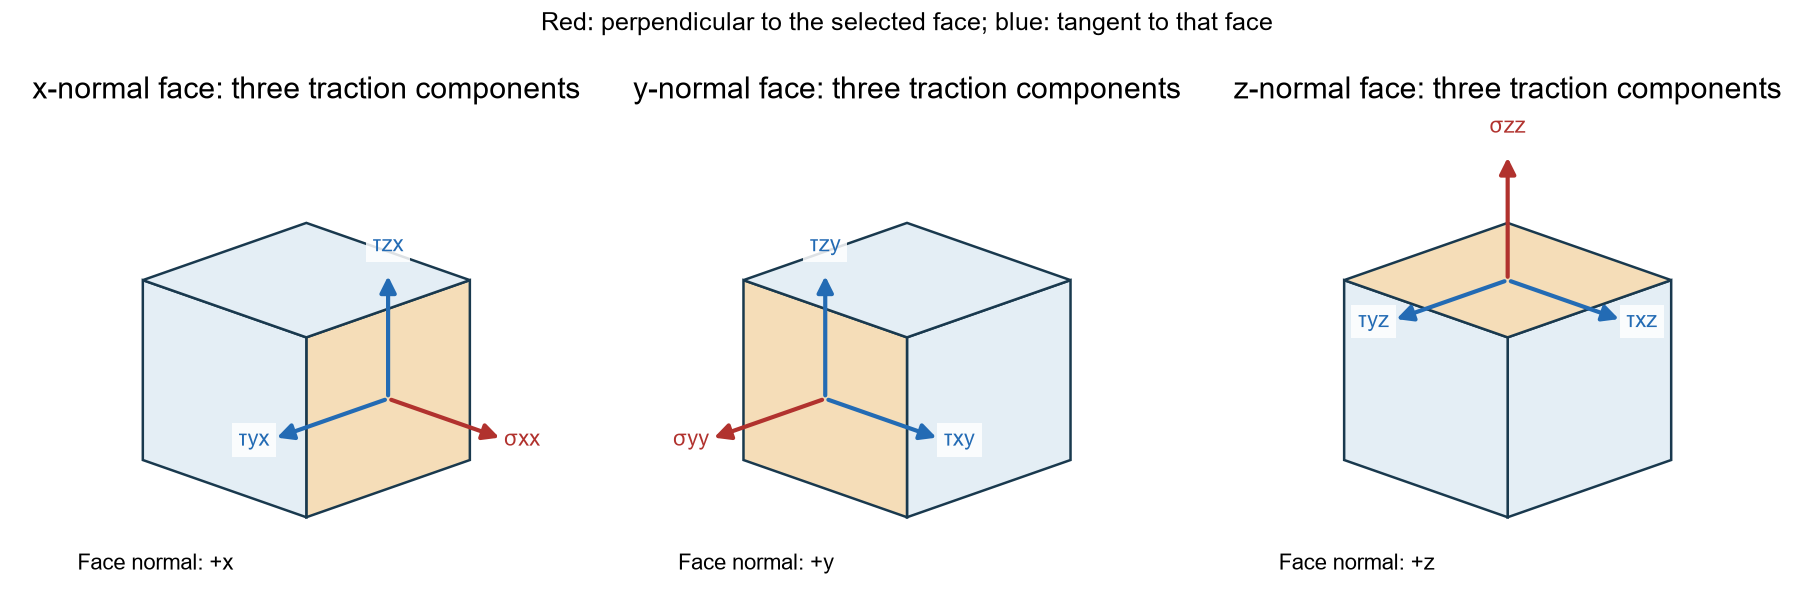

In [15]:
#@title Stress element — normal and tangential traction on x, y and z faces
fig,axes=plt.subplots(1,3,figsize=(15,5.5),layout='constrained')
proj=lambda p:np.array([p[0]-p[1],1.1*p[2]-.35*(p[0]+p[1])])
vectors=[proj([1,0,0]),proj([0,1,0]),proj([0,0,1])]
faces=[[[1,0,0],[1,1,0],[1,1,1],[1,0,1]],
       [[0,1,0],[1,1,0],[1,1,1],[0,1,1]],
       [[0,0,1],[1,0,1],[1,1,1],[0,1,1]]]
names=['x','y','z']
for j,ax in enumerate(axes):
    for k,face in enumerate(faces):
        ax.add_patch(Polygon([proj(p) for p in face],facecolor='#e4eef5' if k!=j else '#f5ddb8',edgecolor='#19394e',lw=1.5))
    origin=proj(np.mean(faces[j],axis=0))
    for i,vector in enumerate(vectors):
        target=origin+.70*vector
        arrow(ax,origin,target,'#b1322e' if i==j else '#236bb4')
        label=('σ' if i==j else 'τ')+names[i]+names[j]
        ax.text(*(target+.12*vector),label,color='#b1322e' if i==j else '#236bb4',ha='center',fontsize=13,
                bbox=dict(facecolor='white',edgecolor='none',alpha=.85))
    ax.text(-1.4,-1.02,f'Face normal: +{names[j]}',fontsize=13)
    ax.set(xlim=(-1.8,1.8),ylim=(-1.2,1.8),title=f'{names[j]}-normal face: three traction components')
    ax.set_aspect('equal');ax.axis('off')
fig.suptitle('Red: perpendicular to the selected face; blue: tangent to that face',fontsize=15)
plt.show()

### 4.2. Stress tensor — select a face, then select a force direction

We use σᵢⱼ = force/traction component in direction i on a face with normal in direction j. For example, σ_zx is the vertical shear on an x-normal beam cut, while σ_xz is longitudinal shear on a z-normal face. They act on different faces. In a classical continuum without couple stresses, moment balance gives σ_zx = σ_xz.

$$\boldsymbol{\sigma}=
\begin{bmatrix}
\sigma_{xx}&\tau_{xy}&\tau_{xz}\\
\tau_{yx}&\sigma_{yy}&\tau_{yz}\\
\tau_{zx}&\tau_{zy}&\sigma_{zz}
\end{bmatrix},
\qquad \mathbf t(\mathbf n)=\boldsymbol{\sigma}\mathbf n.$$

Diagonal entries are normal stresses. Off-diagonal entries are shear stresses. Three faces times three components makes nine entries; symmetry leaves six independent components. The cube drawing identifies each component. The beam model below retains the dominant longitudinal bending stress and transverse shear; it does not compute every component of a three-dimensional solid.

The cube arrows illustrate positive tensor components, not the numerical load case. Reversing a face normal reverses its traction vector. [MIT primary reading on stress and equilibrium](https://ocw.mit.edu/courses/2-080j-structural-mechanics-fall-2013/8e61abd2b094e2214465ce18ab8eb440_MIT2_080JF13_Lecture3.pdf).

### 4.3. First draw the cross-section — then calculate A and I

The next drawing fixes b, h, z, c and the neutral axis before area or stress calculations. Width b lies along y; height h lies along z. A thin horizontal strip has area dA = b dz.

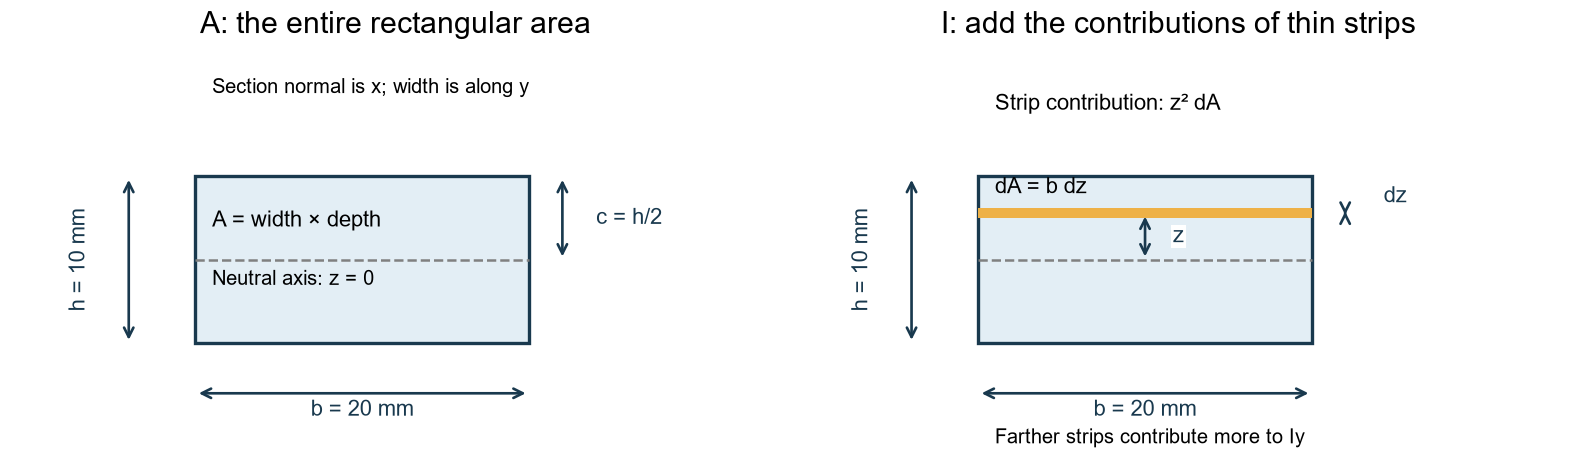

In [16]:
#@title Figure 4 — draw the area and dimensions before calculating A and I
fig,axes=plt.subplots(1,2,figsize=(13,5.5),layout='constrained')
for ax in axes:
    ax.add_patch(Rectangle((-b/2,-h/2),b,h,facecolor='#e3eef5',edgecolor='#19394e',lw=2))
    ax.plot([-b/2,b/2],[0,0],'--',color='gray')
    dimension(ax,(-b/2,-8),(b/2,-8),'b = 20 mm',(0,-1))
    dimension(ax,(-14,-h/2),(-14,h/2),'h = 10 mm',(-3,0),rotation=90)
    ax.set(xlim=(-21,25),ylim=(-12,13));ax.set_aspect('equal');ax.axis('off')
axes[0].set_title('A: the entire rectangular area')
axes[0].text(-9,2,'A = width × depth',fontsize=13)
axes[0].text(-9,-1.5,'Neutral axis: z = 0',fontsize=12)
dimension(axes[0],(12,0),(12,h/2),'c = h/2',(4,0))
axes[0].text(-9,10,'Section normal is x; width is along y',fontsize=12)
axes[1].set_title('I: add the contributions of thin strips')
axes[1].add_patch(Rectangle((-b/2,2.5),b,.6,facecolor='#eeb147'))
dimension(axes[1],(0,0),(0,2.8),'z',(2,0))
axes[1].text(-9,4,'dA = b dz',fontsize=13)
dimension(axes[1],(12,2.5),(12,3.1),'dz',(3,1))
axes[1].text(-9,9,'Strip contribution: z² dA',fontsize=13)
axes[1].text(-9,-11,'Farther strips contribute more to Iy',fontsize=12)
plt.show()

$$A=bh=(20)(10)=200\ \mathrm{mm^2},$$

$$I_y=\int_A z^2\,dA=b\int_{-h/2}^{h/2}z^2\,dz
=\frac{bh^3}{12}=1666.6667\ \mathrm{mm^4},\qquad c=h/2=5\ \mathrm{mm}.$$

A counts area once. I weights it by distance squared from the neutral axis, so material farther away has more bending leverage. I is section geometry, not material stiffness or mass moment of inertia. E = 2000 MPa is our assumed material modulus; EI combines material and geometry.

### 4.4. Bending normal stress on this section

For the root section of Example A, M = −PL = −900 N mm. With sagging-positive M, upward-positive z and tension-positive stress:

$$\boxed{\sigma_{xx}(z)=-\frac{Mz}{I_y}},\qquad
|\sigma_{\max}|=\frac{|M|c}{I_y}=2.70\ \mathrm{MPa}.$$

At z = +5 mm the stress is +2.70 MPa (top tension); at z = 0 it is zero; at z = −5 mm it is −2.70 MPa (bottom compression). These are stresses **along x**, drawn on the cross-section normal to x. Section 5 derives this relation from fibre strain and material response.

The earlier shorthand σₓ means this component σₓₓ; εₓ likewise means longitudinal εₓₓ. A direction subscript is not an extra variable.

A horizontal strip spans the full constant width b, so dA=b dz. The whole rectangle runs from z=-h/2 to z=+h/2:

$$A=\int_{-h/2}^{h/2}b\,dz
=b[z]_{-h/2}^{h/2}
=b\left(\frac h2-\left[-\frac h2\right]\right)=bh=200\ \mathrm{mm^2}.$$

For the second moment, use the same strip and bounds, now weighting every strip by z²:

$$\begin{aligned}
I_y&=b\int_{-h/2}^{h/2}z^2\,dz
=b\left[\frac{z^3}{3}\right]_{-h/2}^{h/2}\\
&=\frac b3\left[\left(\frac h2\right)^3-\left(-\frac h2\right)^3\right]
=\frac b3\left(\frac{h^3}{8}+\frac{h^3}{8}\right)
=\frac{bh^3}{12}\\
&=20\left[\frac{z^3}{3}\right]_{-5}^{5}
=\frac{20}{3}[125-(-125)]
=1666.6667\ \mathrm{mm^4}.
\end{aligned}$$

The lower half contributes positively too: the integrand is z², even where z<0. This is why the two halves add rather than cancel.

### 4.4A. What Wing Lab solves, and which stress its colours represent

The same sequence connects this rectangle to the wing: **applied loads → support reactions and internal resultants → section strain/stress → reported values**. A 3-D picture does not by itself mean that a program solves a three-dimensional solid stress field.

**1. Equilibrium and structural motion.** For the regular positive-tip-chord spatial-beam pathway, Wing Lab assembles beam-element stiffness and loads, imposes the root restraints and solves:

$$\mathbf K\mathbf u=\mathbf f,\qquad
\mathbf r=\mathbf K\mathbf u-\mathbf f.$$

Each spatial node has three translations and three rotations. Geometry, material stiffness and section properties enter K; the applied forces and their offsets enter f. Reactions are recovered at restrained degrees of freedom. Cut equilibrium gives axial force, transverse shear, bending moments and a span-axis moment. These are forces/moments (N and N mm), **not stresses**. The original straight planar pathway is a reduced bending/torsion model; it does not have all the spatial degrees of freedom.

**2. Recover the longitudinal normal stress.** At a cut through the wing, let s be the local span direction and let ξ and ζ be section coordinates. For a homogeneous section, the nominal longitudinal beam stress is an affine field:

$$\sigma_{ss}(\xi,\zeta)=a_0+b_0\xi+c_0\zeta.$$

The coefficients must reproduce the section's axial force and two bending moments. With right-handed axes (ξ, s, ζ), traction σₛₛ along +s on the positive cut face gives:

$$N_s=\int_A\sigma_{ss}\,dA,\qquad
M_\xi=-\int_A\zeta\sigma_{ss}\,dA,\qquad
M_\zeta=\int_A\xi\sigma_{ss}\,dA.$$

For the symmetric solid rectangle with no axial force and bending about one axis, these reduce to the familiar σₓₓ = −Mz/I in this notebook. For an airfoil with skin, spars or different materials, the program uses its modeled section geometry and stiffness distribution; do not insert the rectangle's bh³/12 as the wing's I. Perfectly bonded components share compatible section motion; member/material stresses can differ.

**3. Read the contour as a particular component.** Wing Lab's normal-stress contour is nominal longitudinal stress along the wing, the counterpart of this notebook's σₓₓ. Positive means tension and negative means compression. Read the legend, units and selected component: it is not automatically a von Mises equivalent stress or a full tensor containing every normal and shear component. Shear force V and torque T have their own section effects; they are not added directly to a normal stress. The rectangular formula VQ/(Ib) derived next is a shear-stress recovery for that rectangle, not a general formula to paste onto every hollow wing section.

**Closed-tip delta/elliptical pathway:** the exact zero-chord tip uses a separate section-equilibrium calculation. It integrates the physical outboard loads, recovers nominal normal stress on finite-area cuts, and integrates bending curvature to obtain the available bending-displacement components. It does **not** provide a torsional/full-motion solution or a defined stress at the exact zero-area apex. A bending-only displacement must not be reported as a complete displacement including twist.

These are beam/section approximations, not a volume mesh solving all components of three-dimensional elasticity. Local load introduction, bonds, holes, spar runout, warping and buckling are not resolved by the normal-stress colour map. Compare the same load, section, material and sign conventions before comparing a notebook calculation with the program.


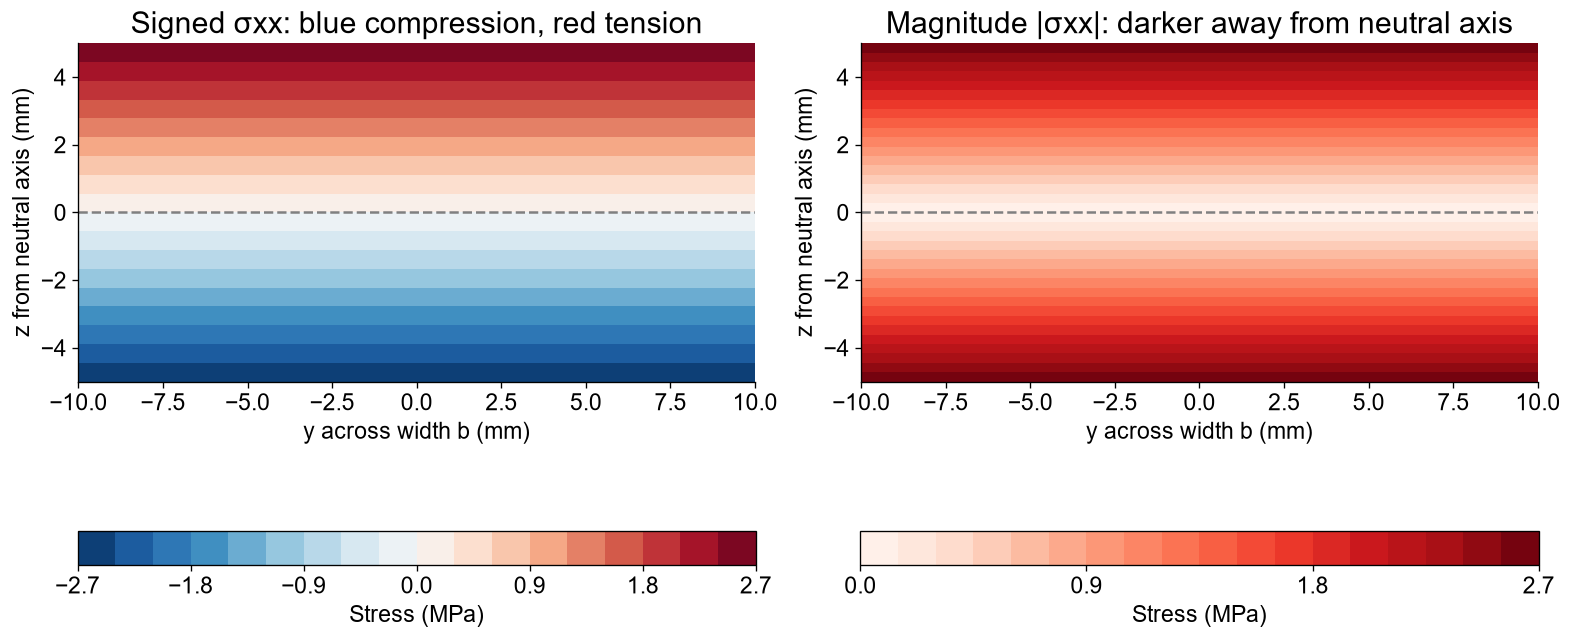

In [17]:
#@title Bending stress contour on the root cross-section — not a damage plot
yy,zz=np.meshgrid(np.linspace(-b/2,b/2,121),np.linspace(-h/2,h/2,121))
normal_field=P*L*zz/I
normal_peak=max(float(np.max(abs(normal_field))),1e-12)
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
for ax,field,cmap,levels,title in [
 (axes[0],normal_field,'RdBu_r',np.linspace(-normal_peak,normal_peak,19),'Signed σxx: blue compression, red tension'),
 (axes[1],abs(normal_field),'Reds',np.linspace(0,normal_peak,19),'Magnitude |σxx|: darker away from neutral axis')]:
    image=ax.contourf(yy,zz,field,levels=levels,cmap=cmap)
    ax.axhline(0,color='gray',ls='--');ax.set(xlabel='y across width b (mm)',ylabel='z from neutral axis (mm)',title=title)
    ticks=np.linspace(-normal_peak,normal_peak,7) if ax is axes[0] else np.linspace(0,normal_peak,4)
    ax.set_aspect('equal');fig.colorbar(image,ax=ax,orientation='horizontal',pad=.22,label='Stress (MPa)',ticks=ticks)
plt.show()
assert np.isclose(normal_field[-1,0],P*L*h/(2*I)) and np.isclose(normal_field[0,0],-P*L*h/(2*I))

**Read the contour:** red means tension, blue means compression. Colour intensity increases with |z|, not monotonically with signed z across both halves. In the upper half, increasing z makes tension darker; moving downward below the neutral axis makes compression darker. The second panel shows magnitude only. Both plots are analytical fields on the solid rectangle, not a 3-D finite-element result or a damage image.

**Why not simply divide 2 N by A?** The 2 N applied force is transverse to the beam, so 2/200 = 0.010 MPa is an average transverse shear, not the longitudinal bending stress. Bending produces a tension/compression couple: integrating the root stress over the upper half gives 135 N tension, and the lower half gives 135 N compression. Their net axial force is zero but their combined moment is 900 N mm. Normal stress can therefore be large even though no net axial force is applied.

### 4.5. What Q means physically

Choose a horizontal cut at z = +2.5 mm and select only the material **above** it. Its first moment about the neutral axis is:

$$Q(z)=\int_{A^*}z'\,dA=A^*\bar z^*
=\frac b2\left[\left(\frac h2\right)^2-z^2\right].$$

Q is not a load and not merely area. Its mm³ units combine selected area and its centroid's bending lever arm. I describes the whole section with z² weighting; Q describes this selected region with z weighting.

#### Integrate the bending stress to recover force and moment

At the cantilever root, M=-900 N mm, hence σ_xx=900z/I. For the upper half, 0≤ z≤5 mm:

$$\begin{aligned}
N_+&=\int_{A_+}\sigma_{xx}\,dA
=\frac{900b}{I}\int_0^5z\,dz
=\frac{900(20)}{1666.6667}\left[\frac{z^2}{2}\right]_0^5\\
&=10.8(12.5)=+135\ \mathrm N.
\end{aligned}$$

For the lower half, keep the signed coordinate:

$$N_-=\frac{900b}{I}\left[\frac{z^2}{2}\right]_{-5}^{0}
=10.8(0-12.5)=-135\ \mathrm N.$$

Thus N_++N_-=0: bending does not create a net axial force. Recovering the signed moment uses a **different** weighting:

$$-\int_A z\sigma_{xx}\,dA
=-\frac{900}{I}\int_Az^2\,dA=-900\ \mathrm{N\,mm}=M.$$

Equivalently, each triangular half-stress resultant acts 2(5)/3=3.3333 mm from the neutral axis. The two 135 N resultants form a couple of magnitude 135(3.3333+3.3333)=900 N mm. They are longitudinal forces, not additional applied vertical loads.

#### Integrate the selected area's first moment

For a horizontal cut at coordinate z, select only the rectangle above it. Use z' as the integration variable so that the fixed lower limit z is not confused with a running coordinate:

$$\begin{aligned}
Q(z)&=\int_{A^*}z'\,dA=b\int_z^{h/2}z'\,dz'\\
&=b\left[\frac{(z')^2}{2}\right]_z^{h/2}
=\frac b2\left[\left(\frac h2\right)^2-z^2\right].
\end{aligned}$$

At z=2.5 mm:

$$Q=\frac{20}{2}[5^2-2.5^2]
=10(25-6.25)=187.5\ \mathrm{mm^3}.$$

Check without calculus: selected area A^*=20(5-2.5)=50 mm², centroid z̄^*=(5+2.5)/2=3.75 mm, so A^*z̄^*=50(3.75)=187.5 mm³. At the top, the selected area shrinks to zero, so Q(5)=0; at the neutral axis, Q(0)=250 mm³.

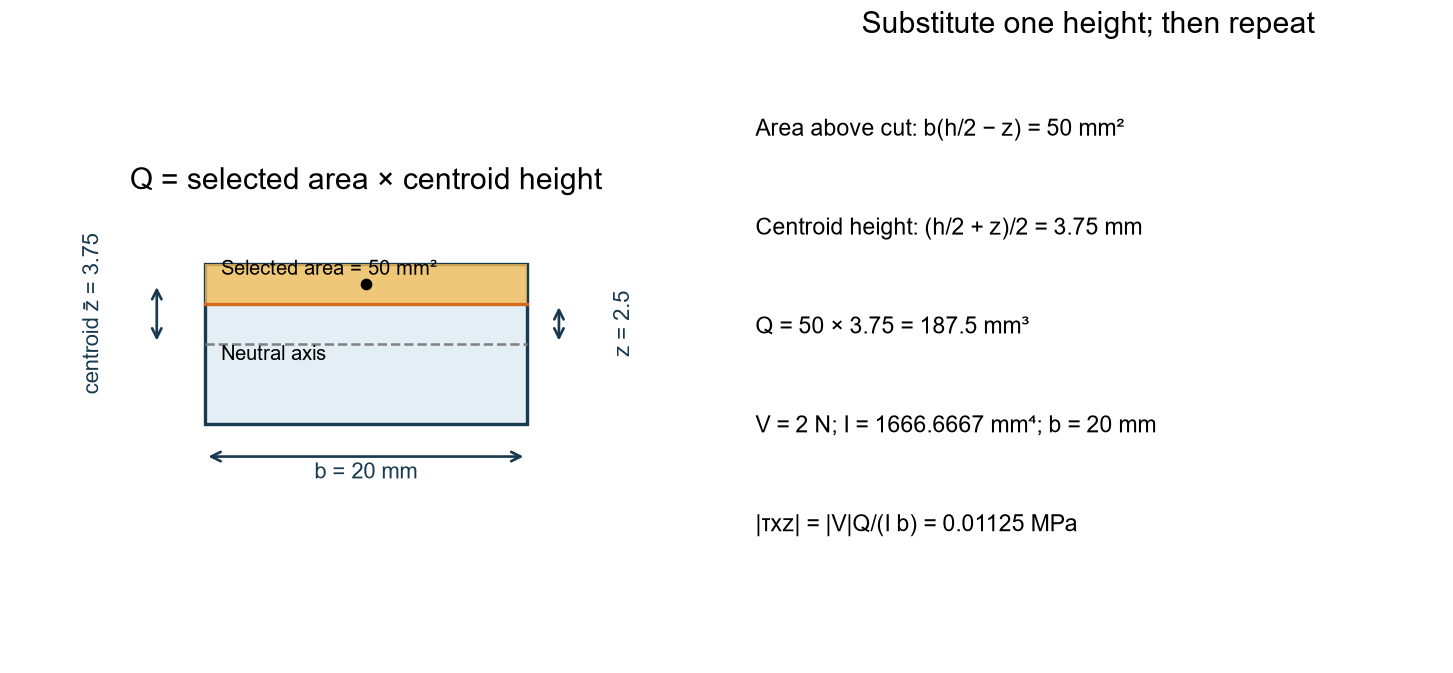

In [18]:
#@title Figure 4B — first moment Q uses the area above a chosen cut
fig,axes=plt.subplots(1,2,figsize=(12,5.5),layout='constrained')
ax=axes[0]; chosen_z=2.5
ax.add_patch(Rectangle((-10,-5),20,10,facecolor='#e3eef5',edgecolor='#19394e',lw=2))
ax.add_patch(Rectangle((-10,chosen_z),20,5-chosen_z,facecolor='#f1be5a',alpha=.8))
ax.plot([-10,10],[chosen_z,chosen_z],color='#d46a1f',lw=2)
ax.plot([-10,10],[0,0],'--',color='gray')
ax.plot(0,3.75,'ko')
ax.text(-9,4.3,'Selected area = 50 mm²',fontsize=12)
ax.text(-9,-1,'Neutral axis',fontsize=12)
dimension(ax,(12,0),(12,chosen_z),'z = 2.5',(4,0),rotation=90)
dimension(ax,(-13,0),(-13,3.75),'centroid z̄ = 3.75',(-4,0),rotation=90)
dimension(ax,(-10,-7),(10,-7),'b = 20 mm',(0,-1))
ax.set(xlim=(-22,22),ylim=(-10,9),title='Q = selected area × centroid height')
ax.set_aspect('equal');ax.axis('off')
ax=axes[1];ax.axis('off')
lines=['Area above cut: b(h/2 − z) = 50 mm²',
       'Centroid height: (h/2 + z)/2 = 3.75 mm',
       'Q = 50 × 3.75 = 187.5 mm³',
       'V = 2 N; I = 1666.6667 mm⁴; b = 20 mm',
       '|τxz| = |V|Q/(I b) = 0.01125 MPa']
for j,line in enumerate(lines):
    ax.text(.03,.85-j*.16,line,transform=ax.transAxes,fontsize=14)
ax.set_title('Substitute one height; then repeat')
plt.show()

### Why that selected area requires shear transfer

The longitudinal bending-force resultant carried by the shaded upper material is:

$$N^*(x)=\int_{A^*}\sigma_{xx}\,dA=-\frac{M(x)Q}{I}.$$

Because bending moment changes along x, this force changes from one cut to a neighbouring cut. Shear across the lower boundary of the shaded material transfers the difference. The next diagram isolates that upper slice. Its longitudinal force balance is −Nₗ + Nᵣ + F_interface = 0. These longitudinal forces are not the 2 N vertical load.

Since dM/dx = V, the required shear-force transfer per unit span is |s| = |VQ|/I. Divide by the solid width b of the interface to obtain shear-stress magnitude:

$$\boxed{|\tau_{xz}|=\frac{|V|Q}{Ib}},\qquad \tau_{zx}=\tau_{xz}.$$

The second equality is complementary shear from stress symmetry. Thus the same magnitude appears as vertical shear on a beam cross-section and longitudinal shear on the horizontal interface.

**Face signs matter:** the isolated upper slice's lower interface has normal −z and receives force in +x. Consequently its positive-face tensor component σ_xz is negative. With the app's M′ = V convention, τxz = τzx = −VQ/(Ib). On the outboard portion's left face (normal −x), that negative component produces an upward traction. The following contour deliberately shows magnitude, not signed components.

[Roylance's beam-stress derivation](https://eng.libretexts.org/Bookshelves/Mechanical_Engineering/Mechanics_of_Materials_(Roylance)/04:_Bending/4.02:_Stresses_in_Beams) explains the selected-area force transfer; its coordinate/index conventions differ, so use the explicit convention of this notebook.

#### Use two neighbouring cuts to see the shear transfer

For a prismatic section and a fixed horizontal cut, Q and I do not change with x. Integrating the bending stress over that same selected upper material gives

$$N^*(x)=\int_{A^*}\left[-\frac{M(x)z'}{I}\right]dA
=-\frac{M(x)}{I}\underbrace{\int_{A^*}z'\,dA}_{Q}
=-\frac{M(x)Q}{I}.$$

The force at the next cut is

$$N^*(x+\Delta x)-N^*(x)
=-\frac{Q}{I}[M(x+\Delta x)-M(x)].$$

Since M'=V, division by Δ x followed by the small-slice limit gives

$$\frac{dN^*}{dx}=-\frac{VQ}{I}.$$

The upper slice has a left-face force -N^*(x), a right-face force +N^*(x+Δ x), and a longitudinal interface force F_interface. Its balance therefore requires

$$F_{\mathrm{interface}}=N^*(x)-N^*(x+\Delta x)
\approx\frac{VQ}{I}\Delta x.$$

At the chosen z=2.5 mm cut, V=2 N gives VQ/I=0.225 N/mm. For example, from x=150 to 160 mm, M changes from -600 to -580 N mm, while N^* changes from 67.50 to 65.25 N. Balance reads

$$-67.50+65.25+2.25=0\ \mathrm N.$$

The interface area is bΔ x. Dividing its force magnitude by this area cancels Δ x:

$$|\tau|=\frac{(|V|Q/I)\Delta x}{b\Delta x}
=\frac{|V|Q}{Ib}=0.01125\ \mathrm{MPa}.$$

These steps use a constant cross-section and small-slice beam equilibrium. If the section or selected region varies along x, differentiating -MQ/I also differentiates the geometry; do not silently reuse the prismatic formula.

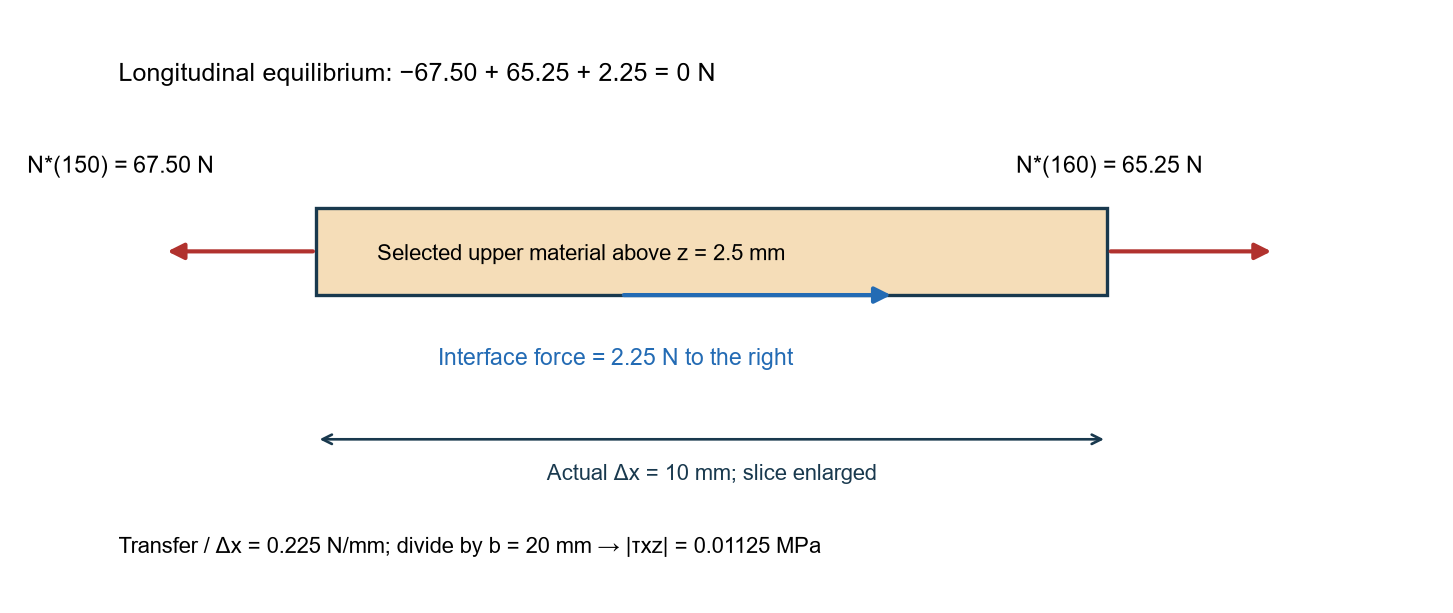

In [19]:
#@title Q determines the longitudinal-force difference that interface shear transfers
Qchosen=187.5;dx=10.;Mleft=-P*(L-150);Mright=-P*(L-160)
Nleft=-Mleft*Qchosen/I;Nright=-Mright*Qchosen/I
transfer=Nleft-Nright
fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
ax.add_patch(Rectangle((100,0),260,20,facecolor='#f5ddb8',edgecolor='#19394e',lw=2))
arrow(ax,(100,10),(50,10),'#b1322e');ax.text(5,28,f'N*(150) = {Nleft:.2f} N',fontsize=14)
arrow(ax,(360,10),(415,10),'#b1322e');ax.text(330,28,f'N*(160) = {Nright:.2f} N',fontsize=14)
arrow(ax,(200,0),(290,0),'#236bb4');ax.text(140,-16,f'Interface force = {transfer:.2f} N to the right',fontsize=14,color='#236bb4')
dimension(ax,(100,-33),(360,-33),'Actual Δx = 10 mm; slice enlarged',(0,-8))
ax.text(120,8,'Selected upper material above z = 2.5 mm',fontsize=13)
ax.text(35,49,'Longitudinal equilibrium: −67.50 + 65.25 + 2.25 = 0 N',fontsize=15)
ax.text(35,-59,'Transfer / Δx = 0.225 N/mm; divide by b = 20 mm → |τxz| = 0.01125 MPa',fontsize=13)
ax.set(xlim=(0,470),ylim=(-70,65));ax.axis('off')
plt.show()
assert np.isclose(transfer,2.25)

For the solid rectangle, substitute Q(z) and I = bh³/12:

$$|\tau_{zx}(z)|=\frac{3|V|}{2bh}
\left[1-\left(\frac{2z}{h}\right)^2\right].$$

At V = 2 N, the maximum is 0.015 MPa at z = 0, and the top/bottom surfaces have zero shear. At z = 2.5 mm, Q = 187.5 mm³ and shear is 0.01125 MPa. The normal-stress maximum and shear-stress maximum occur at different heights.

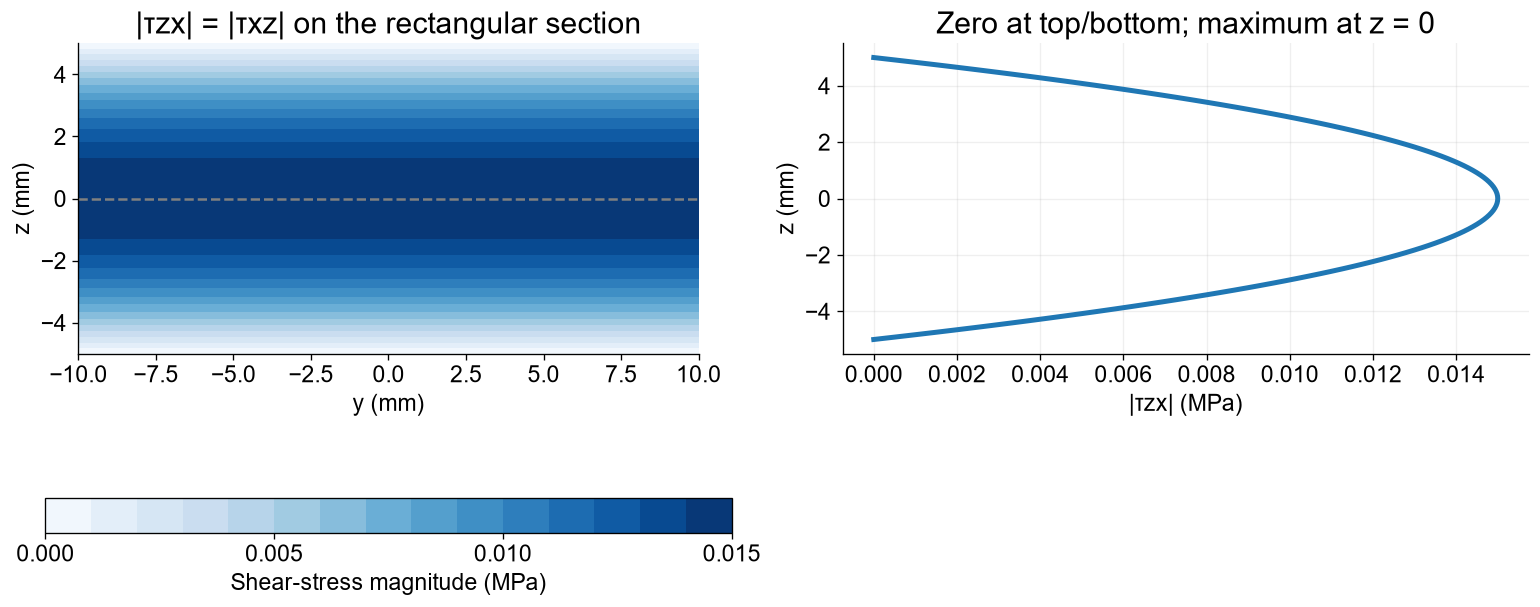

In [20]:
#@title Rectangular transverse shear magnitude — darkest at neutral axis
shear_field=1.5*abs(P)/A*(1-(2*zz/h)**2)
shear_peak=max(float(np.max(shear_field)),1e-12)
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
image=axes[0].contourf(yy,zz,shear_field,levels=np.linspace(0,shear_peak,16),cmap='Blues')
axes[0].axhline(0,color='gray',ls='--');axes[0].set(xlabel='y (mm)',ylabel='z (mm)',title='|τzx| = |τxz| on the rectangular section');axes[0].set_aspect('equal')
fig.colorbar(image,ax=axes[0],orientation='horizontal',pad=.22,label='Shear-stress magnitude (MPa)',ticks=np.linspace(0,shear_peak,4))
axes[1].plot(shear_field[:,0],zz[:,0],lw=3);axes[1].set(xlabel='|τzx| (MPa)',ylabel='z (mm)',title='Zero at top/bottom; maximum at z = 0');axes[1].grid(alpha=.2)
plt.show()
assert np.isclose(shear_field[0,0],0) and np.isclose(shear_field[60,0],1.5*abs(P)/A)

### One section, two different stress distributions

| z (mm) | σₓₓ (MPa) | Shear magnitude (MPa) |
|---:|---:|---:|
| +5 | +2.700 | 0 |
| +2.5 | +1.350 | 0.01125 |
| 0 | 0 | 0.01500 |
| −2.5 | −1.350 | 0.01125 |
| −5 | −2.700 | 0 |

The contour colours and profiles follow these values. Do not add maximum bending stress and maximum shear as if they occupied the same point. A real wing box uses thin-wall shear flow and its own geometry; the solid-rectangle formula is not obtained by substituting wing-skin thickness for b. Nominal beam stresses also exclude clamp-edge concentrations, holes and buckling.

## 5. Learn strain before the bending-strain equation

### 5.1. Normal strain, shear strain and the strain tensor

Strain measures **local change of shape or length**, not rigid translation. Normal strain is the relative change in a material line's length:

$$\varepsilon_{xx}=\frac{\Delta\ell_x}{\ell_x}.$$

Extension is positive; shortening is negative. Normal strains εₓₓ, εᵧᵧ and εzz refer to lines initially along x, y and z. Shear strain describes the change of the right angle between material lines. Engineering shear γxz is the total small change in that angle; the tensor component is half of it.

For displacement vector u = (uₓ,uᵧ,u_z), the small-strain tensor is:

$$\varepsilon_{ij}=\frac12\left(\frac{\partial u_i}{\partial x_j}
+\frac{\partial u_j}{\partial x_i}\right),$$

$$\boldsymbol{\varepsilon}=
\begin{bmatrix}
\varepsilon_{xx}&\gamma_{xy}/2&\gamma_{xz}/2\\
\gamma_{xy}/2&\varepsilon_{yy}&\gamma_{yz}/2\\
\gamma_{xz}/2&\gamma_{yz}/2&\varepsilon_{zz}
\end{bmatrix}.$$

The tensor is symmetric. Normal strains are fractional length changes; shear entries measure distortion. Strain is dimensionless (small angles are conventionally expressed in radians). Do not confuse stress τxz, measured in MPa, with shear strain γxz. A rigid translation or infinitesimal rigid rotation produces no small strain.

[MIT primary reading on the concept of strain](https://ocw.mit.edu/courses/2-080j-structural-mechanics-fall-2013/71034688fba0ff26d25653a4bd236a4a_MIT2_080JF13_Lecture2.pdf). The notebook uses the small-strain symmetric displacement gradient; finite rotations require a different strain measure.

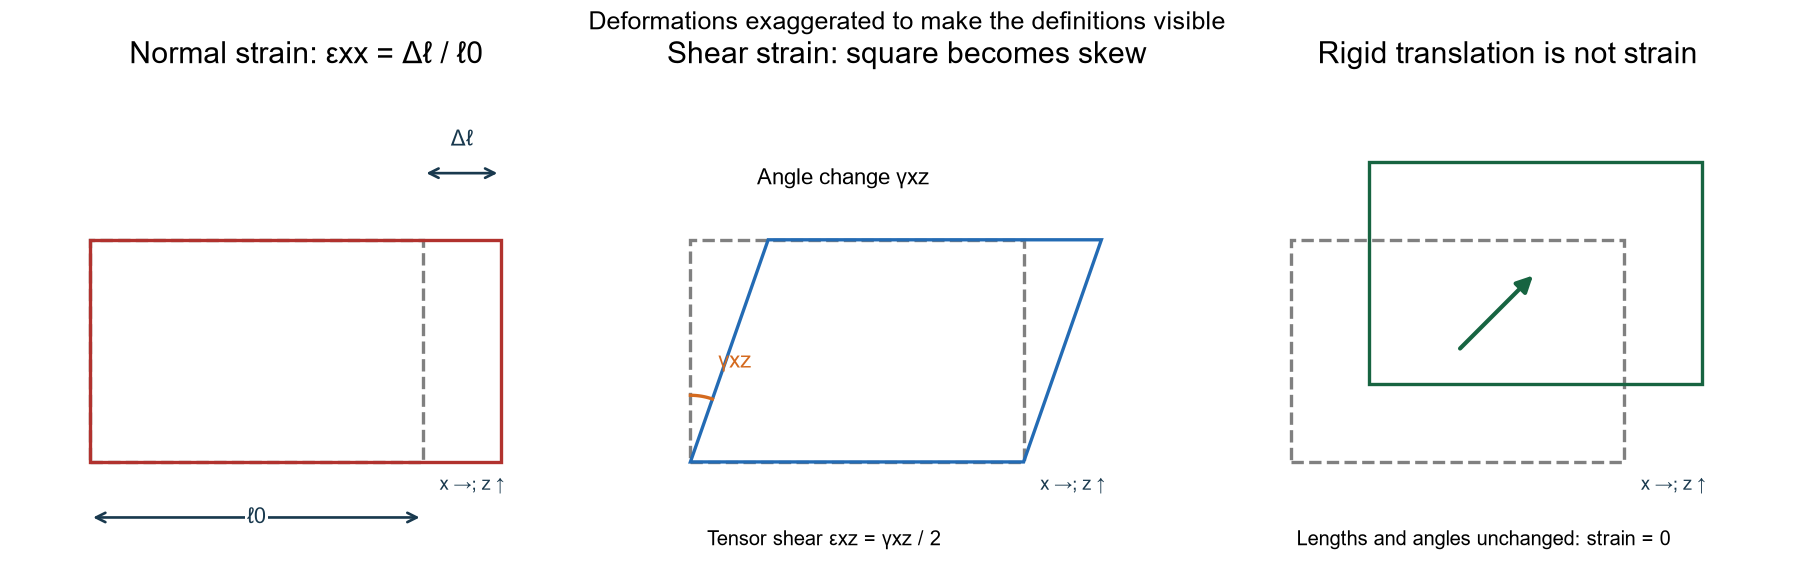

In [21]:
#@title Material-line changes — stretch, shear distortion and rigid translation
fig,axes=plt.subplots(1,3,figsize=(15,5),layout='constrained')
for ax in axes:
    ax.add_patch(Rectangle((0,0),3,2,fill=False,edgecolor='gray',ls='--',lw=2))
    ax.set(xlim=(-.7,4.6),ylim=(-1,3.5));ax.set_aspect('equal');ax.axis('off')
axes[0].add_patch(Rectangle((0,0),3.7,2,fill=False,edgecolor='#b1322e',lw=2))
dimension(axes[0],(0,-.5),(3,-.5),'ℓ0')
dimension(axes[0],(3,2.6),(3.7,2.6),'Δℓ',(0,.3))
axes[0].set_title('Normal strain: εxx = Δℓ / ℓ0')
axes[1].add_patch(Polygon([[0,0],[3,0],[3.7,2],[.7,2]],fill=False,edgecolor='#236bb4',lw=2))
angles=np.linspace(np.arctan2(2,.7),np.pi/2,50)
axes[1].plot(.6*np.cos(angles),.6*np.sin(angles),color='#d46a1f',lw=2)
axes[1].text(.25,.85,'γxz',fontsize=13,color='#d46a1f')
axes[1].text(.6,2.5,'Angle change γxz',fontsize=13)
axes[1].text(.15,-.75,'Tensor shear εxz = γxz / 2',fontsize=12)
axes[1].set_title('Shear strain: square becomes skew')
axes[2].add_patch(Rectangle((.7,.7),3,2,fill=False,edgecolor='#176441',lw=2))
arrow(axes[2],(1.5,1),(2.2,1.7),'#176441')
axes[2].text(.05,-.75,'Lengths and angles unchanged: strain = 0',fontsize=12)
axes[2].set_title('Rigid translation is not strain')
fig.suptitle('Deformations exaggerated to make the definitions visible',fontsize=15)
for ax in axes:
    ax.text(3.15,-.25,'x →; z ↑',fontsize=11,color='#19394e')
plt.show()

### 5.2. Apply the strain definition to bending fibres

### Start with the definition of strain

Longitudinal strain εₓ is the change in a material fibre's length divided by its original length. It is dimensionless. A strain of 0.00135 means a 0.135% change in length, not a 0.00135 mm displacement:

$$\varepsilon_x=\frac{\ell-\ell_0}{\ell_0}=\frac{\Delta\ell}{\ell_0}.$$

In the elementary bending model, cross-sections remain plane and perpendicular to the neutral fibre. Adjacent sections rotate relative to each other. With no net axial extension, the neutral fibre keeps its length; fibres farther from it lengthen or shorten more.

### Read the arc geometry in the next figure

The neutral fibre follows a small arc of radius R and angle Δφ. Its length is RΔφ. For the downward-curving case drawn, the top fibre at positive z is farther from the centre of curvature and has length (R + z)Δφ. Subtracting the neutral-fibre length gives:

$$\varepsilon_x=\frac{(R+z)\Delta\phi-R\Delta\phi}{R\Delta\phi}
=\frac{z}{R}=z\kappa.$$

Here R is a curvature radius, **not a support reaction**. The bottom fibre has negative z and therefore negative strain. This sign statement is tied to our drawn positive, downward curvature; reversing the load reverses the curvature and the tension/compression sides.

### Connect the geometry to the beam's displacement

With v positive downward, the exact signed curvature of the centreline graph is:

$$\kappa=\frac{v''}{[1+(v')^2]^{3/2}}\approx v''\qquad\text{for small slopes}.$$

Linear elastic material obeys Hooke's law σₓ = E εₓ. The signed sagging-positive moment is the moment of the longitudinal stress distribution:

$$M=-\int_A z\sigma_x\,dA=-E\kappa\int_A z^2\,dA=-EI\kappa.$$

The minus sign belongs to the chosen sagging-positive M and downward-positive v conventions. This chain gives both relations rather than introducing them as unrelated formulas:

$$\boxed{\varepsilon_x=zv''},\qquad
\boxed{\sigma_x=E\varepsilon_x=-\frac{Mz}{I}},\qquad
\boxed{v''=-\frac{M}{EI}}.$$

At the root of Example A, κ = 900/3,333,333.33 = 0.000270 mm⁻¹. At z = +5 mm, εₓ = 0.001350 and σₓ = 2000 × 0.001350 = 2.700 MPa. That is the top point of Figure 4. The curvature relation is an approximation to beam geometry, not a new applied load.

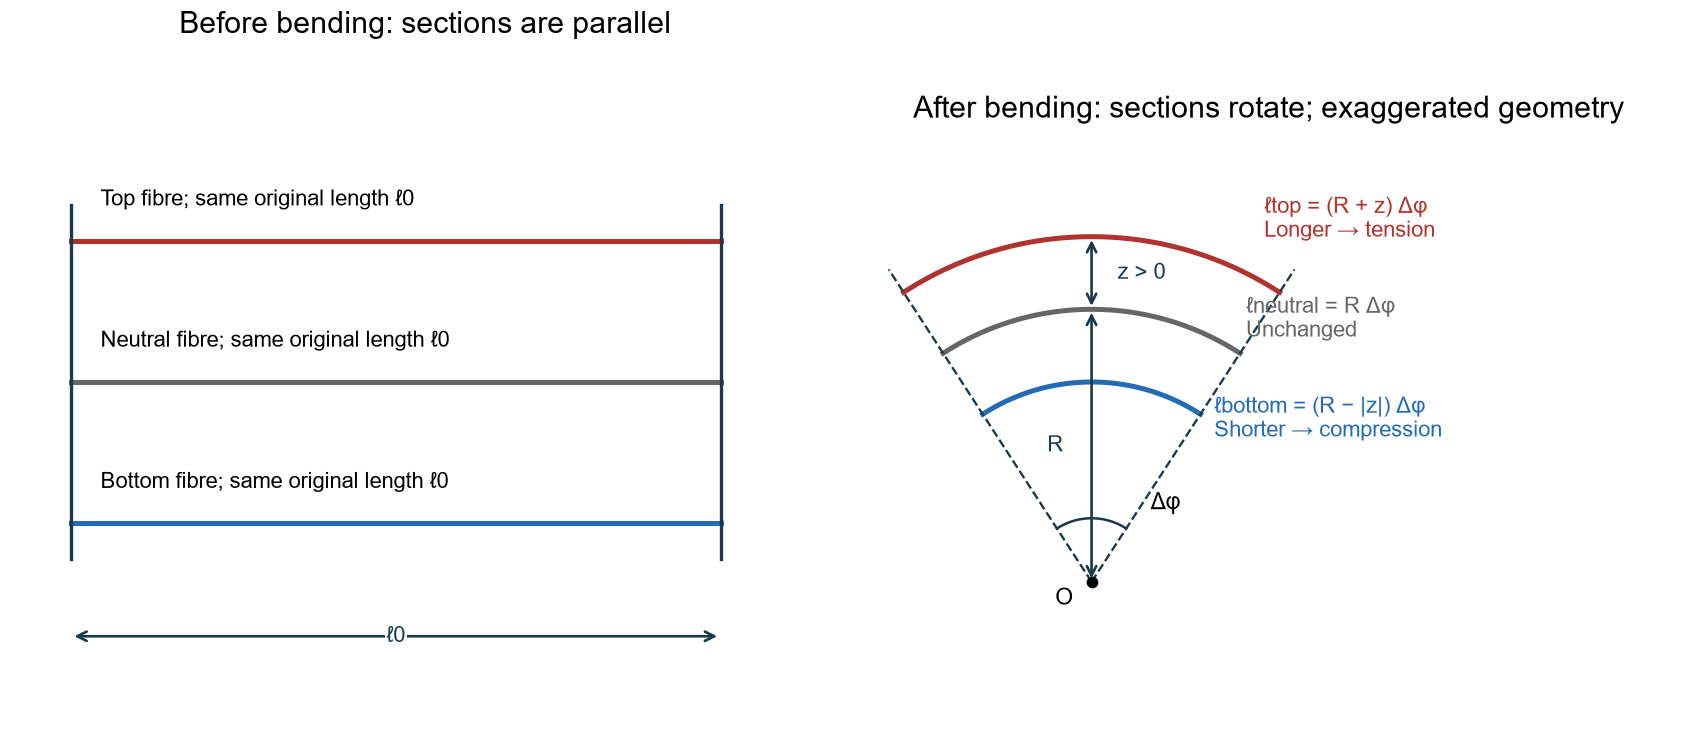

In [22]:
#@title Figure 5A — equal original fibres become different-length arcs
fig,axes=plt.subplots(1,2,figsize=(14,6),layout='constrained')
ax=axes[0]
for zz,col,name in [(20,'#b1322e','Top fibre'),(0,'#666666','Neutral fibre'),(-20,'#236bb4','Bottom fibre')]:
    ax.plot([0,110],[zz,zz],color=col,lw=3)
    ax.text(5,zz+5,name+'; same original length ℓ0',fontsize=13)
for xx in [0,110]: ax.plot([xx,xx],[-25,25],color='#19394e',lw=2)
dimension(ax,(0,-36),(110,-36),'ℓ0')
ax.set(xlim=(-10,130),ylim=(-48,48),title='Before bending: sections are parallel')
ax.axis('off')
ax=axes[1]
Rdemo=60.; zdemo=16.
ang=np.linspace(np.deg2rad(57),np.deg2rad(123),100)
for rad,col,label in [(Rdemo+zdemo,'#b1322e','Top: (R + z) Δφ'),(Rdemo,'#666666','Neutral: R Δφ'),(Rdemo-zdemo,'#236bb4','Bottom: (R − |z|) Δφ')]:
    ax.plot(rad*np.cos(ang),rad*np.sin(ang),color=col,lw=3)
for a in [ang[0],ang[-1]]:
    ax.plot([0,82*np.cos(a)],[0,82*np.sin(a)],color='#19394e',lw=1.4,ls='--')
ax.plot(0,0,'ko'); ax.text(-8,-5,'O',fontsize=14)
dimension(ax,(0,0),(0,Rdemo),'R',(-8,0))
dimension(ax,(0,Rdemo),(0,Rdemo+zdemo),'z > 0',(11,0))
ax.plot(14*np.cos(ang),14*np.sin(ang),color='#19394e')
ax.text(13,16,'Δφ',fontsize=14)
ax.text(38,76,'ℓtop = (R + z) Δφ\nLonger → tension',fontsize=13,color='#b1322e')
ax.text(34,54,'ℓneutral = R Δφ\nUnchanged',fontsize=13,color='#666666')
ax.text(27,32,'ℓbottom = (R − |z|) Δφ\nShorter → compression',fontsize=13,color='#236bb4')
ax.set(xlim=(-52,130),ylim=(-12,100),title='After bending: sections rotate; exaggerated geometry')
ax.set_aspect('equal'); ax.axis('off')
plt.show()

For our beam coordinates, vertical material displacement u_z = −v because z points upward and v is defined downward. Plane sections remaining perpendicular to the neutral fibre give u_x = z v′. Therefore εₓₓ = ∂u_x/∂x = z v″. This fixes the sign of the bending strain. The **Euler–Bernoulli model neglects shear deformation**, although transverse shear stress still exists.

$$\gamma_{xz}=\frac{\partial u_x}{\partial z}+
\frac{\partial u_z}{\partial x}=v'-v'=0.$$

This zero is a kinematic approximation, not a claim that V or shear stress vanishes. Short/deep beams may need a shear-deformable model.

In this reduced theory, transverse shear stress is recovered from equilibrium while shear deformation is neglected. It is not an exact three-dimensional strain field. The relation σₓₓ = E εₓₓ is the beam's dominant uniaxial longitudinal response, not the general constitutive equation for a state with all nine stress components.

### Integrate curvature using the physical root constraints

For Example A, equilibrium gave M(x)=-P(L-x). With downward-positive v and sagging-positive M,

$$-v''=\frac{M}{EI},\qquad v''=-\frac{M}{EI}=\frac{P(L-x)}{EI}.$$

Here E and I are constant along the beam. Use s as the running coordinate in the first integral. The upper bound x is the station where we want the answer:

$$\begin{aligned}
\theta(x)-\theta(0)
&=\int_0^x v''(s)\,ds
=\frac{P}{EI}\int_0^x(L-s)\,ds\\
&=\frac{P}{EI}\left[Ls-\frac{s^2}{2}\right]_0^x
=\frac{P}{EI}\left(Lx-\frac{x^2}{2}\right).
\end{aligned}$$

The clamp requires θ(0)=0, so there is no unknown starting rotation. Now integrate the resulting slope, again from the physical root:

$$\begin{aligned}
v(x)-v(0)
&=\int_0^x\theta(s)\,ds
=\frac{P}{EI}\int_0^x\left(Ls-\frac{s^2}{2}\right)ds\\
&=\frac{P}{EI}\left[\frac{Ls^2}{2}-\frac{s^3}{6}\right]_0^x
=\frac{P}{EI}\left(\frac{Lx^2}{2}-\frac{x^3}{6}\right).
\end{aligned}$$

The clamp also requires v(0)=0. In an indefinite-integral approach these same conditions set C₁=0 and C₂=0. Factoring gives

$$\boxed{\theta(x)=\frac{Px(2L-x)}{2EI}},\qquad
\boxed{v(x)=\frac{Px^2(3L-x)}{6EI}}.$$

At x=150 mm, EI=(2000)(1666.6667)=3333333.3333 N mm²:

$$\theta(150)=\frac{2}{EI}\left[450(150)-\frac{150^2}{2}\right]
=\frac{112500}{3333333.3333}=0.033750\ \mathrm{rad},$$
$$v(150)=\frac{2}{EI}\left[\frac{450(150)^2}{2}-\frac{150^3}{6}\right]
=\frac{9000000}{3333333.3333}=2.700\ \mathrm{mm}.$$

At the tip, substitute x=L **before** simplifying:

$$\theta(L)=\frac{P}{EI}\left(L^2-\frac{L^2}{2}\right)=\frac{PL^2}{2EI}=0.060750\ \mathrm{rad},$$
$$v(L)=\frac{P}{EI}\left(\frac{L^3}{2}-\frac{L^3}{6}\right)
=\frac{PL^3}{3EI}=18.225\ \mathrm{mm}.$$

Curvature has units 1/mm; one integration gives a dimensionless slope (reported in radians), and the second gives millimetres. The zero-curvature free tip can have nonzero accumulated slope and displacement. For variable stiffness, use -M(s)/(E(s)I(s)) inside the first integral rather than pulling a constant EI outside.

The fixed root gives v(0) = 0 and θ(0) = 0; equivalently C₁ = 0 and C₂ = 0.

| Station | Curvature κ | Rotation θ | Displacement v |
|---|---:|---:|---:|
| Root x = 0 | 0.000270 mm⁻¹ | 0 rad | 0 mm |
| Cut x = 150 mm | 0.000180 mm⁻¹ | 0.033750 rad | 2.700 mm |
| Tip x = 450 mm | 0 mm⁻¹ | 0.060750 rad | 18.225 mm |

The root can have nonzero curvature and strain despite zero displacement and slope. At the tip, zero moment/curvature does not imply zero accumulated rotation or displacement. Integration carries the bending effect of the whole inboard span into the tip motion. The tip slope is about 3.48°, and deflection is about 4.05% of span; check the small-deflection approximation for a real test. This solid strip is not the actual airfoil-section wing.

Tip deflection = 18.2250 mm; root deflection = 0.0000 mm
Tip slope = 0.06075 rad


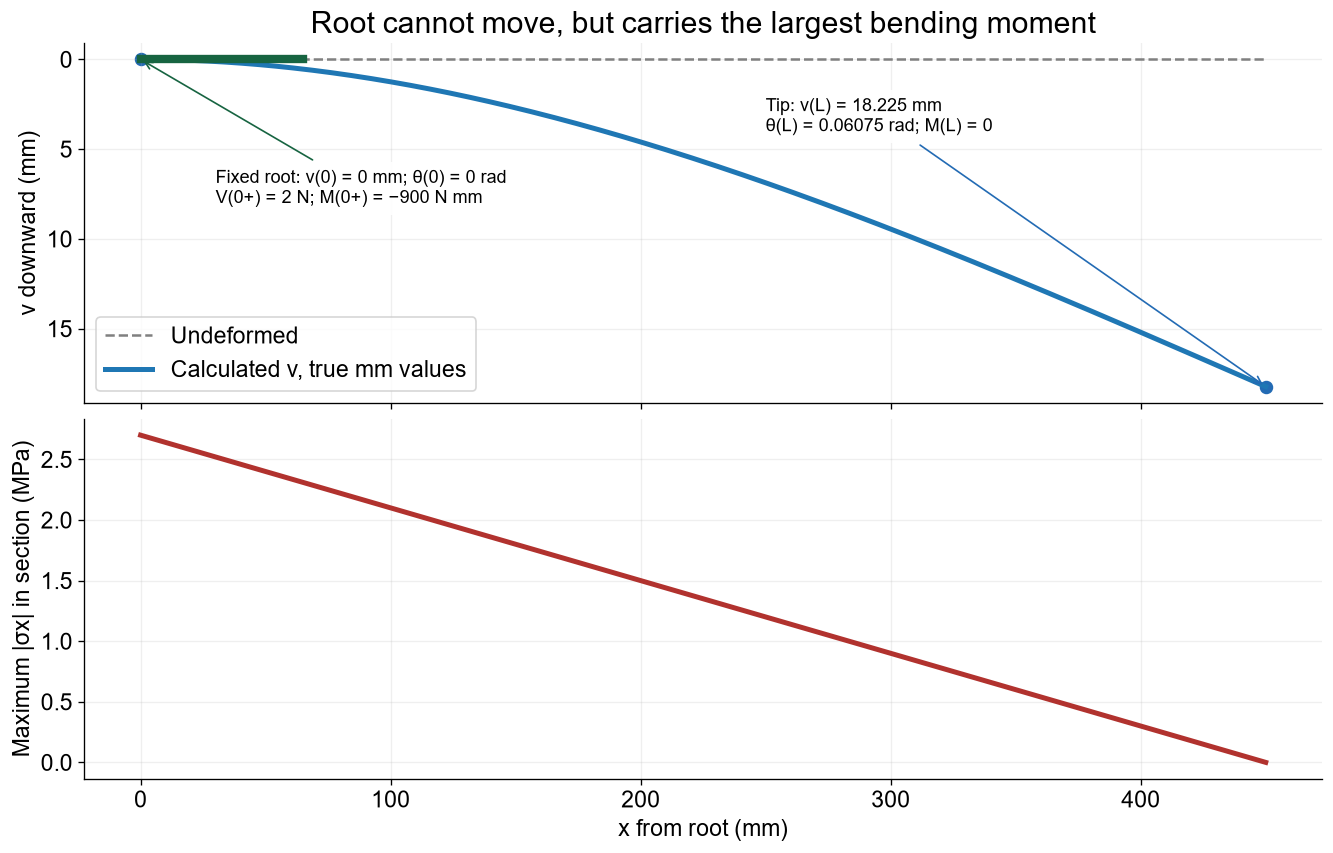

In [23]:
#@title Figure 5B — undeformed and deflected shape; stress is not displacement
v=P*x**2*(3*L-x)/(6*EI)
fig,axes=plt.subplots(2,1,figsize=(11,7),layout='constrained',sharex=True)
axes[0].plot(x,np.zeros_like(x),'--',color='gray',label='Undeformed')
axes[0].plot(x,v,lw=3,label='Calculated v, true mm values')
axes[0].scatter([0,L],[0,v[-1]],color='#236bb4',s=50)
axes[0].plot([0,65],[0,0],color='#176441',lw=5)
axes[0].annotate('Fixed root: v(0) = 0 mm; θ(0) = 0 rad\nV(0+) = 2 N; M(0+) = −900 N mm',
                 xy=(0,0),xytext=(30,8),fontsize=11,
                 bbox=dict(facecolor='white',edgecolor='none',alpha=.9),
                 arrowprops=dict(arrowstyle='->',color='#176441'))
axes[0].annotate('Tip: v(L) = 18.225 mm\nθ(L) = 0.06075 rad; M(L) = 0',
                 xy=(L,v[-1]),xytext=(250,4),fontsize=11,
                 bbox=dict(facecolor='white',edgecolor='none',alpha=.9),
                 arrowprops=dict(arrowstyle='->',color='#236bb4'))
axes[0].invert_yaxis(); axes[0].set_ylabel('v downward (mm)'); axes[0].legend()
axes[0].set_title('Root cannot move, but carries the largest bending moment')
axes[1].plot(x,np.abs(M)*h/2/I,lw=3,color='#b1322e')
axes[1].set(xlabel='x from root (mm)',ylabel='Maximum |σx| in section (MPa)')
for ax in axes: ax.grid(alpha=.2)
plt.show()
print(f'Tip deflection = {v[-1]:.4f} mm; root deflection = {v[0]:.4f} mm')
print(f'Tip slope = {P*L**2/(2*EI):.5f} rad')

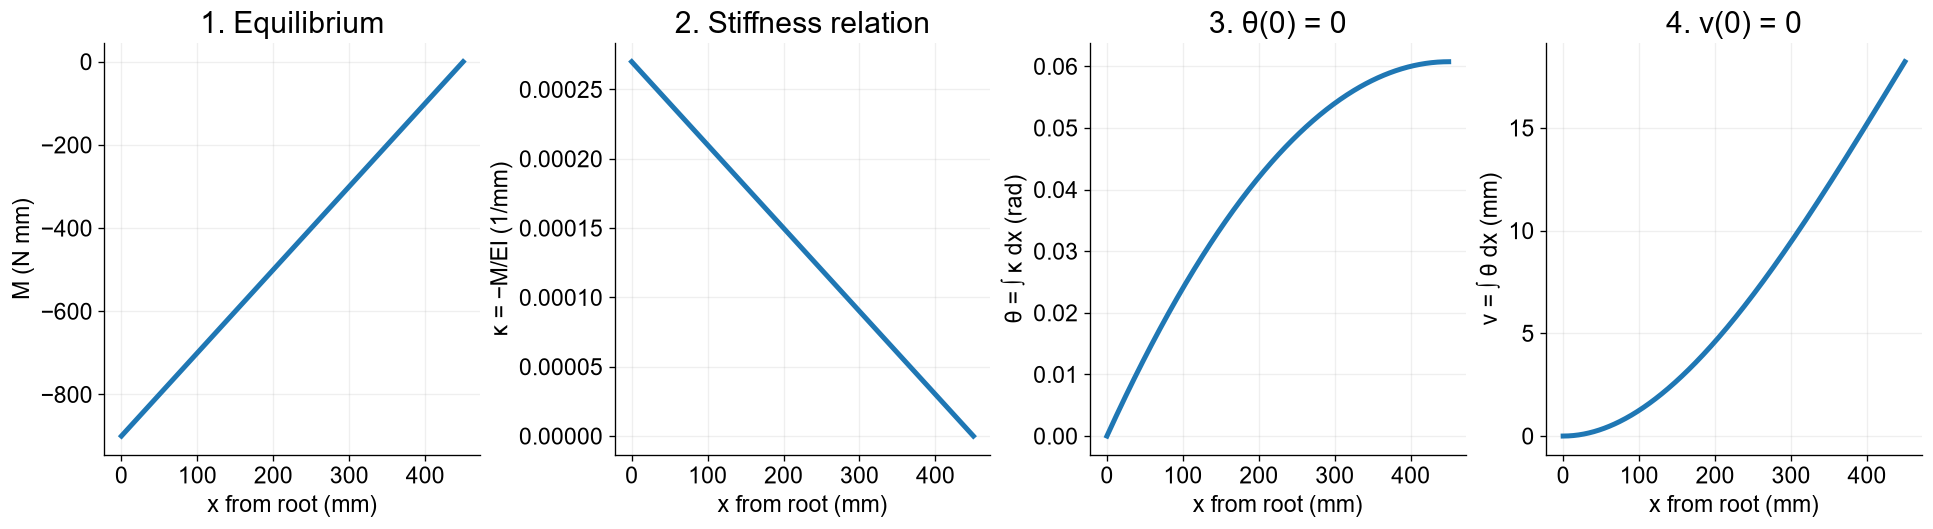

In [24]:
#@title Figure 5C — four stages of the calculation, with units
fig,axes=plt.subplots(1,4,figsize=(16,4.3),layout='constrained')
curvature=P*(L-x)/EI
theta=P*x*(2*L-x)/(2*EI)
for ax,yy,label in zip(axes,[M,curvature,theta,v],
 ['M (N mm)','κ = −M/EI (1/mm)','θ = ∫ κ dx (rad)','v = ∫ θ dx (mm)']):
    ax.plot(x,yy,lw=3)
    ax.set(xlabel='x from root (mm)',ylabel=label)
    ax.grid(alpha=.2)
axes[0].set_title('1. Equilibrium')
axes[1].set_title('2. Stiffness relation')
axes[2].set_title('3. θ(0) = 0')
axes[3].set_title('4. v(0) = 0')
plt.show()
assert abs(curvature[0]-.00027)<1e-12
assert abs(theta[-1]-.06075)<1e-12

### 5.3. Return to the support examples after learning displacement

All centre-force comparisons below use the same length, section, modulus and 2 N force. The maximum cantilever displacement is at its free tip, **not at the load station**.

| Case | Largest nominal bending stress | Maximum downward displacement |
|---|---:|---:|
| Cantilever, centre force | 1.350 MPa at root | 5.695313 mm at free tip; load station: 2.278125 mm |
| Pin–roller, centre force | 0.675 MPa at centre | 1.139063 mm at centre |
| Fixed–fixed, centre force | 0.3375 MPa at ends and centre | 0.284766 mm at centre |
| Cantilever tip extension (Example A) | 2.700 MPa at root | 18.225 mm at tip |
| Cantilever uniform extension (Example B) | 1.350 MPa at root | 6.834375 mm at tip |

For the simply supported centre force, integrating curvature with zero end displacement gives PL³/(48EI). For fixed–fixed it gives PL³/(192EI). The reactions were derived in their own support subsections, not inferred from these displacement formulas.

For Example B, M(x) = −q(L − x)²/2. Two integrations with v(0) = θ(0) = 0 give:

$$v(x)=\frac{qx^2}{24EI}(6L^2-4Lx+x^2),\qquad
v(L)=\frac{qL^4}{8EI}=6.834375\ \mathrm{mm}.$$

Its root moment matches the centre point-load cantilever, but displacement does not: whole-beam equivalent loads need not have the same internal strain field.

#### Example B: carry out both integrations for the uniform load

The downward load density is q=P/L=2/450 N/mm. The cut moment is M(x)=-q(L-x)²/2, so

$$v''(x)=-\frac{M(x)}{EI}=\frac{q}{2EI}(L-x)^2
=\frac{q}{2EI}(L^2-2Lx+x^2).$$

For constant EI, integrate from the clamp and apply θ(0)=0:

$$\begin{aligned}
\theta(x)&=\frac{q}{2EI}\int_0^x(L^2-2Ls+s^2)\,ds\\
&=\frac{q}{2EI}\left[L^2s-Ls^2+\frac{s^3}{3}\right]_0^x\\
&=\frac{q}{2EI}\left(L^2x-Lx^2+\frac{x^3}{3}\right).
\end{aligned}$$

Integrate once more and apply v(0)=0:

$$\begin{aligned}
v(x)&=\frac{q}{2EI}\int_0^x\left(L^2s-Ls^2+\frac{s^3}{3}\right)ds\\
&=\frac{q}{2EI}\left[\frac{L^2s^2}{2}-\frac{Ls^3}{3}+\frac{s^4}{12}\right]_0^x\\
&=\frac{qx^2}{24EI}(6L^2-4Lx+x^2).
\end{aligned}$$

At the tip the powers of L combine, but the fractions must still be added:

$$\theta(L)=\frac{qL^3}{2EI}\left(1-1+\frac13\right)
=\frac{qL^3}{6EI}=0.020250\ \mathrm{rad},$$
$$v(L)=\frac{qL^4}{2EI}\left(\frac12-\frac13+\frac1{12}\right)
=\frac{qL^4}{2EI}\left(\frac14\right)
=\frac{qL^4}{8EI}=6.834375\ \mathrm{mm}.$$

At x=150 mm the intermediate checks are v''=0.000060 mm⁻¹, θ=0.014250 rad, and v=1.209375 mm. The same total 2 N load spread over the span does not generate the same M(x), curvature, or displacement as a 2 N tip force. Both examples satisfy the same two root constraints, but integrate different curvature fields.

Uniform: root |M|=450.000 N mm; stress=1.350 MPa; tip v=6.834375 mm


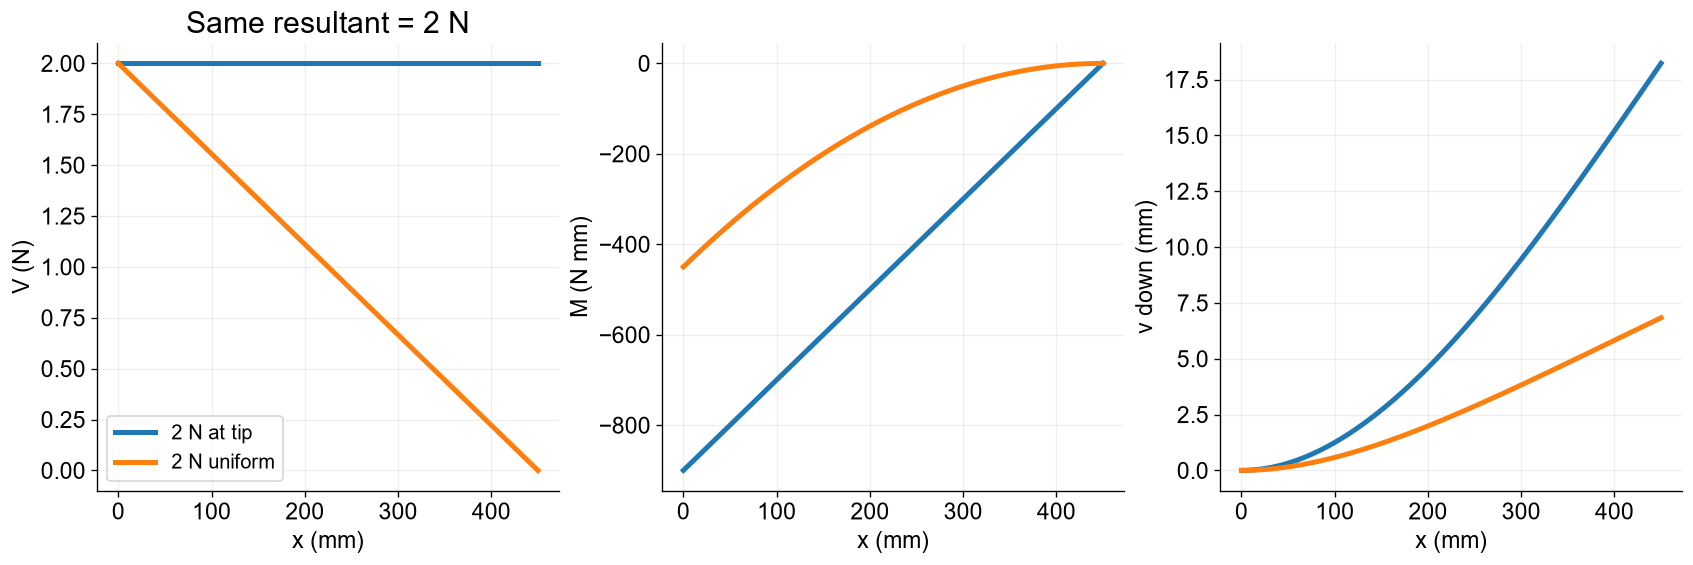

In [25]:
#@title Figure 6B — equal total load, different internal diagrams and displacement
q=P/L
Vu=q*(L-x); Mu=-q*(L-x)**2/2
vu=q*x**2*(6*L**2-4*L*x+x*x)/(24*EI)
fig,axes=plt.subplots(1,3,figsize=(14,4.6),layout='constrained')
for ax,y1,y2,label in zip(axes,[V,M,v],[Vu,Mu,vu],['V (N)','M (N mm)','v down (mm)']):
    ax.plot(x,y1,lw=3,label='2 N at tip'); ax.plot(x,y2,lw=3,label='2 N uniform')
    ax.set(xlabel='x (mm)',ylabel=label); ax.grid(alpha=.2)
axes[0].legend(fontsize=12); axes[0].set_title('Same resultant = 2 N')
plt.show()
print(f'Uniform: root |M|={q*L**2/2:.3f} N mm; stress={q*L**2*h/(4*I):.3f} MPa; tip v={vu[-1]:.6f} mm')

Pin–roller: max |M|=225.0000 N mm; max |σ|=0.675000 MPa; max v=1.139063 mm
Fixed–fixed: max |M|=112.5000 N mm; max |σ|=0.337500 MPa; max v=0.284766 mm


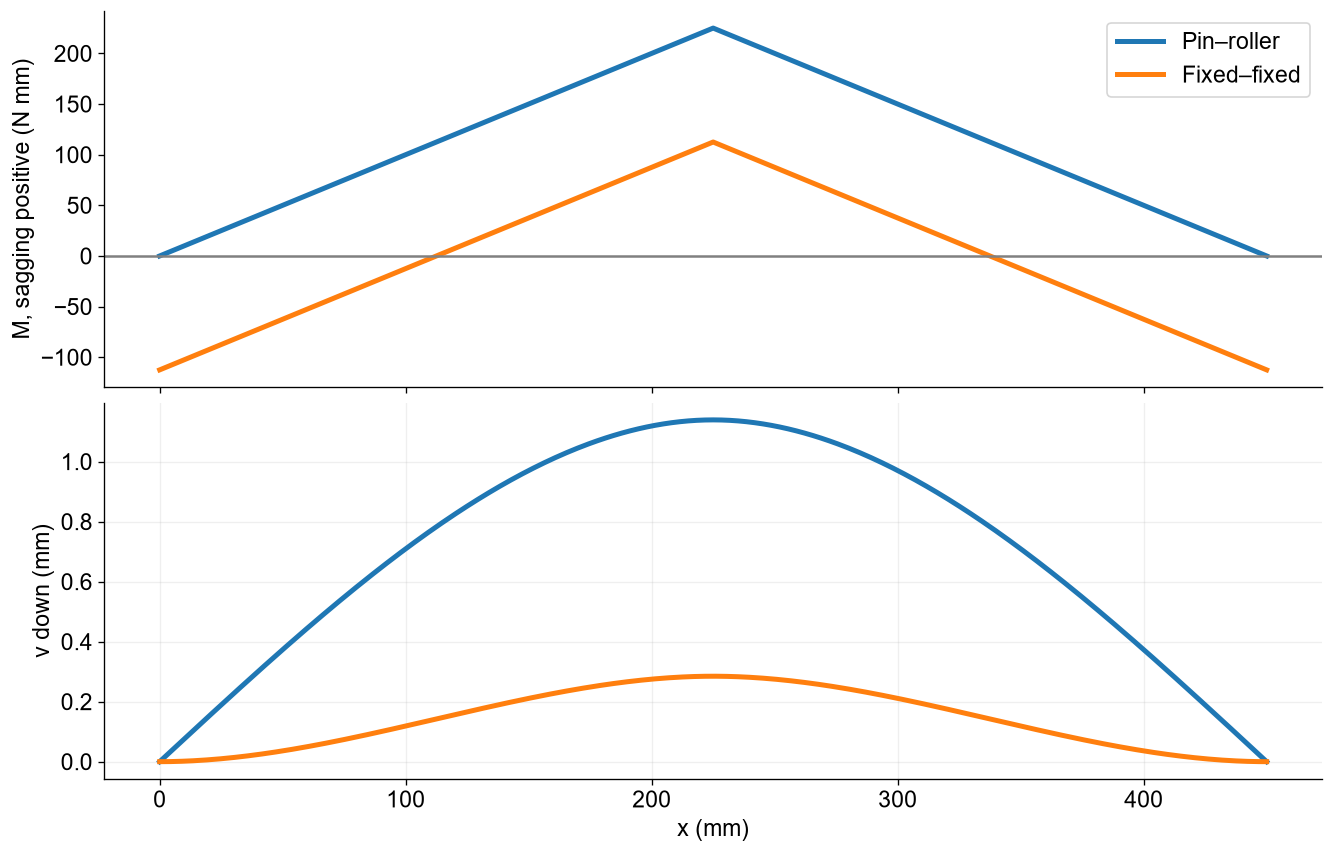

In [26]:
#@title Figure 7B — simply supported versus fixed–fixed, same centre force
Ms=np.where(x<=L/2,P*x/2,P*(L-x)/2)
Mf=Ms-P*L/8
xx=np.minimum(x,L-x)
vs=P*xx*(3*L**2-4*xx**2)/(48*EI)
vf=P*xx**2*(3*L-4*xx)/(48*EI)
fig,axes=plt.subplots(2,1,figsize=(11,7),layout='constrained',sharex=True)
axes[0].plot(x,Ms,lw=3,label='Pin–roller'); axes[0].plot(x,Mf,lw=3,label='Fixed–fixed')
axes[0].axhline(0,color='gray'); axes[0].set_ylabel('M, sagging positive (N mm)'); axes[0].legend()
axes[1].plot(x,vs,lw=3,label='Pin–roller'); axes[1].plot(x,vf,lw=3,label='Fixed–fixed')
axes[1].set(xlabel='x (mm)',ylabel='v down (mm)'); axes[1].grid(alpha=.2)
plt.show()
for name,mm,vv in [('Pin–roller',Ms,vs),('Fixed–fixed',Mf,vf)]:
    print(f'{name}: max |M|={max(abs(mm)):.4f} N mm; max |σ|={max(abs(mm))*h/(2*I):.6f} MPa; max v={max(vv):.6f} mm')

### Current Beam Lab workflow and load previews

1. Start in **Beam**. The normal opening has no applied load. An explicitly selected example link loads its stated example; do not mistake it for the empty opening.
2. Enter L and E; select **Cross-section → Solid rectangle** and enter b and h. Check A and I. Pick the left/right supports separately and remove unwanted interior supports or hinges. Keep self-weight off when it is neglected in the problem.
3. Under **Loads**, select a point force, bending couple, uniform, triangular, trapezoidal, elliptic or parabolic line load. Select a graphical tool and click a station, or drag an interval, then confirm its signed magnitude. Numeric fields provide precise coordinates. Selecting a tool or previewing a curve does not apply it.
4. **F is total force in N; q is intensity in N/mm.** The signed area under q is F. For example, 2 N distributed uniformly over 450 mm means q = 0.00444444 N/mm, not 2 N/mm. The live profile shows the interval, shape, total, peak intensity and resultant station. Curved laws accept total F or peak intensity; the other is derived.
5. **Shared intensity scale** compares line-load magnitudes, so a small load may look almost flat. **Independent heights** makes each shape visible but cannot compare magnitudes. This changes the drawing, not the applied forces or solution. Point-force arrows are schematic, not intensity measurements.
6. CSV tables are linear between supplied stations. The optional power-law generator makes an explicitly approximate 31-point table with a selectable exponent, interval and maximum location, normalized to the requested total. Preview and validate before applying. HW 3 needs only the stated triangular/trapezoidal loads.
7. Press **Solve**. Pending results belong to the last solved model. Use **Support reactions and motion**, **Diagrams**, **Cut & section** and the station table to distinguish reactions from internal V and M. A moving cut is not another support.
8. **Report & export** offers station, plot-sample and reaction CSV files, PNG for each plot, a printable/PDF report, and JSON study save/re-import or a share link. A/B comparison uses saved independent studies. These tools support checking; extra exports are not required for HW 3.

Beam Lab solves transverse Euler–Bernoulli bending, not axial/frame response or wing torsion. Printed-wing and D.520 workspaces additionally use chord position to calculate bending and twist. Their geometry and material models are not substitutes for this lecture's solid rectangular beam.

### What are 10, 30 or 40 elements?

An element is a numerical segment, not a separate physical beam piece. Every node has displacement v and rotation θ. The solver assembles stiffness and consistent loads, solves nodal values and interpolates displacement between nodes. With L = 450 mm, nominal element lengths L/N are 45 mm (N = 10), 15 mm (N = 30) and 11.25 mm (N = 40).

Support, point-load, line-load boundary and hinge stations become nodes even if they miss a regular grid point. Thus the requested count is not always the actual count. Mesh lines are not ribs, joints, cracks or new supports.

More elements generally improve between-node interpolation and mode estimates at greater computational cost. They do not change E or I and do not make the physical beam stronger. For the constant-EI examples, exact consistent loading can already produce highly accurate nodal motion and equilibrium-recovered V/M, so some numbers may barely change as N changes. This is not a guarantee for arbitrary models or between-node motion.

To study mesh sensitivity, keep every physical input fixed and compare the same quantity at the same x for 10, 30 and 40 elements. Check absolute differences as well as relative differences; relative error near a zero result is misleading. Do not compare different mesh-node locations as if they were the same station. Modal convergence and static convergence need not be the same. Numerical convergence does not validate the material, clamp or small-deflection assumptions.

**HW 3 instruction: use 30 requested elements for all three cases. No convergence table or extra mesh runs are required.** Other problems have no universally guaranteed element count.

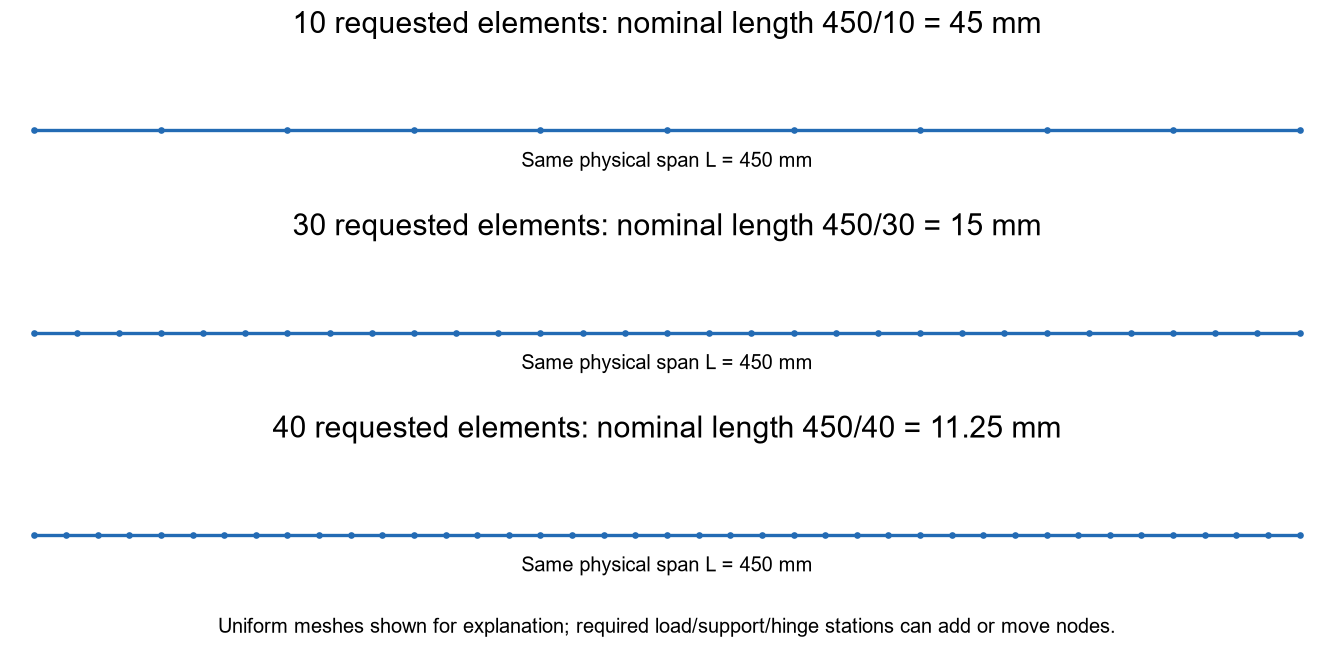

In [27]:
#@title Figure 7M — same physical beam with three numerical meshes
fig, axes = plt.subplots(3,1,figsize=(11,5.3),layout='constrained')
for ax,n in zip(axes,[10,30,40]):
    xx=np.linspace(0,450,n+1)
    ax.plot(xx,np.zeros_like(xx),'-o',color='#236bb4',lw=2,ms=3)
    ax.set(xlim=(-8,458),ylim=(-.5,.6),title=f'{n} requested elements: nominal length 450/{n} = {450/n:g} mm')
    ax.text(225,-.25,'Same physical span L = 450 mm',ha='center',fontsize=12)
    ax.axis('off')
fig.supxlabel('Uniform meshes shown for explanation; required load/support/hinge stations can add or move nodes.',fontsize=12)
plt.show()

### What the app actually solves

The app divides the beam into finite elements. Each node has a displacement and rotation. Element stiffness and consistent loads assemble into:

$$\mathbf K\mathbf u=\mathbf f.$$

Boundary conditions restrict selected components of  u. After solving the free components, the original equations recover reactions. The app reconstructs shear and moment from equilibrium and evaluates stress. Refining the mesh checks numerical sensitivity; it does not verify a real clamp, printed anisotropy or material strength. You do not need to derive element matrices today.

**Software activity A:** open the tip-load link. Find −2 N, −900 N mm, 2.70 MPa and 18.225 mm. In **Cut & section**, set the cut at x = 150 mm and check M = −600 N mm on the free body of the left part. Explain any sign differences before declaring an error. Save the study record (**Report & export → Save study (.json)**).

**Interpret each output separately:** reactions check whole-beam equilibrium; V and M describe each cut; stresses describe fibres within a selected section; v describes motion along the span. A colour map of stress is not a photograph of damage. A deflection animation is usually magnified; compare the numerical mm values.

Every example link below replaces the previous study with its prescribed load and support. First compare units and sign conventions, then numerical values. Return to the notebook and record one equilibrium check and one stress/deflection calculation. Mesh convergence checks discretization, not the material model.

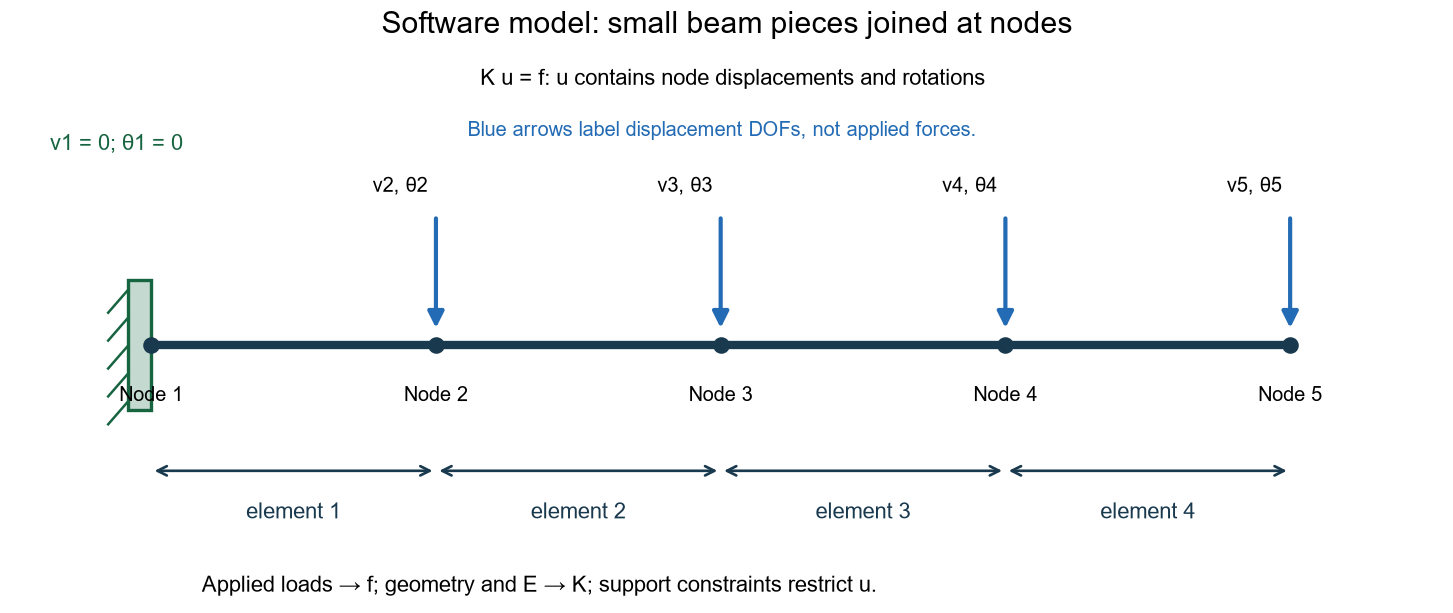

In [28]:
#@title Figure 5D — finite-element nodes carry displacement and rotation
fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
clean_beam(ax,'Software model: small beam pieces joined at nodes')
support(ax,0,'fixed')
nodes=np.linspace(0,L,5)
ax.scatter(nodes,np.zeros_like(nodes),s=80,color='#19394e',zorder=5)
for j,xx in enumerate(nodes):
    ax.text(xx,-12,f'Node {j+1}',ha='center',fontsize=12)
    if j:
        arrow(ax,(xx,28),(xx,3),'#236bb4')
        ax.text(xx-25,33,f'v{j+1}, θ{j+1}',fontsize=12)
    if j<4:
        dimension(ax,(xx,-27),(nodes[j+1],-27),f'element {j+1}',(0,-9))
ax.text(-40,42,'v1 = 0; θ1 = 0',color='#176441',fontsize=13)
ax.text(130,56,'K u = f: u contains node displacements and rotations',fontsize=13)
ax.text(20,-53,'Applied loads → f; geometry and E → K; support constraints restrict u.',fontsize=13)
ax.text(125,45,'Blue arrows label displacement DOFs, not applied forces.',fontsize=12,color='#236bb4')
plt.show()

## 6. Return to the aircraft wing

For an upward-loaded wing, top material is commonly in spanwise compression and bottom material in tension under positive lift bending. The root transfers shear and a bending couple to the fuselage. In a deep spar, the caps carry much of the bending tension/compression and the web carries shear. Skins and stringers also participate; ribs preserve section shape and transfer local loads. Adding a rib does not erase the externally applied lift.

$$I_{\mathrm{rectangle}}\propto h^3,\qquad \sigma_{\max}\propto h^{-2},\qquad v\propto h^{-3}$$

These scalings require fixed width, material, length and load in our solid-rectangle model. Doubling h increases section mass by two, reduces bending stress to one quarter and deflection to one eighth. Increasing E reduces deflection but does **not** reduce bending stress in this statically determinate cantilever under the same force. Actual thin-walled wing sections need their own EI, geometry and material distribution.

**Do not confuse:** force N; moment N mm; stress MPa; displacement mm; strain dimensionless; slope rad. Strength, stiffness and buckling resistance are distinct requirements. A tip test force is a structural test input, not automatically a flight load. Load factor n=L_aero/W describes an aerodynamic loading condition; factor of safety is a different quantity.

**Locate the cause, not only the maximum:** the long lever arm of outboard load makes root moment large. The nominal bending stress also depends on local section depth and I. For a tapered wing the largest stress is not automatically at the root; compare |M|c/I along the span. Root fittings introduce local stress concentrations that the elementary beam does not resolve.

In this notebook bending occurs about the transverse y-axis; torsion is rotation about the longitudinal x-axis. The next optional orientation figure identifies the axes and a torque lever arm. The rectangular I used for bending is **not** the torsional constant J. The introductory beam links solve bending only; they do not calculate the optional shaft twist below.

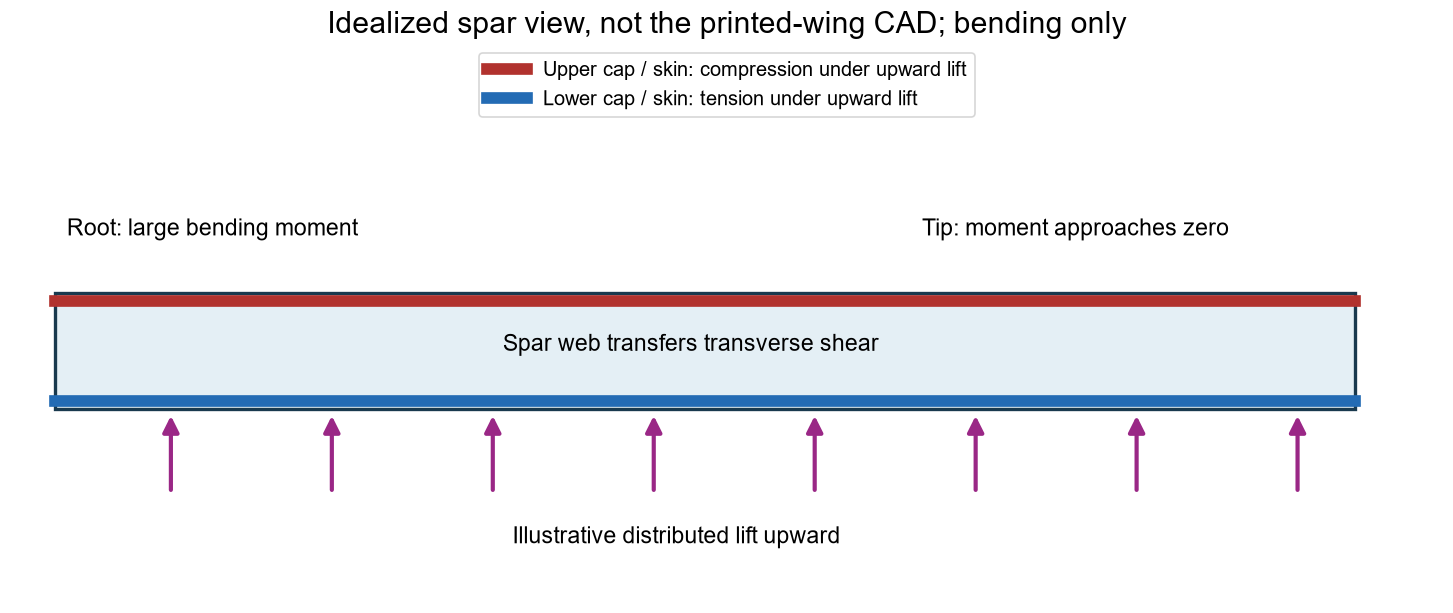

In [29]:
#@title Figure 8 — a wing spar turns bending into a separated force couple
fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
ax.add_patch(Rectangle((0,0),450,30,facecolor='#e4eff5',edgecolor='#19394e',lw=2))
ax.plot([0,450],[28,28],color='#b1322e',lw=7,label='Upper cap / skin: compression under upward lift')
ax.plot([0,450],[2,2],color='#236bb4',lw=7,label='Lower cap / skin: tension under upward lift')
for at in np.linspace(40,430,8): arrow(ax,(at,-22),(at,-1),'#9a2786')
ax.text(215,-35,'Illustrative distributed lift upward',ha='center')
ax.text(220,15,'Spar web transfers transverse shear',ha='center',fontsize=14)
ax.text(4,45,'Root: large bending moment',fontsize=14)
ax.text(300,45,'Tip: moment approaches zero',fontsize=14)
ax.set(xlim=(-15,480),ylim=(-50,95)); ax.axis('off'); ax.legend(loc='upper center',fontsize=12)
ax.set_title('Idealized spar view, not the printed-wing CAD; bending only')
plt.show()

### Optional orientation — distinguish a bending moment from torque

Use this as a visual bridge to a wing's twisting motion, not as a new 90-minute beam exercise. A vertical force on a spanwise lever produces bending; a tangential force with offset r from the longitudinal axis produces torque about that axis:

$$T=F_t r.$$

For a straight homogeneous circular tube under Saint-Venant torsion:

$$J=\frac{\pi}{2}(R_o^4-R_i^4),\qquad
\phi=\frac{T\ell}{GJ},\qquad \tau(r)=\frac{Tr}{J}.$$

The optional figure labels ℓ, outer radius Rₒ, inner radius Rᵢ, force Fₜ, lever r, torque T, axis x and rotation φ. G is the material shear modulus; J is calculated from the cross-sectional radii. This circular-tube formula does not apply to the rectangular teaching beam or directly to a multi-cell wing box. A torsional couple is not the sagging bending moment M in the earlier formulas.

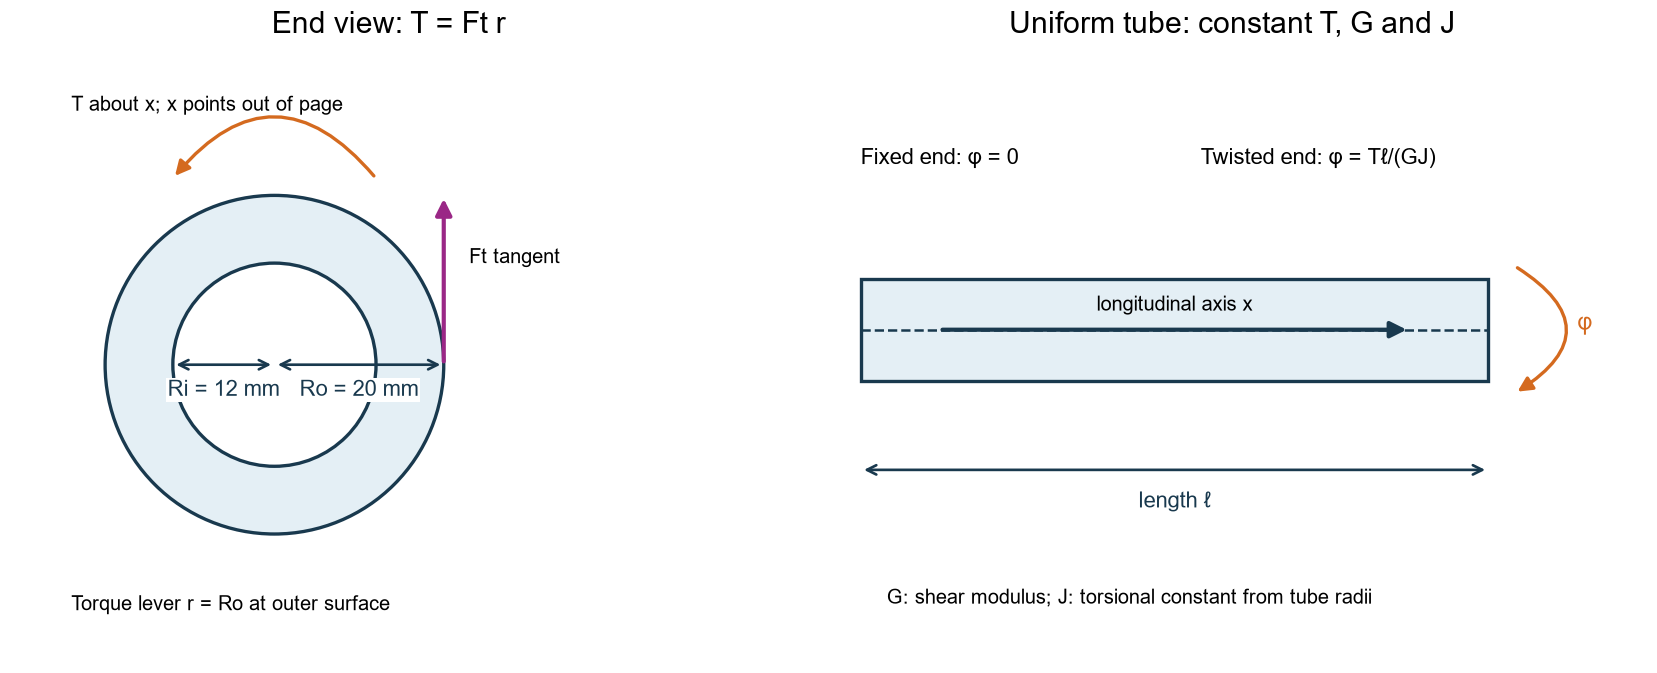

In [30]:
#@title Optional Figure 9 — torsion symbols on a circular tube, not the beam solver
fig,axes=plt.subplots(1,2,figsize=(14,5.5),layout='constrained')
ax=axes[0]
Ro,Ri=20.,12.
ax.add_patch(Circle((0,0),Ro,facecolor='#e4eff5',edgecolor='#19394e',lw=2))
ax.add_patch(Circle((0,0),Ri,facecolor='white',edgecolor='#19394e',lw=2))
dimension(ax,(0,0),(Ro,0),'Ro = 20 mm',(0,-3))
dimension(ax,(0,0),(-Ri,0),'Ri = 12 mm',(0,-3))
arrow(ax,(Ro,0),(Ro,20),'#9a2786');ax.text(23,12,'Ft tangent',fontsize=12)
ax.add_patch(FancyArrowPatch((12,22),(-12,22),connectionstyle='arc3,rad=.6',
                            arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
ax.text(-24,30,'T about x; x points out of page',fontsize=12)
ax.text(-24,-29,'Torque lever r = Ro at outer surface',fontsize=12)
ax.set(xlim=(-31,58),ylim=(-35,38),title='End view: T = Ft r');ax.set_aspect('equal');ax.axis('off')
ax=axes[1]
ax.add_patch(Rectangle((0,-8),120,16,facecolor='#e4eff5',edgecolor='#19394e',lw=2))
ax.plot([0,120],[0,0],'--',color='#19394e')
dimension(ax,(0,-22),(120,-22),'length ℓ',(0,-5))
arrow(ax,(15,0),(105,0),'#19394e');ax.text(60,3,'longitudinal axis x',ha='center',fontsize=12)
ax.text(0,26,'Fixed end: φ = 0',fontsize=13)
ax.text(65,26,'Twisted end: φ = Tℓ/(GJ)',fontsize=13)
ax.add_patch(FancyArrowPatch((125,10),(125,-10),connectionstyle='arc3,rad=-.8',
                            arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
ax.text(137,0,'φ',fontsize=14,color='#d46a1f')
ax.text(5,-43,'G: shear modulus; J: torsional constant from tube radii',fontsize=12)
ax.set(xlim=(-8,150),ylim=(-52,45),title='Uniform tube: constant T, G and J');ax.axis('off')
plt.show()

### HW 3 manual model setup

Open the blank [Beam Lab](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html) and enter the supports, section, material and line load from the [HW 3 handout](https://github.com/Ehsan-Roohi/Aerospace-Structures/blob/main/assignments/homework-03/README.md). Clear unwanted loads, supports and hinges, leave self-weight off and use Requested elements = 30. No homework preset or convergence table is provided or required. Solve after editing inputs and read the exact station table.


## 7. A determinate truss warm-up for HW 4

This small triangle is a practice model, **not the Flyer geometry or the answer to HW 4**. It introduces the joint equilibrium and output checks used in that assignment. Use the HW 4 handout for its geometry, lift and materials.

Take joints A = (0, 0), B = (400, 0), C = (200, 150), in mm. Connect AB, AC and BC. A is a pin (x and y restrained); B is a horizontal-ground roller (y restrained, x free). Apply P = 100 N **downward** at C. Every member has E = 70,000 MPa and area Aₘ = 50 mm². Neglect member weight. Members are straight, axial, pin-jointed and linearly elastic; positive axial force means tension. The vertical coordinate y is upward, unlike the beam's downward-positive displacement v.

### First find forces using equilibrium

The two inclined lengths are 250 mm; their direction cosines have magnitudes 200/250 = 0.8 and 150/250 = 0.6. Draw the supported triangle, then replace its supports with reactions. Taking moments about A:

$$400R_{By}-100(200)=0,\qquad R_{By}=50\ \mathrm{N}.$$

Vertical and horizontal equilibrium give Rₐᵧ = 50 N upward and Rₐₓ = 0. At C, assume both inclined member forces point away from the joint (tension). Symmetry and vertical balance give:

$$-0.6N_{AC}-0.6N_{BC}-100=0,\qquad N_{AC}=N_{BC}=-83.3333\ \mathrm{N}.$$

The negative answers mean **compression**, not a negative material property. At A, horizontal equilibrium gives:

$$N_{AB}+0.8N_{AC}=0,\qquad N_{AB}=66.6667\ \mathrm{N}\quad\text{(tension)}.$$

There are j = 3 joints, m = 3 members and r = 3 reaction components, so m + r = 2j = 6. This non-collinear triangle is stable and statically determinate: equilibrium finds its reactions and member forces without an extra compatibility equation. The count alone does not prove stability for an arbitrary arrangement.

### Then integrate axial strain to find each member's extension

Let s measure distance along a member; Aₘ is its cross-sectional area, not joint A. Axial stress and strain give:

$$\sigma=\frac{N}{A_m},\qquad \varepsilon=\frac{\sigma}{E}=\frac{N}{EA_m},\qquad
\Delta\ell=\int_0^{\ell}\varepsilon(s)\,ds.$$

With no distributed axial load, N is constant along each member. Here E and Aₘ are also constant, so:

$$\Delta\ell=\frac{N}{EA_m}\int_0^{\ell}1\,ds
=\frac{N}{EA_m}[s]_0^{\ell}=\frac{N\ell}{EA_m}.$$

The unit check is (N × mm)/(N/mm² × mm²) = mm. Thus:

$$\Delta\ell_{AB}=\frac{66.6667(400)}{70000(50)}=0.00761905\ \mathrm{mm},$$

$$\Delta\ell_{AC}=\Delta\ell_{BC}=\frac{-83.3333(250)}{70000(50)}=-0.00595238\ \mathrm{mm}.$$

An extension is positive; shortening is negative. These are **member length changes**, not directly the vertical displacement of C. To connect them, use small-displacement geometry:

$$\Delta\ell_{ij}=c(u_{jx}-u_{ix})+s(u_{jy}-u_{iy}),$$

where c and s are signed direction cosines from i to j. The restraints give uₐₓ = uₐᵧ = u<sub>By</sub> = 0. Member AB gives u<sub>Bx</sub> = 0.00761905 mm. Applying the length-change relation to AC and BC gives:

$$0.8u_{Cx}+0.6u_{Cy}=-0.00595238,$$

$$-0.8(u_{Cx}-0.00761905)+0.6u_{Cy}=-0.00595238.$$

Subtracting the equations gives u꜀ₓ = 0.00380952 mm; substitution gives u꜀ᵧ = −0.0150000 mm, or **0.015 mm downward**. C has a small horizontal motion because the roller at B permits the base to extend. Do not set u꜀ₓ to zero merely because the drawing is symmetric.

Compatibility was needed to connect extensions to joint motion; it was **not an additional equation needed to determine these member forces**. For varying E, area or axial force, keep those functions inside the strain integral and split it at their changes.

Member   N (N)     stress (MPa)   extension (mm)
AB      66.66667      1.333333      0.00761905
AC     -83.33333     -1.666667     -0.00595238
BC     -83.33333     -1.666667     -0.00595238
Reactions Ax, Ay, By (N): [-1.42108547e-14  5.00000000e+01  5.00000000e+01]
C displacement (mm): ux=0.00380952, uy=-0.01500000
Maximum free-joint force residual: 1.42e-14 N


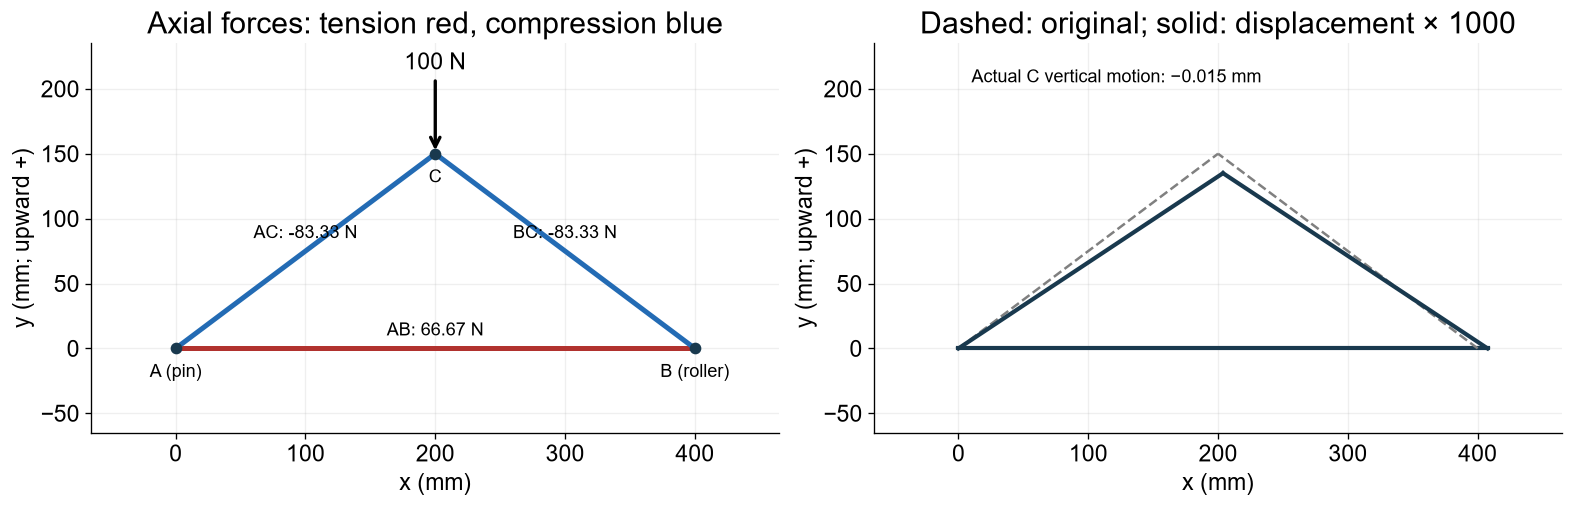

In [31]:
#@title Truss warm-up — independent stiffness solution and deflected shape
t_xy = np.array([[0., 0.], [400., 0.], [200., 150.]])
t_members = [(0, 1), (0, 2), (1, 2)]
t_names = ['AB', 'AC', 'BC']
t_E, t_area = 70000., 50.
t_K = np.zeros((6, 6)); t_f = np.zeros(6); t_f[5] = -100.
t_parts = []
for t_i, t_j in t_members:
    t_vector = t_xy[t_j] - t_xy[t_i]
    t_length = np.linalg.norm(t_vector)
    t_c, t_s = t_vector / t_length
    t_B = np.array([-t_c, -t_s, t_c, t_s])
    t_dofs = np.array([2*t_i, 2*t_i+1, 2*t_j, 2*t_j+1])
    t_K[np.ix_(t_dofs, t_dofs)] += t_E*t_area/t_length*np.outer(t_B, t_B)
    t_parts.append((t_length, t_B, t_dofs))
t_fixed = np.array([0, 1, 3]); t_free = np.array([2, 4, 5])
assert np.linalg.matrix_rank(t_K[np.ix_(t_free, t_free)]) == len(t_free)
t_u = np.zeros(6)
t_u[t_free] = np.linalg.solve(t_K[np.ix_(t_free, t_free)], t_f[t_free])
t_reaction = t_K @ t_u - t_f
t_extension = np.array([t_B @ t_u[t_dofs] for t_length, t_B, t_dofs in t_parts])
t_N = np.array([t_E*t_area/t_length*t_extension[k] for k, (t_length, _, _) in enumerate(t_parts)])
assert np.allclose(t_N, [200/3, -250/3, -250/3])
assert np.allclose(t_reaction[t_fixed], [0, 50, 50])
assert np.allclose(t_u[[2, 4, 5]], [0.007619047619, 0.003809523810, -0.015])
assert np.max(np.abs(t_reaction[t_free])) < 1e-9
print('Member   N (N)     stress (MPa)   extension (mm)')
for t_name, t_force, t_delta in zip(t_names, t_N, t_extension):
    print(f'{t_name:5s} {t_force:10.5f} {t_force/t_area:13.6f} {t_delta:15.8f}')
print(f'Reactions Ax, Ay, By (N): {t_reaction[t_fixed]}')
print(f'C displacement (mm): ux={t_u[4]:.8f}, uy={t_u[5]:.8f}')
print(f'Maximum free-joint force residual: {np.max(abs(t_reaction[t_free])):.2e} N')
t_scale = 1000.
t_moved = t_xy + t_scale*t_u.reshape(-1, 2)
fig, t_axes = plt.subplots(1, 2, figsize=(13, 5.8), layout='constrained')
for t_k, (t_i, t_j) in enumerate(t_members):
    t_color = '#b1322e' if t_N[t_k] > 0 else '#236bb4'
    t_axes[0].plot(t_xy[[t_i, t_j], 0], t_xy[[t_i, t_j], 1], color=t_color, lw=3)
    t_mid = (t_xy[t_i]+t_xy[t_j])/2
    t_axes[0].text(t_mid[0], t_mid[1]+10, f'{t_names[t_k]}: {t_N[t_k]:.2f} N', ha='center', fontsize=11)
    t_axes[1].plot(t_xy[[t_i, t_j], 0], t_xy[[t_i, t_j], 1], '--', color='gray', lw=1.5)
    t_axes[1].plot(t_moved[[t_i, t_j], 0], t_moved[[t_i, t_j], 1], color='#19394e', lw=2.5)
for t_k, t_name in enumerate(['A (pin)', 'B (roller)', 'C']):
    t_axes[0].plot(*t_xy[t_k], 'o', color='#19394e')
    t_axes[0].text(t_xy[t_k, 0], t_xy[t_k, 1]-22, t_name, ha='center', fontsize=11)
t_axes[0].annotate('100 N', xy=t_xy[2], xytext=(200, 215), ha='center', arrowprops=dict(arrowstyle='->', color='black', lw=2))
for t_ax in t_axes:
    t_ax.set(xlim=(-65, 465), ylim=(-65, 235), xlabel='x (mm)', ylabel='y (mm; upward +)')
    t_ax.set_aspect('equal'); t_ax.grid(alpha=.2)
t_axes[0].set_title('Axial forces: tension red, compression blue')
t_axes[1].set_title('Dashed: original; solid: displacement × 1000')
t_axes[1].text(10, 205, 'Actual C vertical motion: −0.015 mm', fontsize=11)
plt.show()

### Compare this truss with Truss Lab

Open [Truss Lab](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html#truss), enter these three joints and three **bar** members, and use the stated supports, E, area and downward force. Compare reactions, every axial force and stress, and C's numerical displacement. Record the magnification separately from the actual displacement. No mesh subdivision is needed to make these straight, end-loaded axial members exact within the linear truss model.

For HW 4, use its assigned half-wing geometry and loads instead. Its crossed cables are **tension-only**: a negative trial cable force cannot be retained as cable compression. Identify a stable active set, check any slack cables, and compare its reactions and member forces with software. Crossing lines are not automatically joints. Counting all drawn cables as active bars can give a misleading indeterminacy count.

**Optional extension for a larger truss:** an additional independent redundant member can make a stable truss statically indeterminate. Equilibrium then leaves a force undetermined; elastic extension and compatibility supply the extra relation. The triangle above already contains all three possible joint pairs—do not add a duplicate member and call it a new diagonal. Virtual work and energy methods for these displacement/compatibility calculations follow in Lecture 04.

## 8. Four-minute exit ticket and after-class practice

Submit one page with: a labelled free body; reaction unknowns and constraints; one equilibrium check; one moment-to-stress calculation; one deflection calculation; the app study record; and a sentence explaining the largest stress and displacement locations. Use units on every numerical result.

1. Why is root displacement zero while root stress can be largest?
2. Why do two 2 N loads have different moments and deflections?
3. Which extra information is needed for a fixed–fixed beam beyond equilibrium?
4. If an app returns zero deflection, where was the load placed and what motions were restrained?

**After class, not part of the 90-minute route:** change one parameter at a time. Predict and test P×2, E×2 and h×2. Then explore the triangle/trapezoid options from Lecture 02, keeping total force fixed. Reactions and stress checks should precede vibration modes.

### Reading and model scope

[TU Delft beam theory and finite elements](https://teachbooks.tudelft.nl/computational-modelling/structural_linear/euler_bernouilli.html) supports the equilibrium–curvature–boundary-condition framework. Our diagrams are original instructional illustrations. Numerical examples use declared assumed dimensions/material values and closed-form elastic beam solutions, independently checked against the course beam engine. Scope: straight, slender, homogeneous solid section; constant EI; ideal supports; linear elasticity and small displacement; no self-weight unless specified. This is not an airworthiness or printed-wing failure certification.